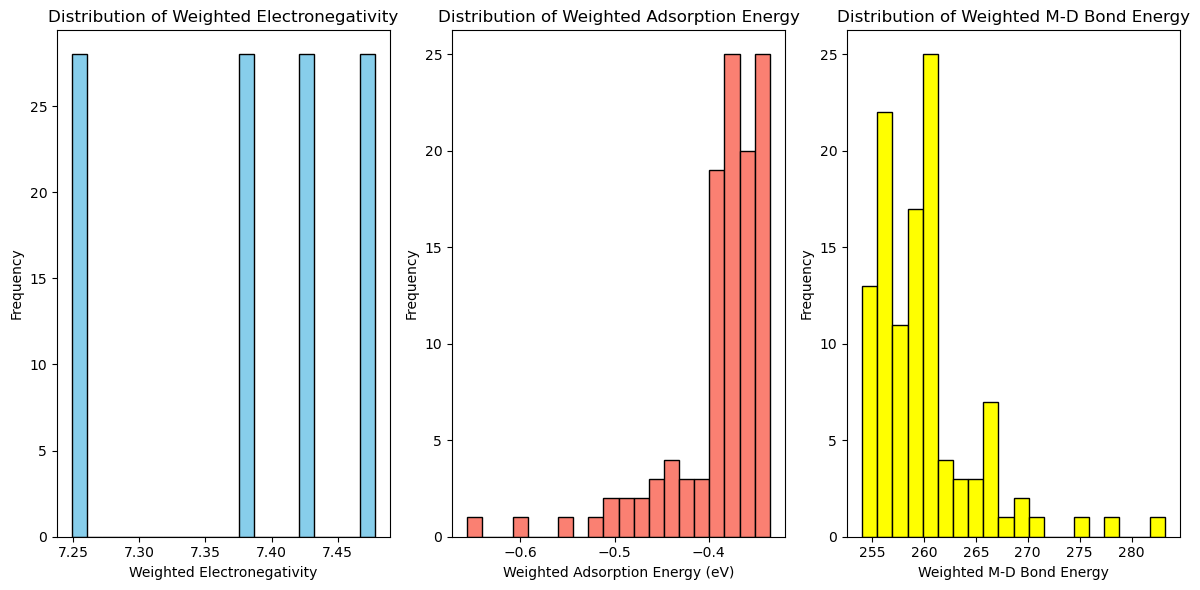

In [2]:
import os
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# =========================
# Paths
# =========================
BO_DIR = r"./"
EH_PATH = r"./EH_extra.xlsx"

# =========================
# Step 1: 每个 JSON → DataFrame → 合并
# =========================
dfs = []

for fp in sorted(glob.glob(os.path.join(BO_DIR, "*.json"))):
    with open(fp, "r", encoding="utf-8") as f:
        obj = json.load(f)

    # ⭐ 关键：你的 JSON = 列字典
    df_i = pd.DataFrame(obj)
    df_i["_source_file"] = os.path.basename(fp)
    dfs.append(df_i)

if not dfs:
    raise RuntimeError("No valid JSON files loaded.")

df = pd.concat(dfs, ignore_index=True)

# =========================
# Step 2: 计算百分含量
# =========================
for col in ["volume1", "volume2", "separation_coefficient"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

denom = df["volume1"] + df["volume2"]
df["frac1"] = df["volume1"] / denom
df["frac2"] = df["volume2"] / denom

df.loc[denom == 0, ["frac1", "frac2"]] = np.nan

# =========================
# Step 3: 读取 EH_extra.xlsx → 电负性映射
# =========================
eh = pd.read_excel(EH_PATH)

metal_col = eh.columns[0]  # 第一列是 metal
if "electronegativity" not in eh.columns:
    raise KeyError("EH_extra.xlsx 中未找到 electronegativity 列")

eh_map = (
    eh[[metal_col, "electronegativity"]]
    .dropna()
    .assign(**{metal_col: lambda x: x[metal_col].astype(str).str.strip()})
    .set_index(metal_col)["electronegativity"]
    .to_dict()
)

df["substance1"] = df["substance1"].astype(str).str.strip()
df["substance2"] = df["substance2"].astype(str).str.strip()

df["en1"] = df["substance1"].map(eh_map)
df["en2"] = df["substance2"].map(eh_map)

# =========================
# Step 4: 计算加权电负性
# =========================
df["weighted_electronegativity"] = (
    df["en1"] * df["frac1"] + df["en2"] * df["frac2"]
)

# =========================
# Step 5: 读取并合并“Sheet2”中的吸附自由能数据
# =========================
sheet2 = pd.read_excel(EH_PATH, sheet_name="Sheet2")
sheet2 = sheet2.rename(columns={"Unnamed: 0": "element"})
sheet2["element"] = sheet2["element"].ffill()  # Fill the metal column if missing
ads_avg = (
    sheet2.groupby("element")["Free Energy of Adsorption (eV)"]
    .mean()
    .reset_index()
    .rename(columns={"Free Energy of Adsorption (eV)": "FE_ads_avg"})
)

# Merge averaged adsorption data with the existing dataframe for both substances
df = pd.merge(df, ads_avg, left_on="substance1", right_on="element", how="left")
df = pd.merge(df, ads_avg, left_on="substance2", right_on="element", how="left", suffixes=('_substance1', '_substance2'))

# Fill missing values with 0 (or NaN based on your preference)
df["FE_ads_avg_substance1"] = df["FE_ads_avg_substance1"].fillna(0)
df["FE_ads_avg_substance2"] = df["FE_ads_avg_substance2"].fillna(0)

# =========================
# Step 6: 计算加权吸附自由能 (Weighted Adsorption Energy)
# =========================
df["weighted_FE_ads_avg"] = (
    df["FE_ads_avg_substance1"] * df["frac1"] + df["FE_ads_avg_substance2"] * df["frac2"]
)

# =========================
# Step 7: 读取 EH_extra.xlsx → M-D映射
# =========================
metal_col = eh.columns[0]  # 第一列是 metal
if "E(M-D) (kJ/mol)" not in eh.columns:
    raise KeyError("EH_extra.xlsx 中未找到 E(M-D) (kJ/mol) 列")

eh_map = (
    eh[[metal_col, "E(M-D) (kJ/mol)"]]
    .dropna()
    .assign(**{metal_col: lambda x: x[metal_col].astype(str).str.strip()})
    .set_index(metal_col)["E(M-D) (kJ/mol)"]
    .to_dict()
)

df["substance1"] = df["substance1"].astype(str).str.strip()
df["substance2"] = df["substance2"].astype(str).str.strip()

df["md1"] = df["substance1"].map(eh_map)
df["md2"] = df["substance2"].map(eh_map)

# =========================
# Step 8: 计算加权M-D键能
# =========================
df["weighted_M-D_bond_energy"] = (
    df["md1"] * df["frac1"] + df["md2"] * df["frac2"]
)


# =========================
# Step 7: 作图 + 相关系数
# =========================
plot_df = df[["weighted_electronegativity", "separation_coefficient", "weighted_FE_ads_avg","weighted_M-D_bond_energy"]].dropna()

# Plot the distribution of weighted electronegativity and weighted FE_ads_avg
plt.figure(figsize=(12, 6))

# Weighted electronegativity distribution
plt.subplot(1, 3, 1)
plt.hist(plot_df["weighted_electronegativity"], bins=20, color='skyblue', edgecolor='black')
plt.xlabel("Weighted Electronegativity")
plt.ylabel("Frequency")
plt.title("Distribution of Weighted Electronegativity")

# Weighted Adsorption Energy distribution
plt.subplot(1, 3, 2)
plt.hist(plot_df["weighted_FE_ads_avg"], bins=20, color='salmon', edgecolor='black')
plt.xlabel("Weighted Adsorption Energy (eV)")
plt.ylabel("Frequency")
plt.title("Distribution of Weighted Adsorption Energy")

# Weighted Adsorption Energy distribution
plt.subplot(1, 3, 3)
plt.hist(plot_df["weighted_M-D_bond_energy"], bins=20, color='yellow', edgecolor='black')
plt.xlabel("Weighted M-D Bond Energy")
plt.ylabel("Frequency")
plt.title("Distribution of Weighted M-D Bond Energy")

plt.tight_layout()
plt.show()

# =========================
# （可选）保存完整结果
# =========================
# out_path = os.path.join(BO_DIR, "merged_weighted_electronegativity_adsorption.xlsx")
# df.to_excel(out_path, index=False)


In [3]:
df

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,syn_completed,storage_location,...,en2,weighted_electronegativity,element_substance1,FE_ads_avg_substance1,element_substance2,FE_ads_avg_substance2,weighted_FE_ads_avg,md1,md2,weighted_M-D_bond_energy
0,Co,4.0,Mo,7.0,Na3Cit,3.37,water,5.63,True,0.0,...,2.16,2.058182,Co,-0.333333,Mo,-0.526667,-0.456364,256.787601,270.093379,265.254914
1,Co,4.0,Mo,13.0,Na3Cit,2.85,water,0.15,True,1.0,...,2.16,2.094118,Co,-0.333333,Mo,-0.526667,-0.481176,256.787601,270.093379,266.962608
2,Co,7.0,Mo,4.0,Na3Cit,6.59,water,2.41,True,2.0,...,2.16,1.981818,Co,-0.333333,Mo,-0.526667,-0.403636,256.787601,270.093379,261.626065
3,Co,15.0,Mo,2.5,Na3Cit,2.50,water,0.00,True,3.0,...,2.16,1.920000,Co,-0.333333,Mo,-0.526667,-0.360952,256.787601,270.093379,258.688426
4,Co,13.0,Mo,4.0,Na3Cit,1.80,water,1.20,True,4.0,...,2.16,1.945882,Co,-0.333333,Mo,-0.526667,-0.378824,256.787601,270.093379,259.918372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,Fe,1.0,Ni,1.0,Na3Cit,18.00,water,0.00,True,3.0,...,1.92,1.875000,Fe,-0.396667,Ni,-0.370000,-0.383333,261.359080,253.899598,257.629339
124,Fe,15.0,Ni,2.5,Na3Cit,2.50,water,0.00,None,NaN,...,1.92,1.842857,Fe,-0.396667,Ni,-0.370000,-0.392857,261.359080,253.899598,260.293439
125,Fe,1.0,Ni,7.7,Na3Cit,11.30,water,0.00,None,NaN,...,1.92,1.909655,Fe,-0.396667,Ni,-0.370000,-0.373065,261.359080,253.899598,254.757010
126,Fe,1.0,Ni,10.9,Na3Cit,8.10,water,0.00,None,NaN,...,1.92,1.912437,Fe,-0.396667,Ni,-0.370000,-0.372241,261.359080,253.899598,254.526445


In [4]:
df.to_excel("weighted_BO.xlsx")

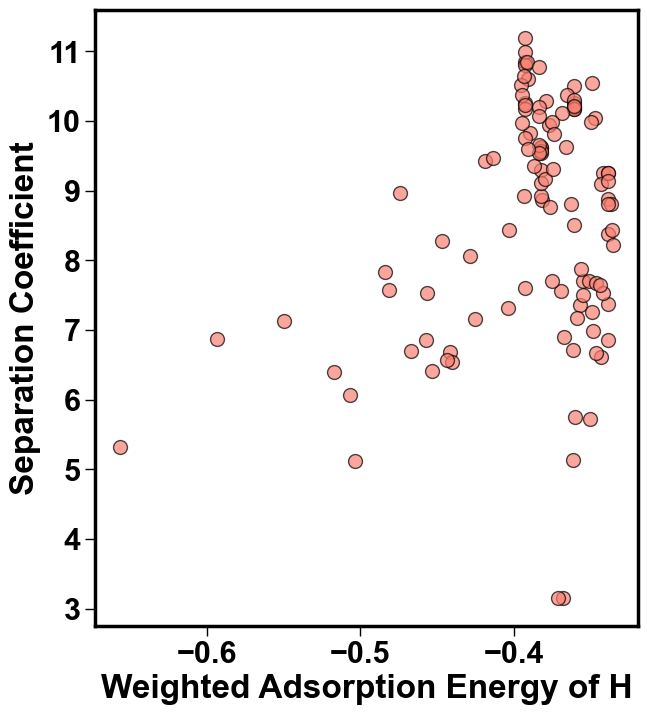

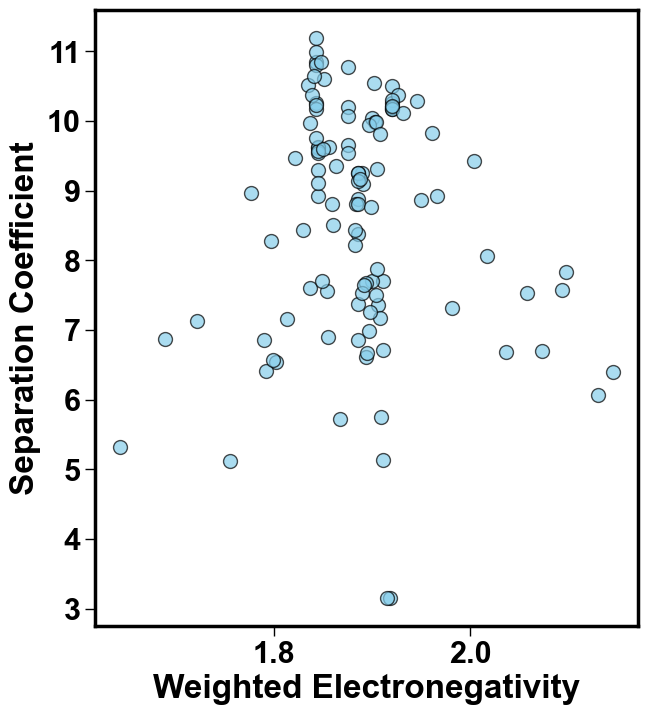

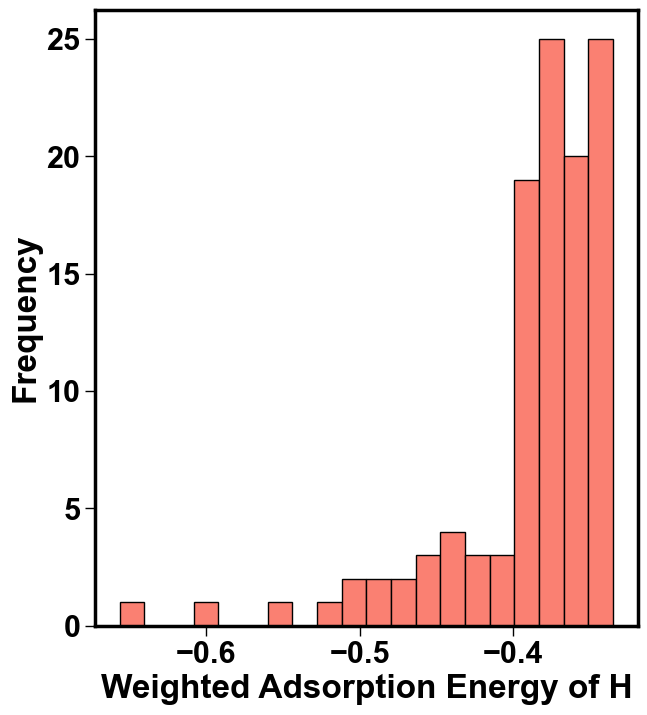

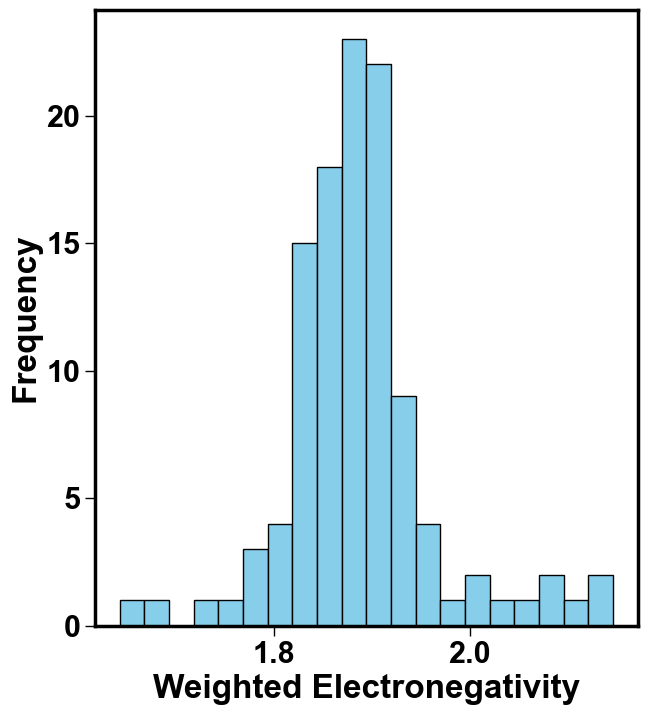

In [5]:
import matplotlib.pyplot as plt
# Set Arial Bold for all plot text elements (labels, ticks, titles)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.linewidth'] = 2.5  # Increase the frame (border) thickness

# Set global settings for tick and label font size and weight
plt.rcParams['xtick.labelsize'] = 22  # Set the x-axis label size globally
plt.rcParams['ytick.labelsize'] = 22  # Set the y-axis label size globally
plt.rcParams['axes.labelsize'] = 26  # Set the axis label size globally
plt.rcParams['axes.labelweight'] = 'bold'  # Set the axis label weight to bold globally
plt.rcParams['xtick.major.width'] = 1.0  # Set the width of major x-ticks
plt.rcParams['ytick.major.width'] = 1.0  # Set the width of major y-ticks
plt.rcParams['xtick.major.size'] = 7  # Set the size of major x-ticks
plt.rcParams['ytick.major.size'] = 7  # Set the size of major y-ticks

# Now, when you create your plots, they will automatically apply these settings

# Subplot 1: Scatter plot of Weighted Adsorption Energy vs Separation Coefficient
plt.figure(figsize=(7, 8))
plt.scatter(plot_df["weighted_FE_ads_avg"], plot_df["separation_coefficient"], alpha=0.7, color='salmon', s=100, linewidths=1.0, edgecolors="black")
plt.xlabel("Weighted Adsorption Energy of H", fontsize=24, fontweight='bold')
plt.ylabel("Separation Coefficient", fontsize=24, fontweight='bold')
plt.savefig("scatter_plot_weighted_FE_ads_avg_vs_separation_coefficient.png", dpi=600, bbox_inches='tight')  # Save the first plot
plt.show()  # Show the first plot

# Subplot 2: Scatter plot of Weighted Electronegativity vs Separation Coefficient
plt.figure(figsize=(7, 8))
plt.scatter(plot_df["weighted_electronegativity"], plot_df["separation_coefficient"], alpha=0.7, color='skyblue', s=100, linewidths=1.0, edgecolors="black")
plt.xlabel("Weighted Electronegativity", fontsize=24, fontweight='bold')
plt.ylabel("Separation Coefficient", fontsize=24, fontweight='bold')
plt.savefig("scatter_plot_weighted_electronegativity_vs_separation_coefficient.png", dpi=600, bbox_inches='tight')  # Save the second plot
plt.show()  # Show the second plot

# Subplot 3: Histogram of Weighted Adsorption Energy
plt.figure(figsize=(7, 8))
plt.hist(plot_df["weighted_FE_ads_avg"], bins=20, color='salmon', edgecolor='black')
plt.xlabel("Weighted Adsorption Energy of H", fontsize=24, fontweight='bold')
plt.ylabel("Frequency", fontsize=24, fontweight='bold')
plt.savefig("histogram_weighted_FE_ads_avg.png", dpi=600, bbox_inches='tight')  # Save the third plot
plt.show()  # Show the third plot

# Subplot 4: Histogram of Weighted Electronegativity
plt.figure(figsize=(7, 8))
plt.hist(plot_df["weighted_electronegativity"], bins=20, color='skyblue', edgecolor='black')
plt.xlabel("Weighted Electronegativity", fontsize=24, fontweight='bold')
plt.ylabel("Frequency", fontsize=24, fontweight='bold')
plt.savefig("histogram_weighted_electronegativity.png", dpi=600, bbox_inches='tight')  # Save the fourth plot
plt.show()  # Show the fourth plot


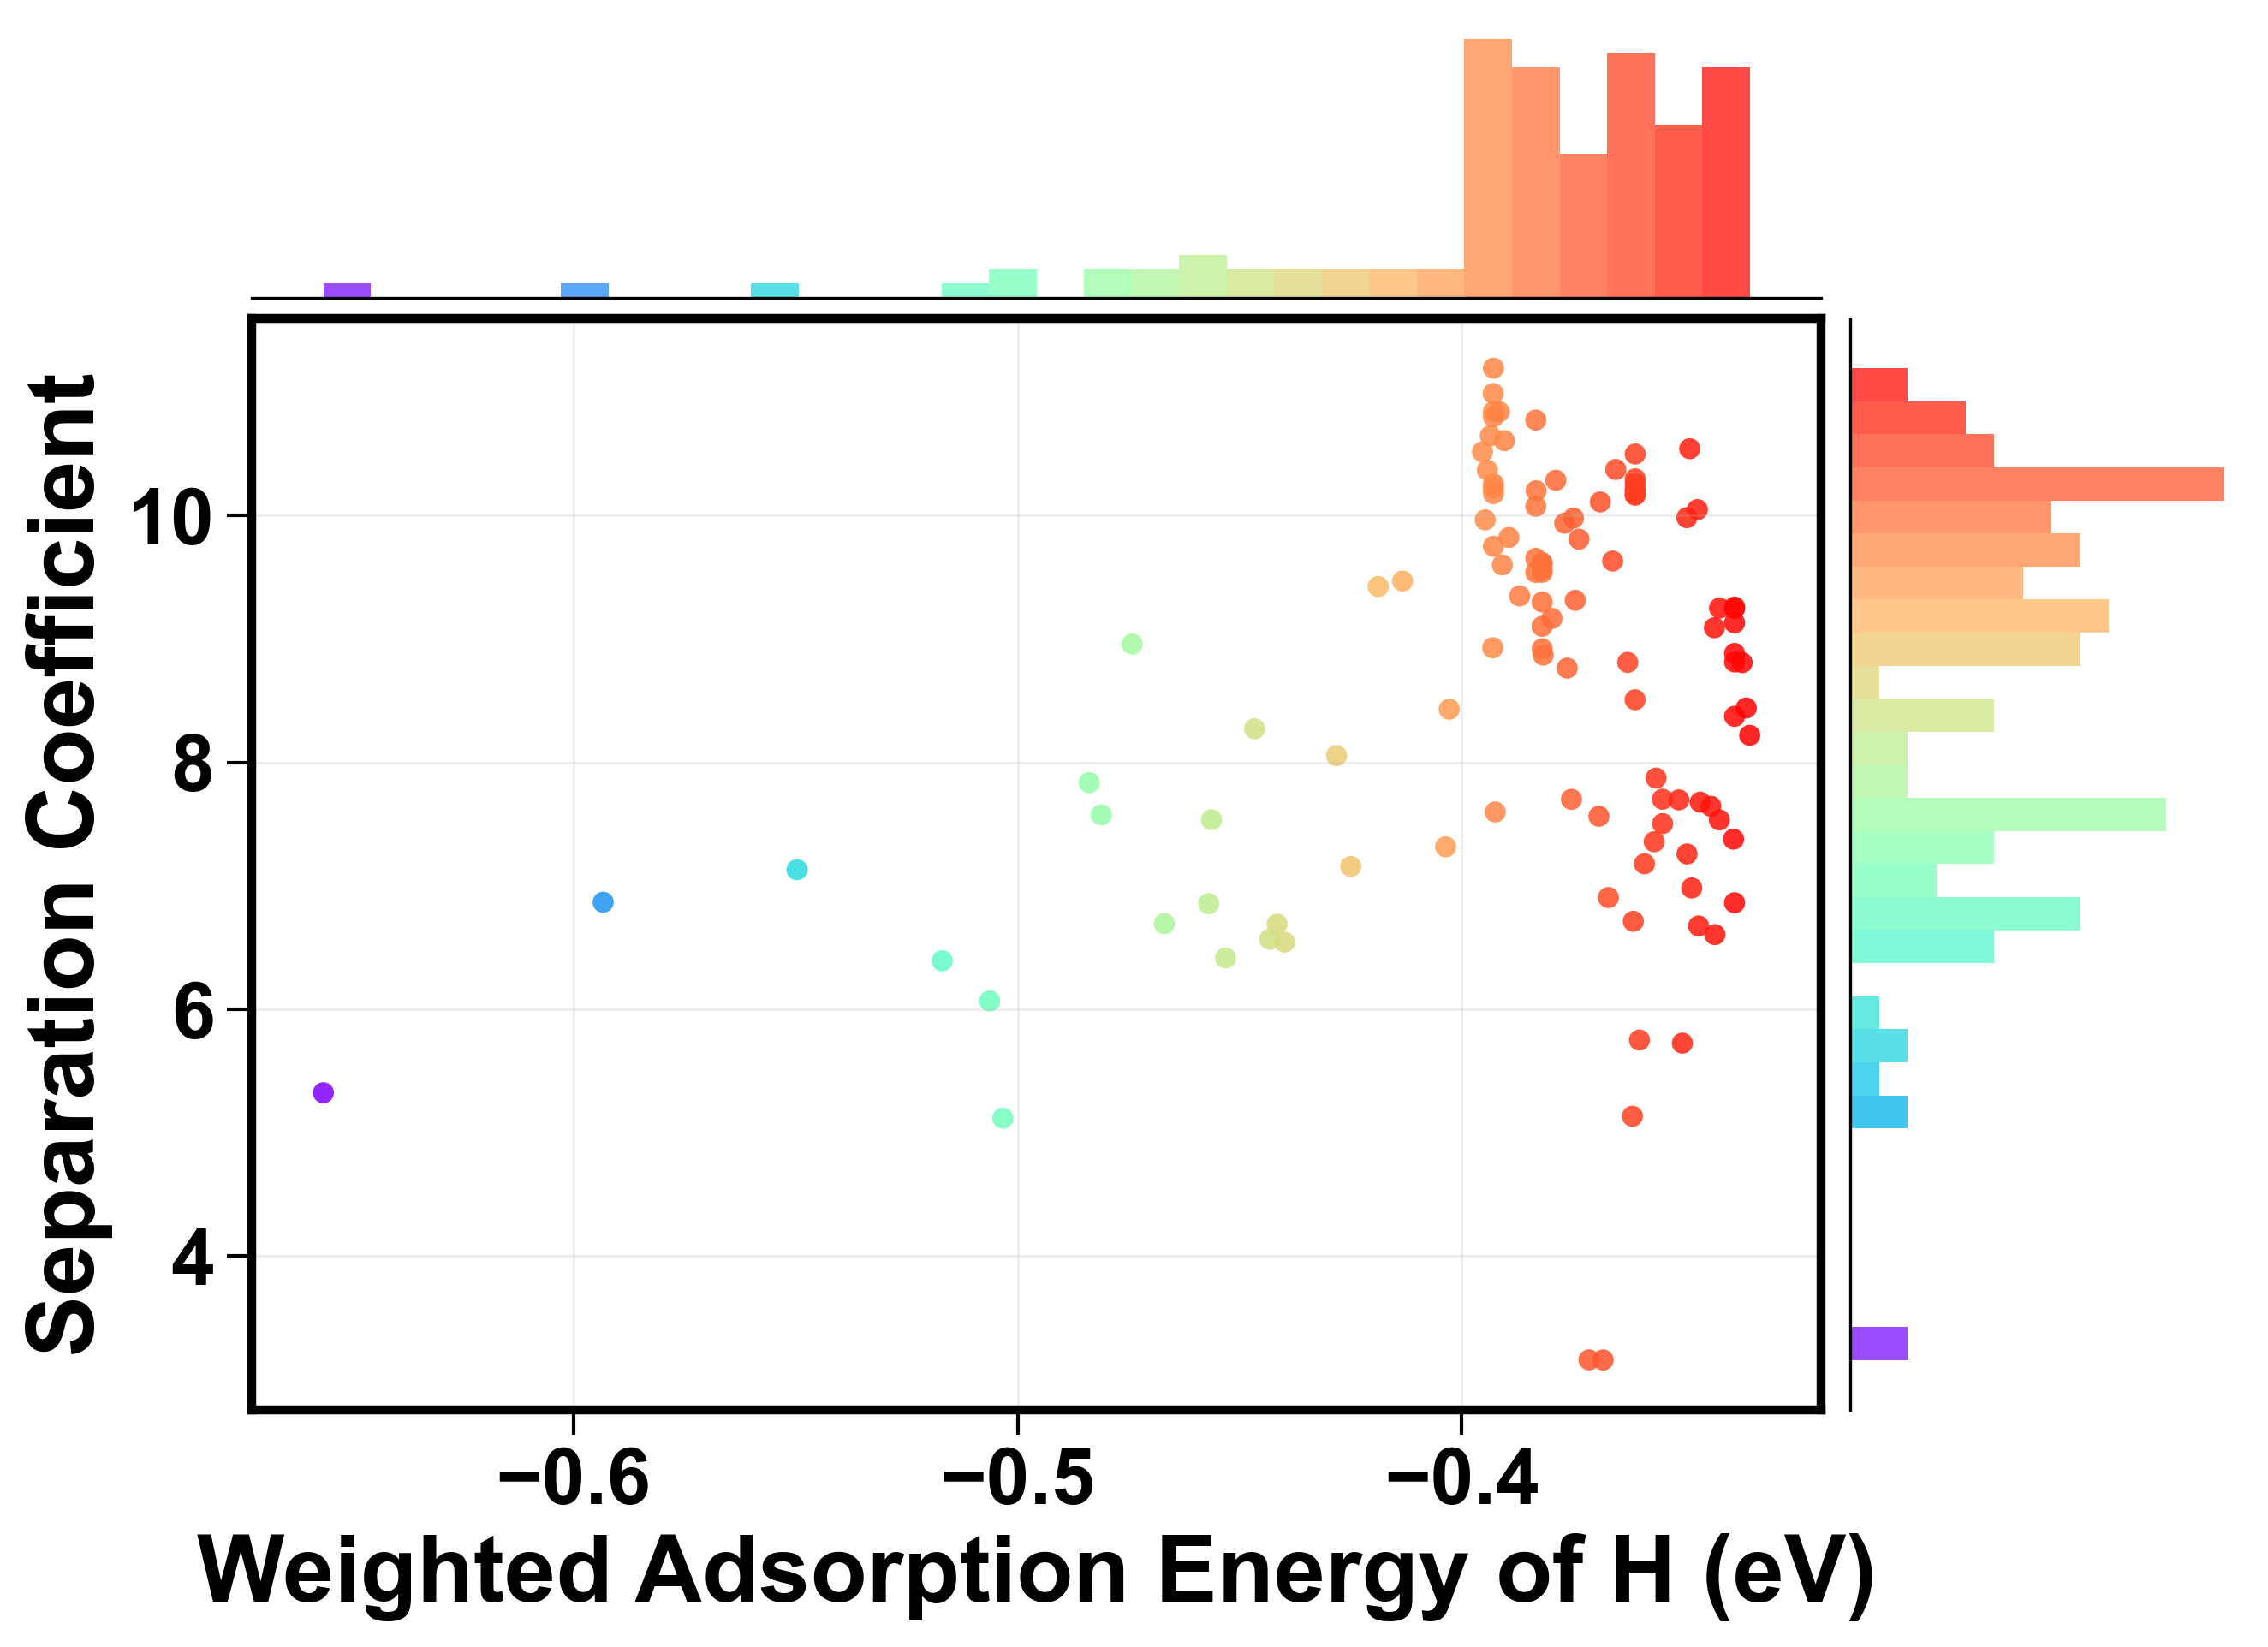

Saved: joint_scatter_marginals_keep_bottom_and_left.png


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# =========================
# 假设 plot_df 已经在你前面代码中生成好：
# plot_df = df[["weighted_electronegativity","separation_coefficient","weighted_FE_ads_avg"]].dropna()
# =========================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5
mpl.rcParams["xtick.labelsize"] = 22
mpl.rcParams["ytick.labelsize"] = 22
mpl.rcParams["axes.labelsize"] = 26
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"] = 7
mpl.rcParams["ytick.major.size"] = 7

# =========================
# 选择 X/Y 列
# =========================
X_COL = "weighted_FE_ads_avg"
Y_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)

# =========================
# 颜色：rainbow（按 x 上色）
# =========================
cmap = plt.cm.rainbow
norm = mpl.colors.Normalize(vmin=np.nanmin(x), vmax=np.nanmax(x))

# =========================
# 建图：主图 + 边缘直方图
# =========================
fig = plt.figure(figsize=(10, 7), dpi=300)
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.0, 4.0],
    width_ratios=[4.0, 1.0],
    hspace=0.03, wspace=0.03
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
ax_scatt.scatter(
    x, y,
    c=x, cmap=cmap, norm=norm,
    s=35, alpha=0.85,
    edgecolors="none"
)

ax_scatt.set_xlabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.set_ylabel("Separation Coefficient")

# 轻网格（不想要可删）
ax_scatt.grid(True, linewidth=0.6, alpha=0.25)

# =========================
# 上方 X 直方图（彩色 bin）
# =========================
bins_x = 30
counts_x, edges_x = np.histogram(x, bins=bins_x)
centers_x = 0.5 * (edges_x[:-1] + edges_x[1:])
widths_x = np.diff(edges_x)

for cx, w, h in zip(centers_x, widths_x, counts_x):
    ax_histx.bar(cx, h, width=w, color=cmap(norm(cx)), alpha=0.75, linewidth=0)

# 上方图：不要刻度/标签
ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

# ✅ 上方图：只保留下边线（bottom spine）
for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧 Y 直方图（水平柱 + 彩色）
# 这里颜色也用 rainbow，但随 y bin 位置渐变（映射到 x 的 norm 范围）
# =========================
bins_y = 30
counts_y, edges_y = np.histogram(y, bins=bins_y)
centers_y = 0.5 * (edges_y[:-1] + edges_y[1:])
heights_y = np.diff(edges_y)

# 把 y 的位置线性映射到 x 的取值范围，用来取 rainbow 颜色（保持整体一致的 rainbow 感）
y_to_x = np.interp(centers_y, (np.nanmin(y), np.nanmax(y)), (np.nanmin(x), np.nanmax(x)))

for cy, hh, w, fake_x in zip(centers_y, heights_y, counts_y, y_to_x):
    ax_histy.barh(cy, w, height=hh, color=cmap(norm(fake_x)), alpha=0.75, linewidth=0)

# 右侧图：不要刻度/标签
ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

# ✅ 右侧图：只保留左边线（left spine）
for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 输出
# =========================
out = "joint_scatter_marginals_keep_bottom_and_left.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)


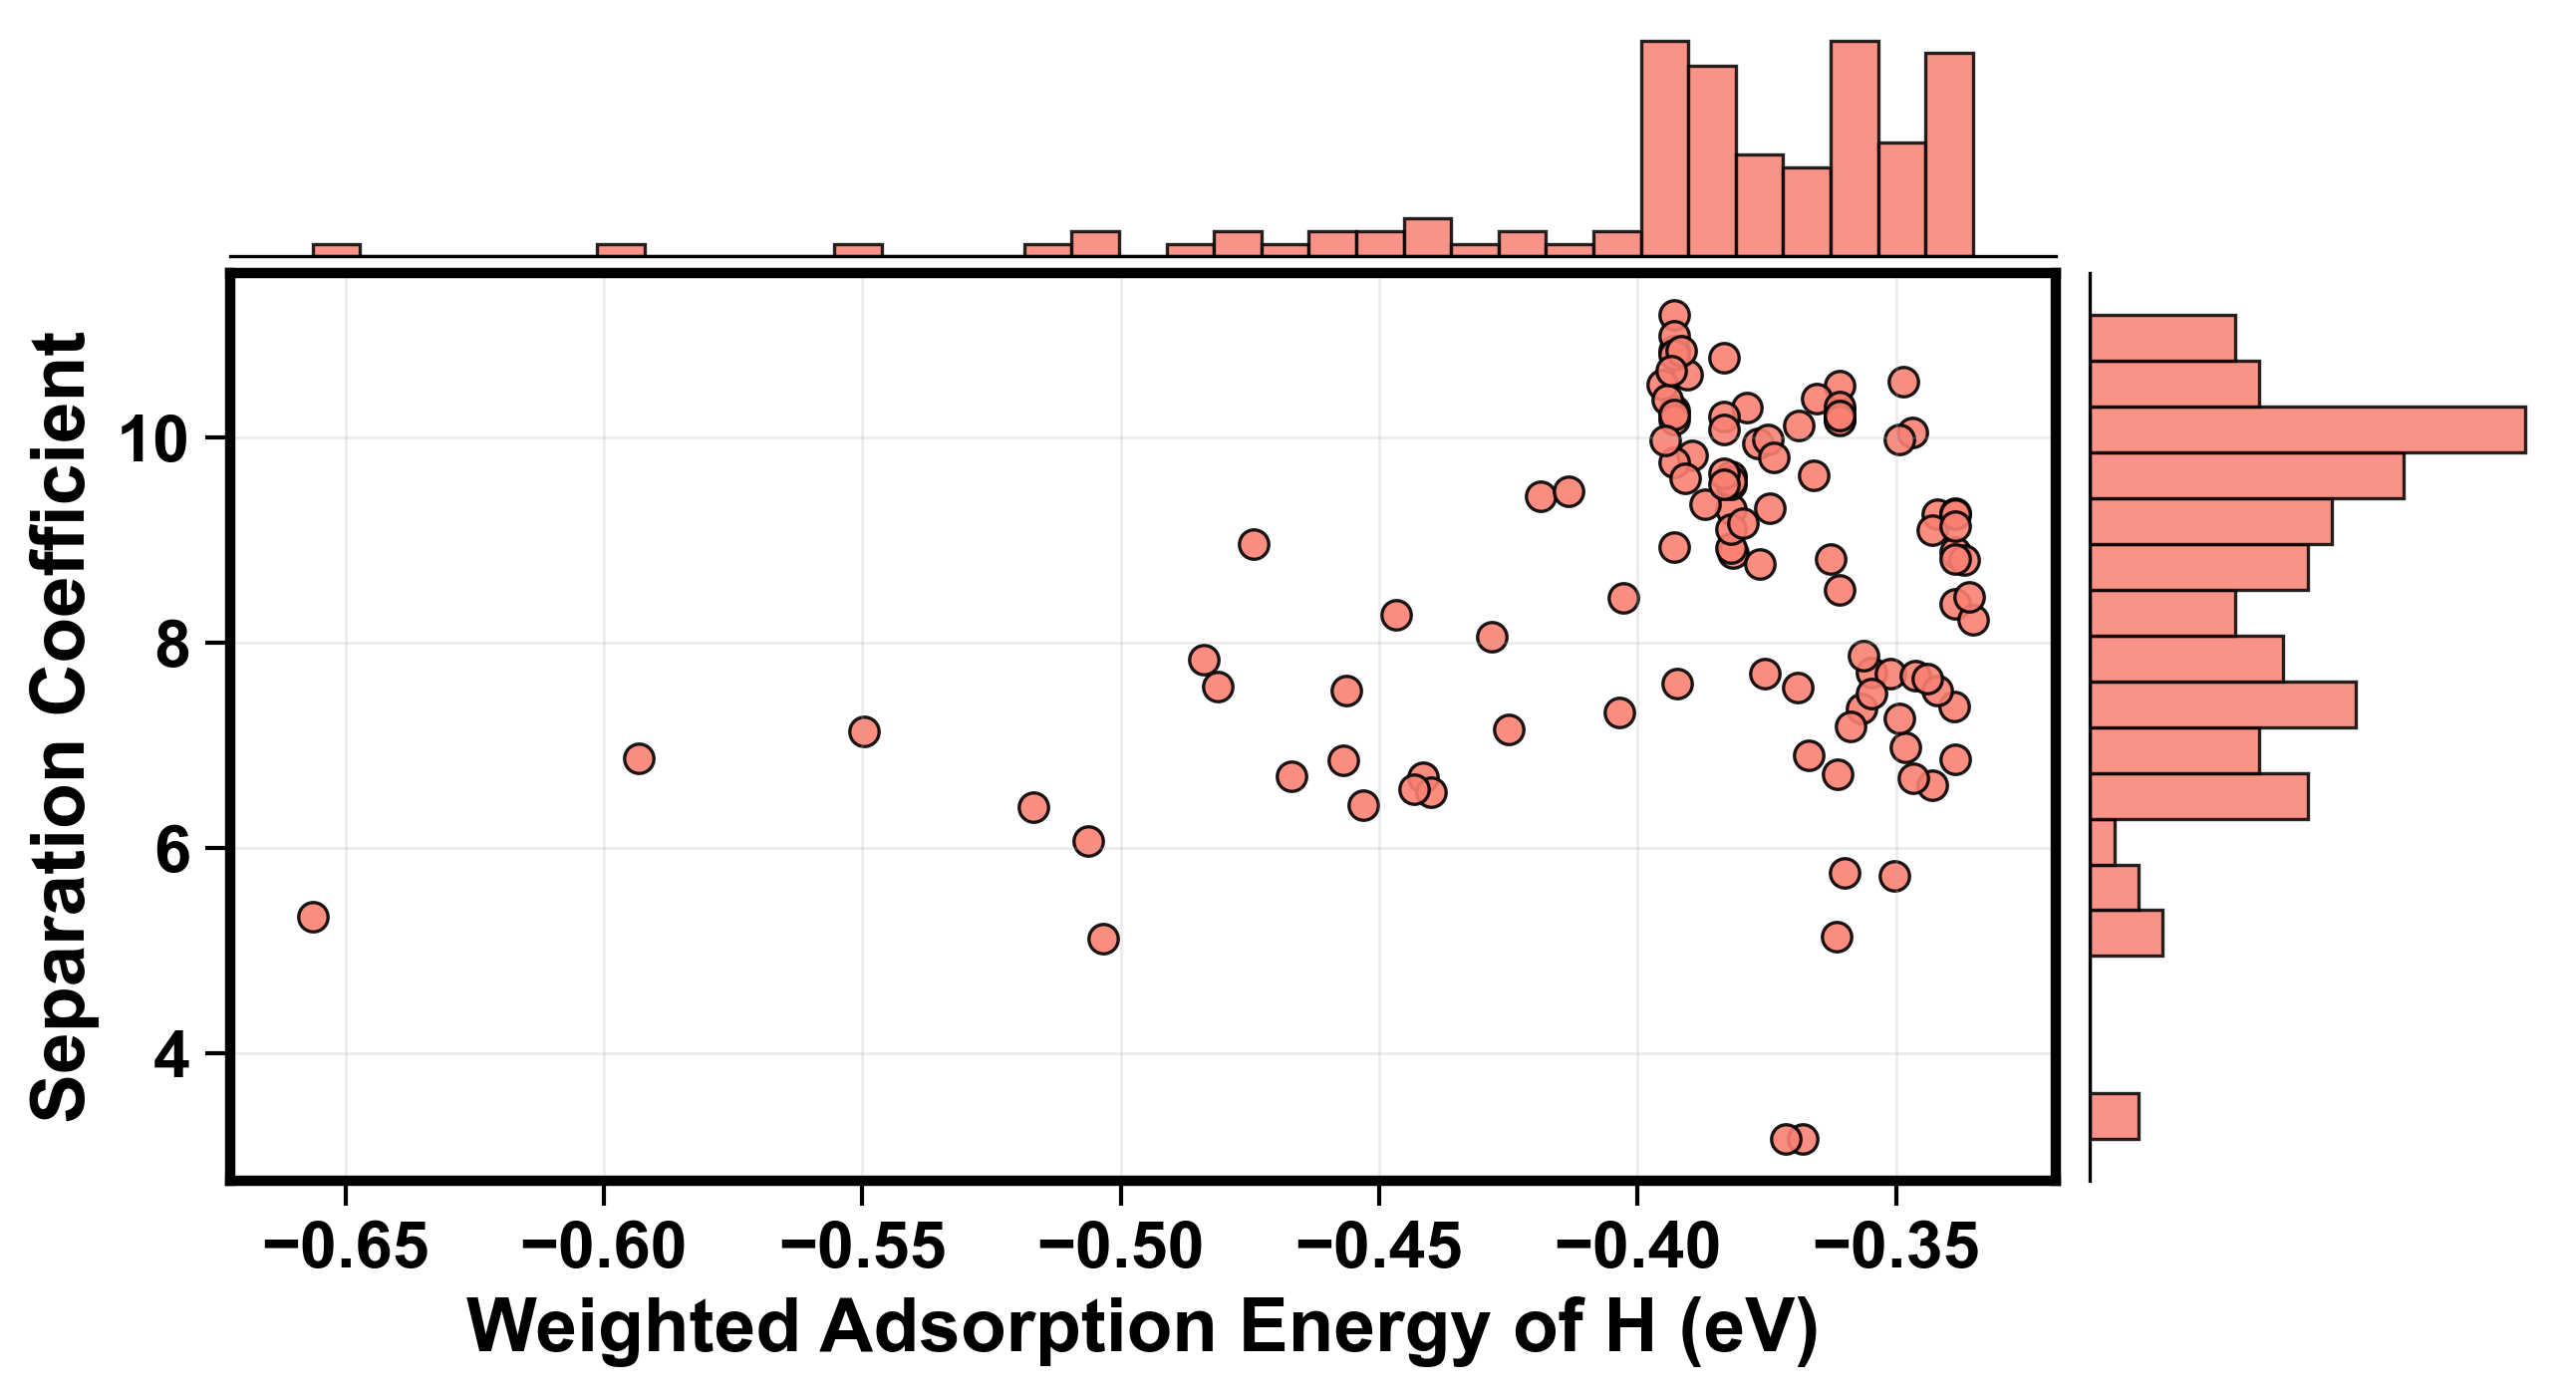

Saved: joint_scatter_marginals_lightred_blackedge.png


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# =========================
# 假设 plot_df 已经在你前面代码中生成好
# plot_df = df[[...]].dropna()
# =========================

# -------------------------
# 全局字体/线宽风格
# -------------------------
# 全局字体/线宽风格（更小一档）
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16   # 原 18
mpl.rcParams["ytick.labelsize"] = 16  # 原 18
mpl.rcParams["axes.labelsize"]  = 18   # 原 20
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6   # 可选：原 7，稍微小一点更协调
mpl.rcParams["ytick.major.size"]  = 6


# =========================
# 选择 X/Y 列
# =========================
X_COL = "weighted_FE_ads_avg"
Y_COL = "separation_coefficient"
x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)

# =========================
# 配色与描边（浅红 + 黑边）
# =========================
FILL_COLOR = "salmon"   # 浅红（你可再调浅：#f9b3b3 / #fbd0d0）
EDGE_COLOR = "black"
SCATTER_ALPHA = 0.90
HIST_ALPHA = 0.85

SCATTER_SIZE = 50
SCATTER_LW = 0.8
BAR_LW = 0.8

# =========================
# 建图：主图 + 边缘直方图
# =========================
fig = plt.figure(figsize=(10, 5), dpi=300)
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.0, 4.0],
    width_ratios=[4.0, 1.0],
    hspace=0.03, wspace=0.03
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图（浅红填充 + 黑圈）
# =========================
ax_scatt.scatter(
    x, y,
    s=SCATTER_SIZE,
    facecolors=FILL_COLOR,
    edgecolors=EDGE_COLOR,
    linewidths=SCATTER_LW,
    alpha=SCATTER_ALPHA
)

ax_scatt.set_xlabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.set_ylabel("Separation Coefficient")
ax_scatt.grid(True, linewidth=0.6, alpha=0.25)

# =========================
# 上方 X 直方图（浅红 + 黑边）
# =========================
bins_x = 35
counts_x, edges_x = np.histogram(x, bins=bins_x)
centers_x = 0.5 * (edges_x[:-1] + edges_x[1:])
widths_x = np.diff(edges_x)

ax_histx.bar(
    centers_x, counts_x, width=widths_x,
    color=FILL_COLOR, alpha=HIST_ALPHA,
    edgecolor=EDGE_COLOR, linewidth=BAR_LW
)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

# ✅ 上方图：只保留下边线
for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧 Y 直方图（浅红 + 黑边）
# =========================
bins_y = 18
counts_y, edges_y = np.histogram(y, bins=bins_y)
centers_y = 0.5 * (edges_y[:-1] + edges_y[1:])
heights_y = np.diff(edges_y)

ax_histy.barh(
    centers_y, counts_y, height=heights_y,
    color=FILL_COLOR, alpha=HIST_ALPHA,
    edgecolor=EDGE_COLOR, linewidth=BAR_LW
)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

# ✅ 右侧图：只保留左边线
for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 输出
# =========================
out = "joint_scatter_marginals_lightred_blackedge.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)



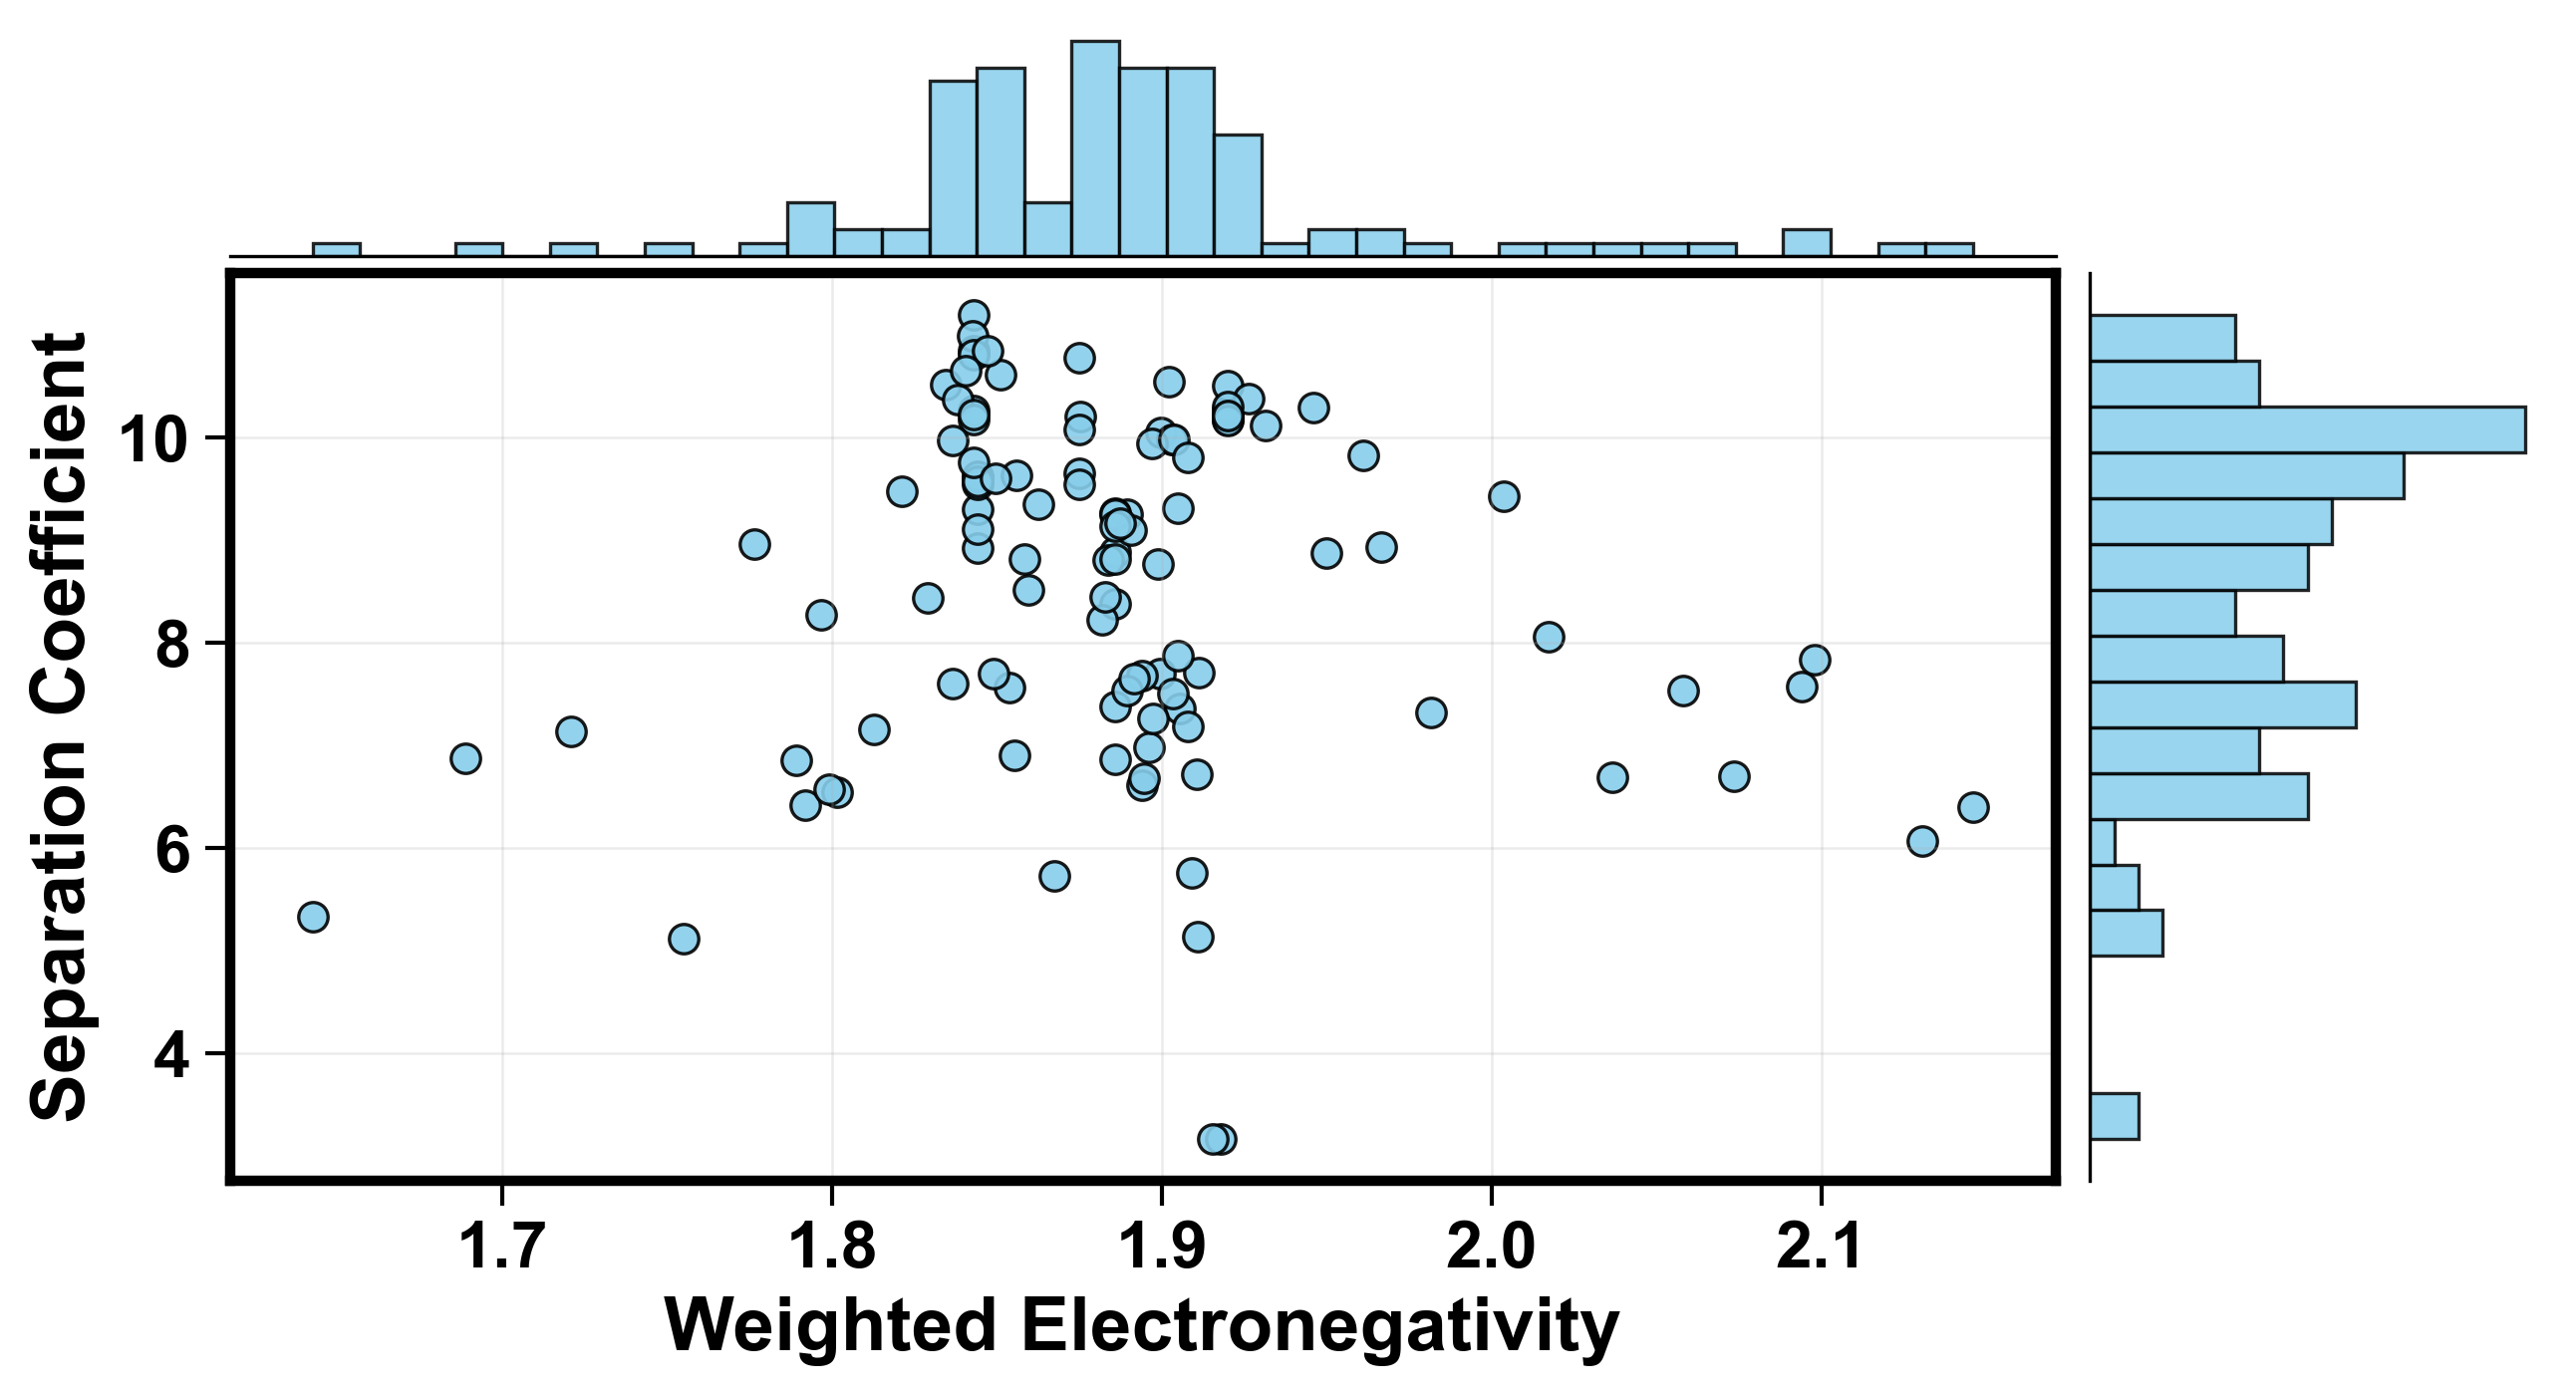

Saved: electronegativity.png


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# =========================
# 假设 plot_df 已经在你前面代码中生成好
# plot_df = df[[...]].dropna()
# =========================

# -------------------------
# 全局字体/线宽风格
# -------------------------
# 全局字体/线宽风格（更小一档）
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16   # 原 18
mpl.rcParams["ytick.labelsize"] = 16  # 原 18
mpl.rcParams["axes.labelsize"]  = 18   # 原 20
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6   # 可选：原 7，稍微小一点更协调
mpl.rcParams["ytick.major.size"]  = 6


# =========================
# 选择 X/Y 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "separation_coefficient"
x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)

# =========================
# 配色与描边（浅红 + 黑边）
# =========================
FILL_COLOR = "skyblue"   # 浅红（你可再调浅：#f9b3b3 / #fbd0d0）
EDGE_COLOR = "black"
SCATTER_ALPHA = 0.90
HIST_ALPHA = 0.85

SCATTER_SIZE = 50
SCATTER_LW = 0.8
BAR_LW = 0.8

# =========================
# 建图：主图 + 边缘直方图
# =========================
fig = plt.figure(figsize=(10, 5), dpi=300)
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.0, 4.0],
    width_ratios=[4.0, 1.0],
    hspace=0.03, wspace=0.03
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图（浅红填充 + 黑圈）
# =========================
ax_scatt.scatter(
    x, y,
    s=SCATTER_SIZE,
    facecolors=FILL_COLOR,
    edgecolors=EDGE_COLOR,
    linewidths=SCATTER_LW,
    alpha=SCATTER_ALPHA
)

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Separation Coefficient")
ax_scatt.grid(True, linewidth=0.6, alpha=0.25)

# =========================
# 上方 X 直方图（浅红 + 黑边）
# =========================
bins_x = 35
counts_x, edges_x = np.histogram(x, bins=bins_x)
centers_x = 0.5 * (edges_x[:-1] + edges_x[1:])
widths_x = np.diff(edges_x)

ax_histx.bar(
    centers_x, counts_x, width=widths_x,
    color=FILL_COLOR, alpha=HIST_ALPHA,
    edgecolor=EDGE_COLOR, linewidth=BAR_LW
)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

# ✅ 上方图：只保留下边线
for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧 Y 直方图（浅红 + 黑边）
# =========================
bins_y = 18
counts_y, edges_y = np.histogram(y, bins=bins_y)
centers_y = 0.5 * (edges_y[:-1] + edges_y[1:])
heights_y = np.diff(edges_y)

ax_histy.barh(
    centers_y, counts_y, height=heights_y,
    color=FILL_COLOR, alpha=HIST_ALPHA,
    edgecolor=EDGE_COLOR, linewidth=BAR_LW
)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

# ✅ 右侧图：只保留左边线
for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 输出
# =========================
out = "electronegativity.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)

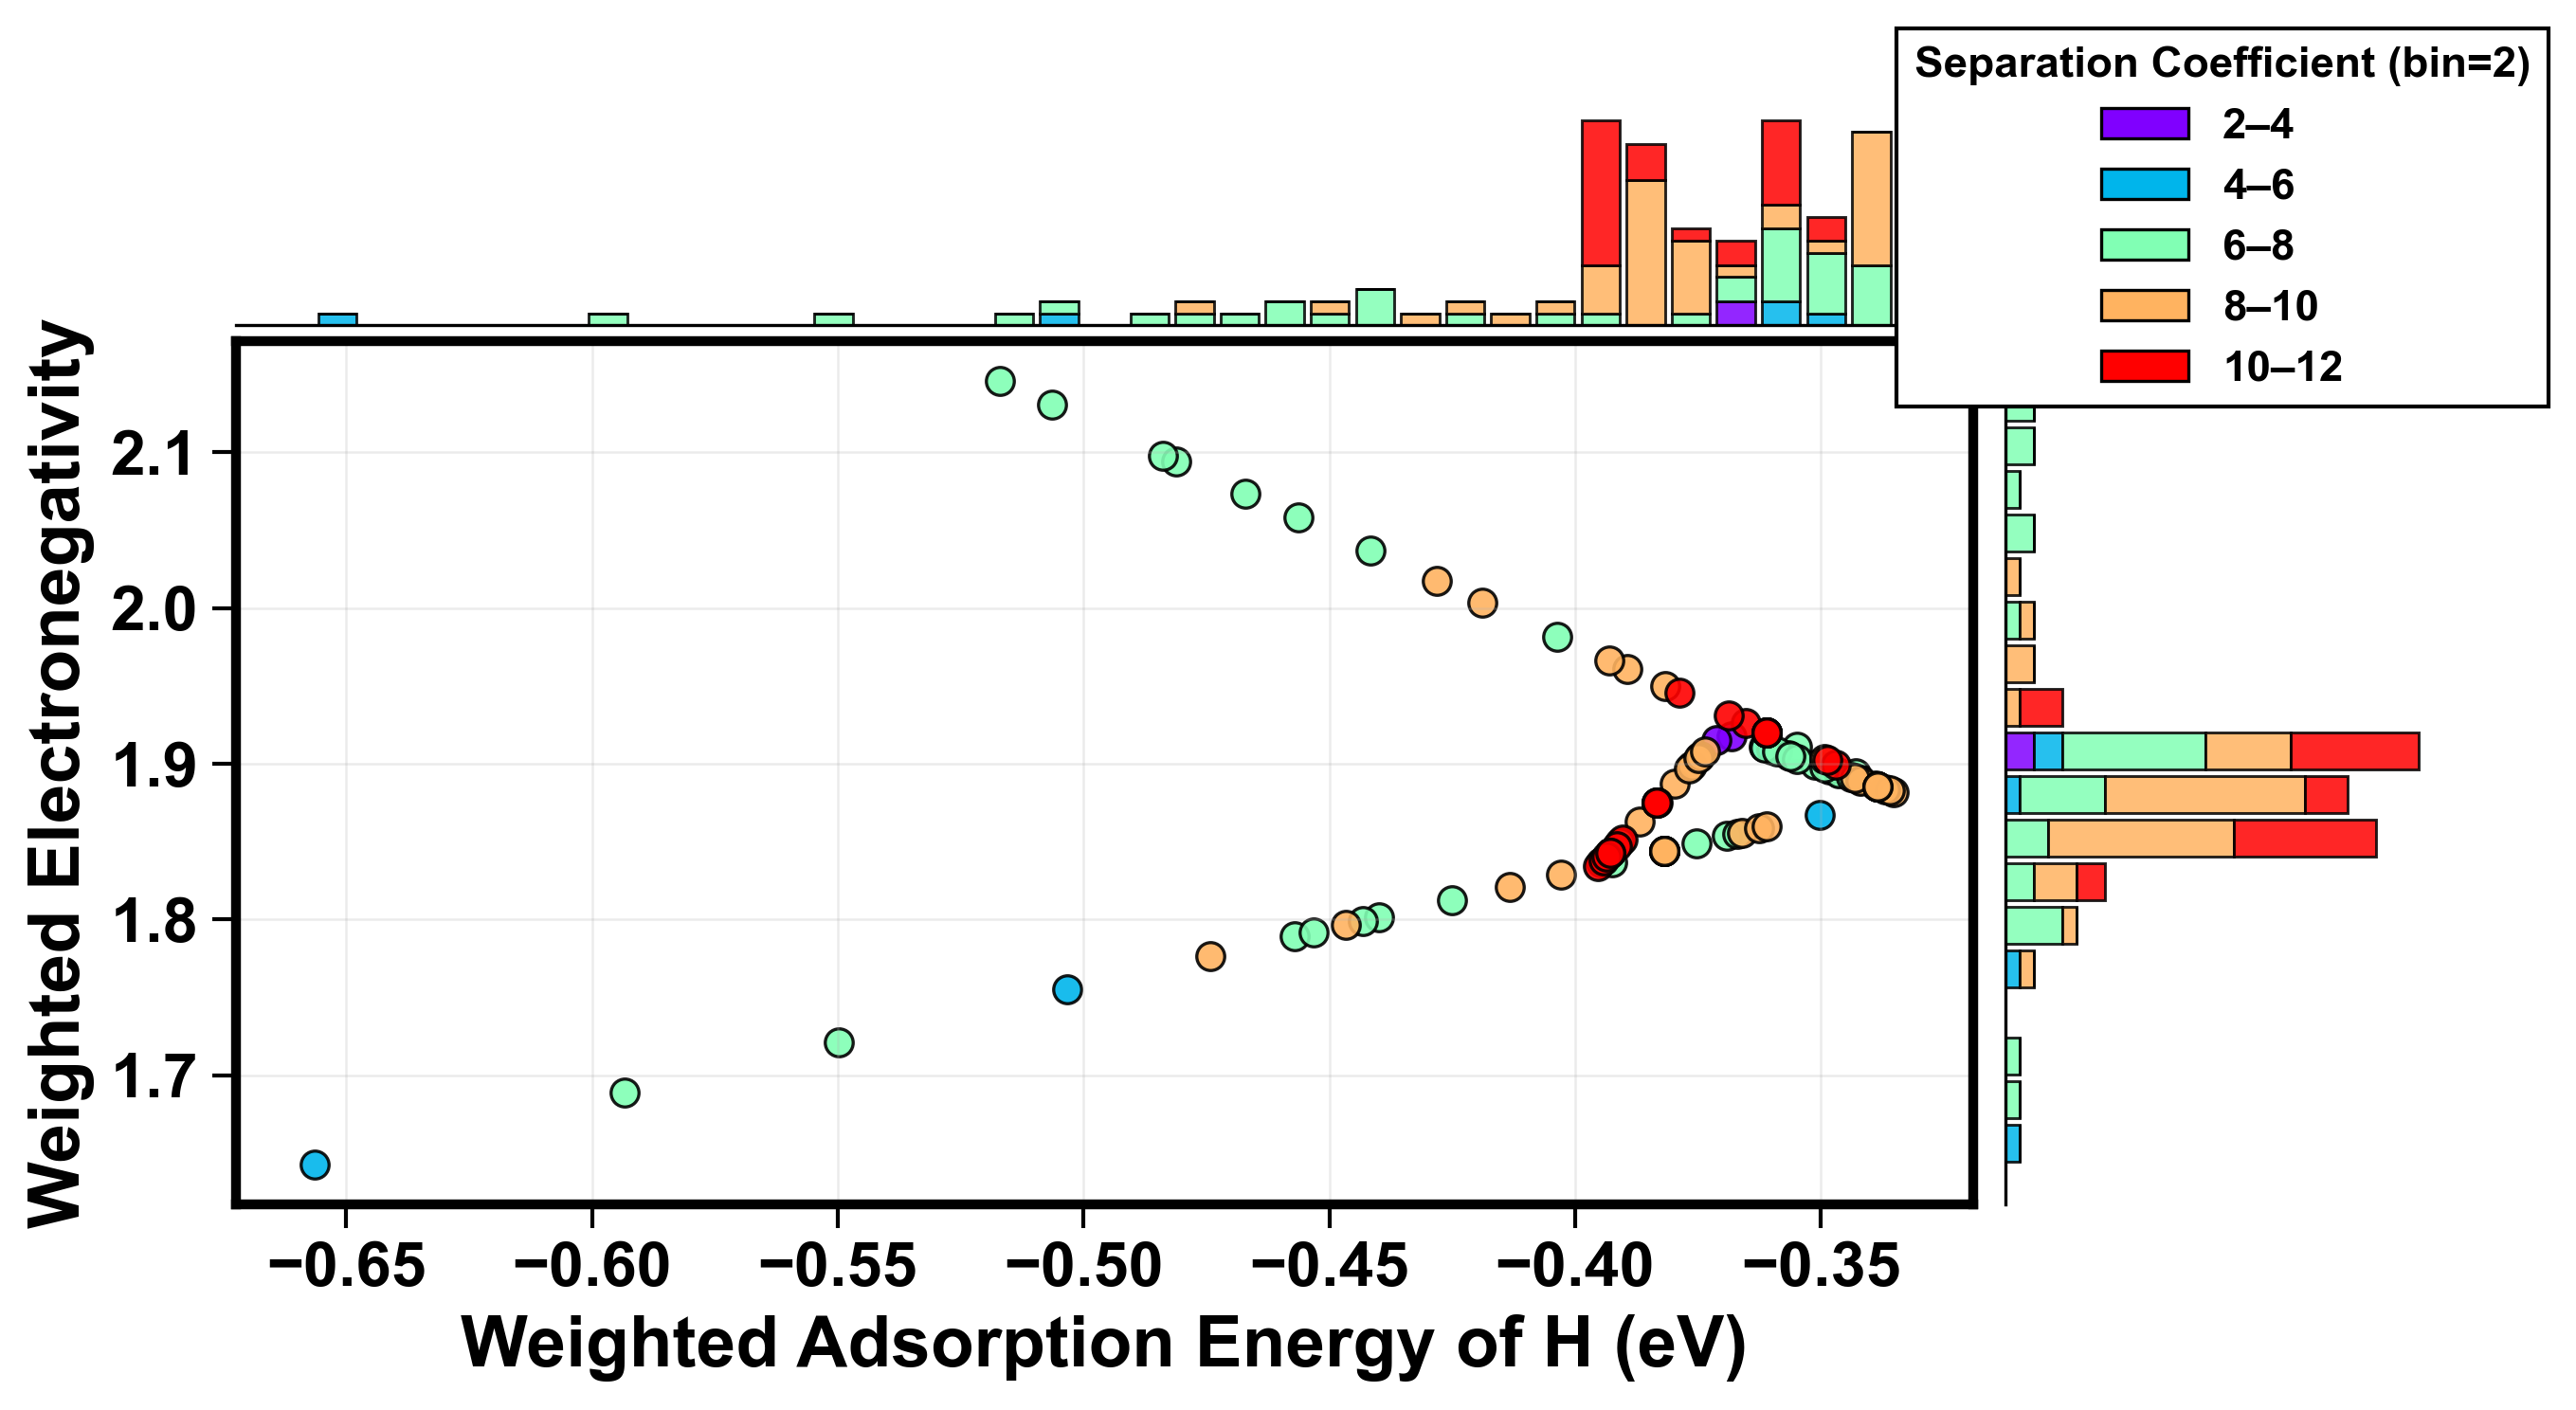

Saved: joint_scatter_xFE_yEN_colorSep_bin2.png


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

# =========================
# 假设 plot_df 已经在你前面代码中生成好
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","separation_coefficient"]].dropna()
# =========================

# -------------------------
# 全局字体/线宽风格（你之前的小一档）
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择列：x / y / color
# =========================
X_COL = "weighted_FE_ads_avg"
Y_COL = "weighted_electronegativity"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# 去掉 NaN（保险）
mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(c)
x, y, c = x[mask], y[mask], c[mask]

# =========================
# separation coefficient：每 2 为一档的离散分箱
# =========================
BIN_W = 2.0  # ✅ 每 2 一个颜色
cmin, cmax = np.nanmin(c), np.nanmax(c)
left  = np.floor(cmin / BIN_W) * BIN_W
right = np.ceil (cmax / BIN_W) * BIN_W

# 保证至少一档
if right <= left:
    right = left + BIN_W

bin_edges = np.arange(left, right + BIN_W, BIN_W)  # [left, left+2, ...]
n_bins = len(bin_edges) - 1

# 每个点属于哪个 bin：0..n_bins-1
bin_idx = np.digitize(c, bin_edges, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)

# =========================
# 颜色：rainbow（离散取色）
# =========================
cmap = plt.cm.rainbow
if n_bins == 1:
    colors = [cmap(0.5)]
else:
    colors = [cmap(i / (n_bins - 1)) for i in range(n_bins)]

# =========================
# 绘图参数
# =========================
SCATTER_SIZE = 50
SCATTER_LW   = 0.8
SCATTER_ALPHA = 0.90

HIST_ALPHA = 0.85
BAR_LW     = 0.7

# 直方图柱宽“占 bin 的比例”统一（让上下/左右柱子视觉一致）
BAR_REL = 0.85

# 直方图 bins（你可以继续微调）
bins_x = 35
bins_y = 18

# =========================
# 建图：主图 + 边缘直方图 + 右上角图例
# =========================
fig = plt.figure(figsize=(10, 5), dpi=300)
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.0, 4.0],
    width_ratios=[4.0, 1.0],
    hspace=0.03, wspace=0.03
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_leg   = fig.add_subplot(gs[0, 1])
ax_leg.axis("off")

# =========================
# 主散点：按 separation bin 分组上色（黑边）
# =========================
for k in range(n_bins):
    m = (bin_idx == k)
    if not np.any(m):
        continue
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=colors[k],
        edgecolors="black",
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA
    )

ax_scatt.set_xlabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.set_ylabel("Weighted Electronegativity")
ax_scatt.grid(True, linewidth=0.6, alpha=0.25)

# =========================
# 上方：x 的堆叠直方图（按 separation bin 堆叠着色）
# =========================
x_groups = [x[bin_idx == k] for k in range(n_bins)]

# 用 hist 直接 stacked=True，之后把每个 patch 的边框加黑
n, bins, patches = ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=colors,
    alpha=HIST_ALPHA,
    edgecolor="black",
    linewidth=BAR_LW
)

# 让柱子不占满 bin：缩放每个 patch 的宽度（BAR_REL）
for p in ax_histx.patches:
    w = p.get_width()
    new_w = w * BAR_REL
    dx = (w - new_w) / 2
    p.set_x(p.get_x() + dx)
    p.set_width(new_w)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

# ✅ 上方图：只保留下边线
for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧：y 的堆叠直方图（水平，按 separation bin 堆叠着色）
# =========================
y_groups = [y[bin_idx == k] for k in range(n_bins)]

n2, bins2, patches2 = ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=colors,
    alpha=HIST_ALPHA,
    edgecolor="black",
    linewidth=BAR_LW
)

# 缩放“height”（对应 barh 的厚度）使之与上方一致（BAR_REL）
for p in ax_histy.patches:
    h = p.get_height()
    new_h = h * BAR_REL
    dy = (h - new_h) / 2
    p.set_y(p.get_y() + dy)
    p.set_height(new_h)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

# ✅ 右侧图：只保留左边线
for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 右上角：separation bins 图例（每 2 一档）
# =========================
legend_handles = []
legend_labels  = []
for k in range(n_bins):
    a, b = bin_edges[k], bin_edges[k + 1]
    legend_handles.append(Patch(facecolor=colors[k], edgecolor="black", linewidth=0.8))
    legend_labels.append(f"{a:.0f}–{b:.0f}")

leg = ax_leg.legend(
    legend_handles, legend_labels,
    title="Separation Coefficient (bin=2)",
    loc="center",
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1.0,
    fontsize=11,
    title_fontsize=11
)

# =========================
# 输出
# =========================
out = "joint_scatter_xFE_yEN_colorSep_bin2.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)


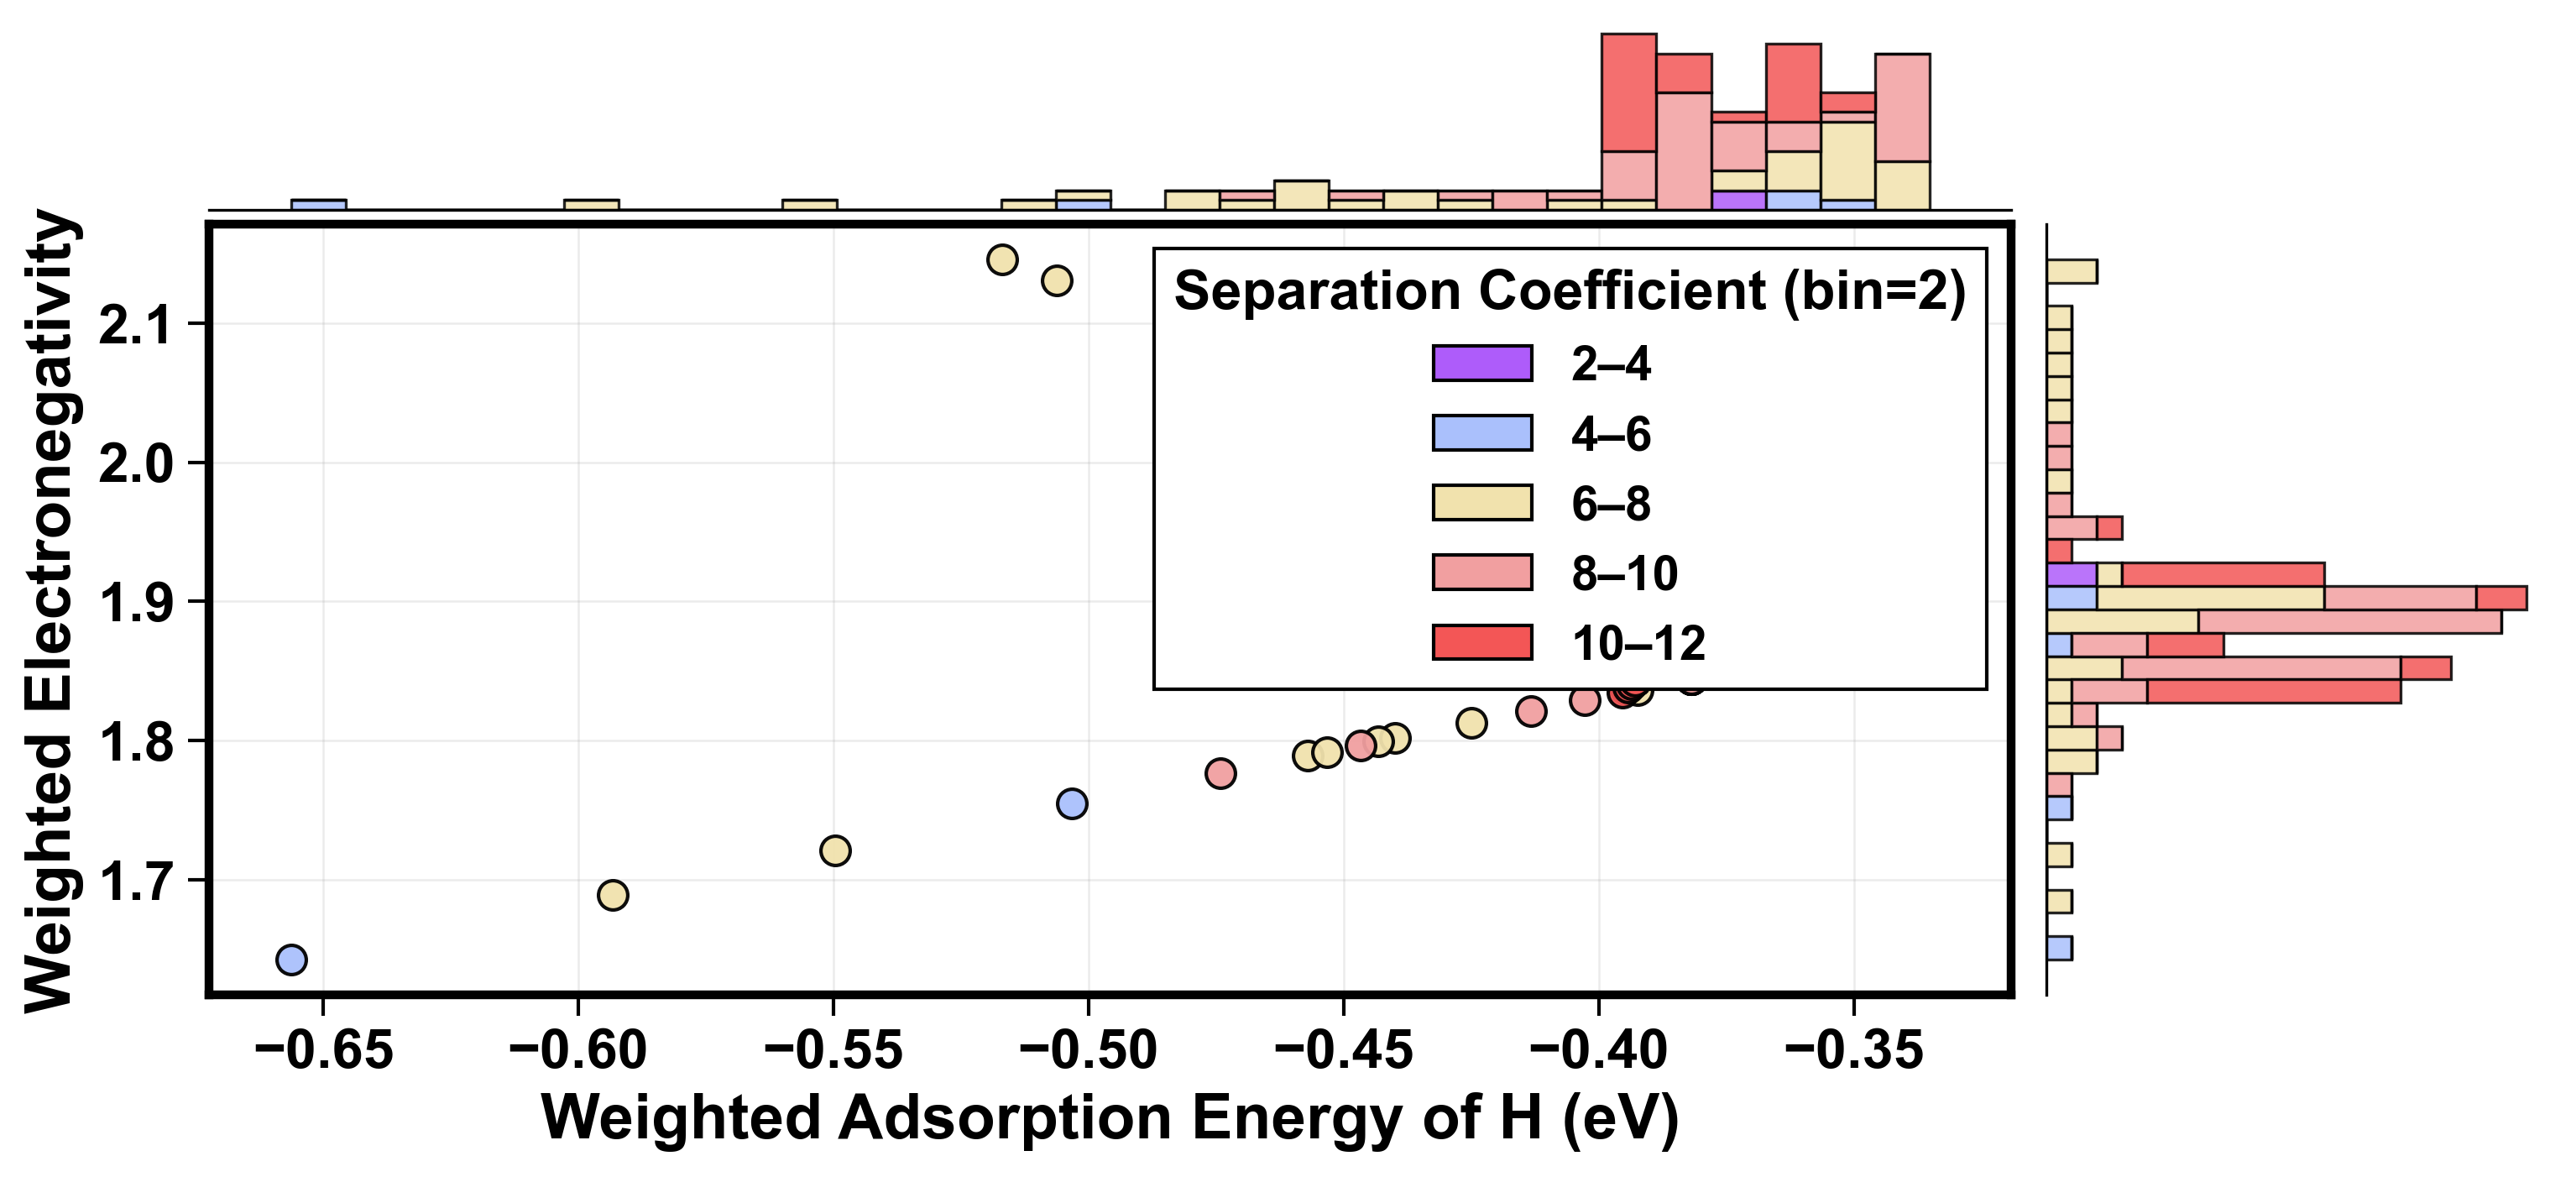

Saved: joint_scatter_xFE_yEN_colorSep_bins2_soft5colors.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

# ============================================================
# 假设 plot_df 已经存在（你前面生成的那个）
# plot_df = df[["weighted_FE_ads_avg","weighted_electronegativity","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格（你之前的小一档）
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_FE_ads_avg"
Y_COL = "weighted_electronegativity"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
cmin = np.nanmin(c)
cmax = np.nanmax(c)

start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)

# 至少保证有一个 bin
if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)  # e.g. 2,4,6,8...
n_bins = len(bins_c) - 1

# 把每个点分到 bin：0..n_bins-1
bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)

bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 配色：红 / 橙 / 黄 / 蓝 / 紫（低饱和）
#   若 n_bins > 5，会在这 5 色之间插值扩展到 n_bins 个
# =========================

RED    = "#F35656"   # soft red
ORANGE = "#F19FA0"   # soft orange
YELLOW = "#F1E2AD"   # soft yellow
BLUE   = "#AAC0FC"   # soft blue
PURPLE = "#AE5CFA"   # soft purple



palette5 = [PURPLE,BLUE,YELLOW, ORANGE,RED]

def _interp_colors(hex1, hex2, n):
    if n <= 1:
        return [mpl.colors.to_hex(hex1)]
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    out = []
    for t in np.linspace(0, 1, n):
        out.append(mpl.colors.to_hex(c1 * (1 - t) + c2 * t))
    return out

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    # 红→橙→黄→蓝→紫 分 4 段插值
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1

    c01 = _interp_colors(RED, ORANGE, seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(ORANGE, YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, BLUE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(BLUE, PURPLE, seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数（黑描边、透明度等）
# =========================
EDGE_COLOR = "black"
SCATTER_SIZE = 70
SCATTER_LW = 1.0
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85
BAR_LW = 0.8

# x/y 直方图 bins 数量：统一（让“柱宽看起来更一致”）
N_HIST_BINS = 30
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS + 1)

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(12, 5), dpi=300)
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, 1.4],
    hspace=0.03, wspace=0.03
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图：按 separation bin 上色（黑圈描边）
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.set_ylabel("Weighted Electronegativity")
ax_scatt.grid(True, linewidth=0.6, alpha=0.25, zorder=0)

# =========================
# 上方直方图：x 的分布，按 separation bin 堆叠着色（黑边）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]
ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA
)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

# 上方图：只保留下边线（托住柱子，避免“空着很丑”）
for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧直方图：y 的分布，按 separation bin 堆叠着色（黑边）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]
ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA
)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

# 右侧图：只保留左边线
for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 图例：Separation Coefficient (bin=2)
# =========================
legend_handles = [
    Patch(facecolor=bin_colors[i], edgecolor="black", label=bin_labels[i])
    for i in range(n_bins)
]
leg = ax_scatt.legend(
    handles=legend_handles,
    title="Separation Coefficient (bin=2)",
    loc="upper right",
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1.0,
    fontsize=14,
    title_fontsize=16
)
leg.get_title().set_fontweight("bold")

# =========================
# 输出
# =========================
out = "joint_scatter_xFE_yEN_colorSep_bins2_soft5colors.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)



In [11]:
# =========================
# 右侧直方图：y 分布，按 separation bin 堆叠着色（黑边）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

# ① 先算“原始堆叠计数”的最大值（不缩放）
raw_stacked = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked += cnt
raw_max = raw_stacked.max() if raw_stacked.size else 1.0

# ② 再画：用 weights 把柱子缩短（只影响柱子，不影响面板宽度）
RIGHT_BAR_SCALE = 0.25   # ✅ 调小=柱子更短（0.15~0.4 都常用）

y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA,
    weights=y_weights
)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

# ③ 关键：把 x 轴范围固定为“原始最大计数”（宽度尺度不随缩放改变）
ax_histy.set_xlim(0, raw_max * 1.05)

# 右侧图：只保留左边线
for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)





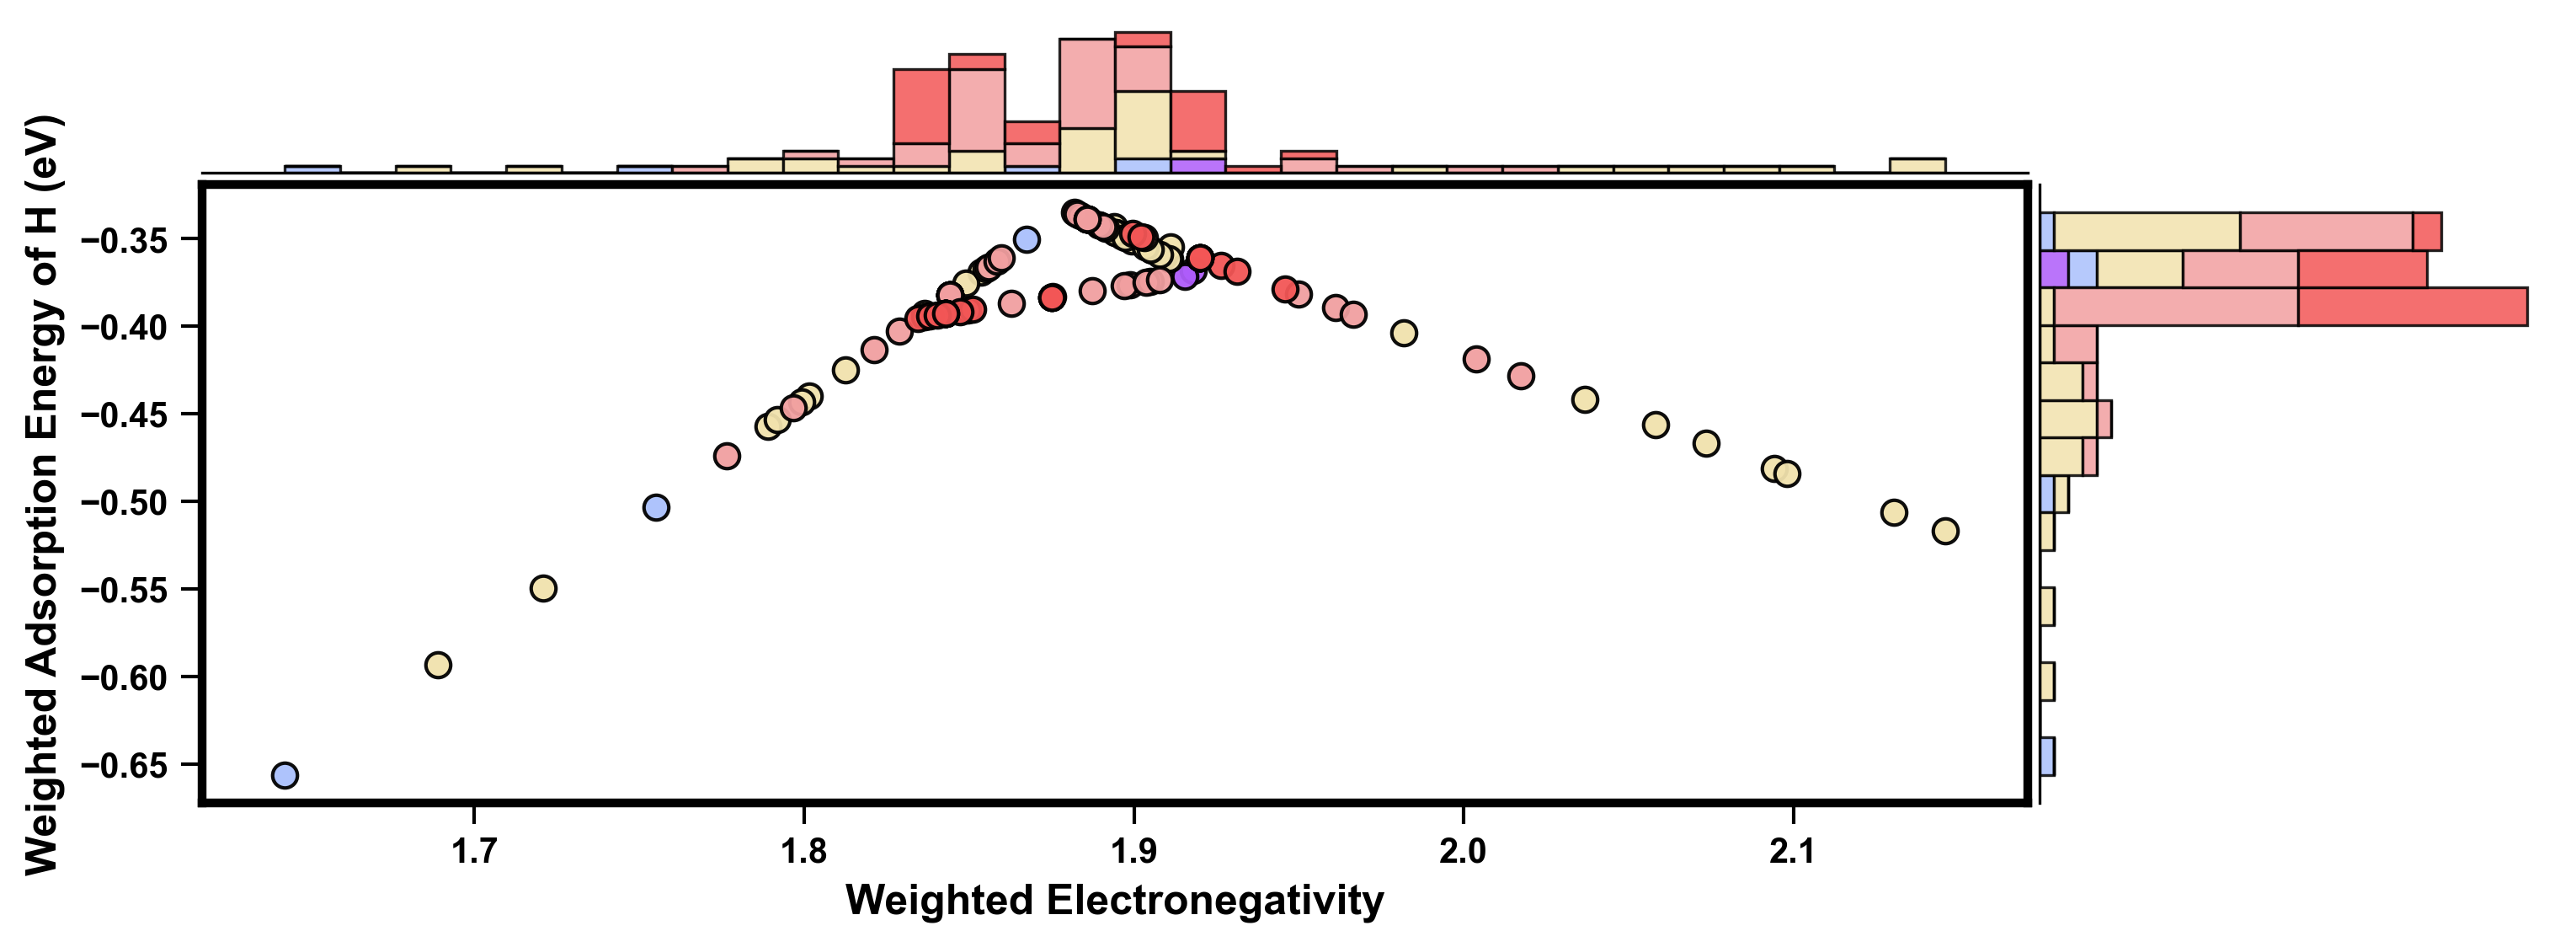

Saved: joint_scatter_no_grid_rightbar_scaled.png


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_FE_ads_avg","weighted_electronegativity","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格（小一档）
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 10
mpl.rcParams["ytick.labelsize"] = 10
mpl.rcParams["axes.labelsize"]  = 12
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_FE_ads_avg"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"

SCATTER_SIZE = 50
SCATTER_LW = 1.0
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85
BAR_LW = 0.8

# 上/右直方图 bins 数量
N_HIST_BINS_X = 30
N_HIST_BINS_Y = 15
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# ✅ 右侧条形“整体拉低”比例（0.4~0.8 之间你自己试，越小越短）
RIGHT_BAR_SCALE = 0.1

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(12, 4), dpi=300)

# ✅ 关键：横向间距按宽高比缩小，保证视觉上更接近“等距”
fig_w, fig_h = fig.get_size_inches()
GAP = 0.03
wspace = GAP * (fig_h / fig_w)   # 12x4 -> 0.03*(4/12)=0.01
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, 1.4],
    hspace=hspace, wspace=wspace
)


ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图：按 separation bin 上色（黑圈描边）
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.grid(False)  # ✅ 去掉网格

# =========================
# 上方直方图：x 分布，按 separation bin 堆叠着色（黑边）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]
ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA
)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧直方图：y 分布，按 separation bin 堆叠着色（黑边）
# ✅ 用 weights 把“横向长度整体缩短”
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]
y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA,
    weights=y_weights
)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 输出
# =========================
out = "joint_scatter_no_grid_rightbar_scaled.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)


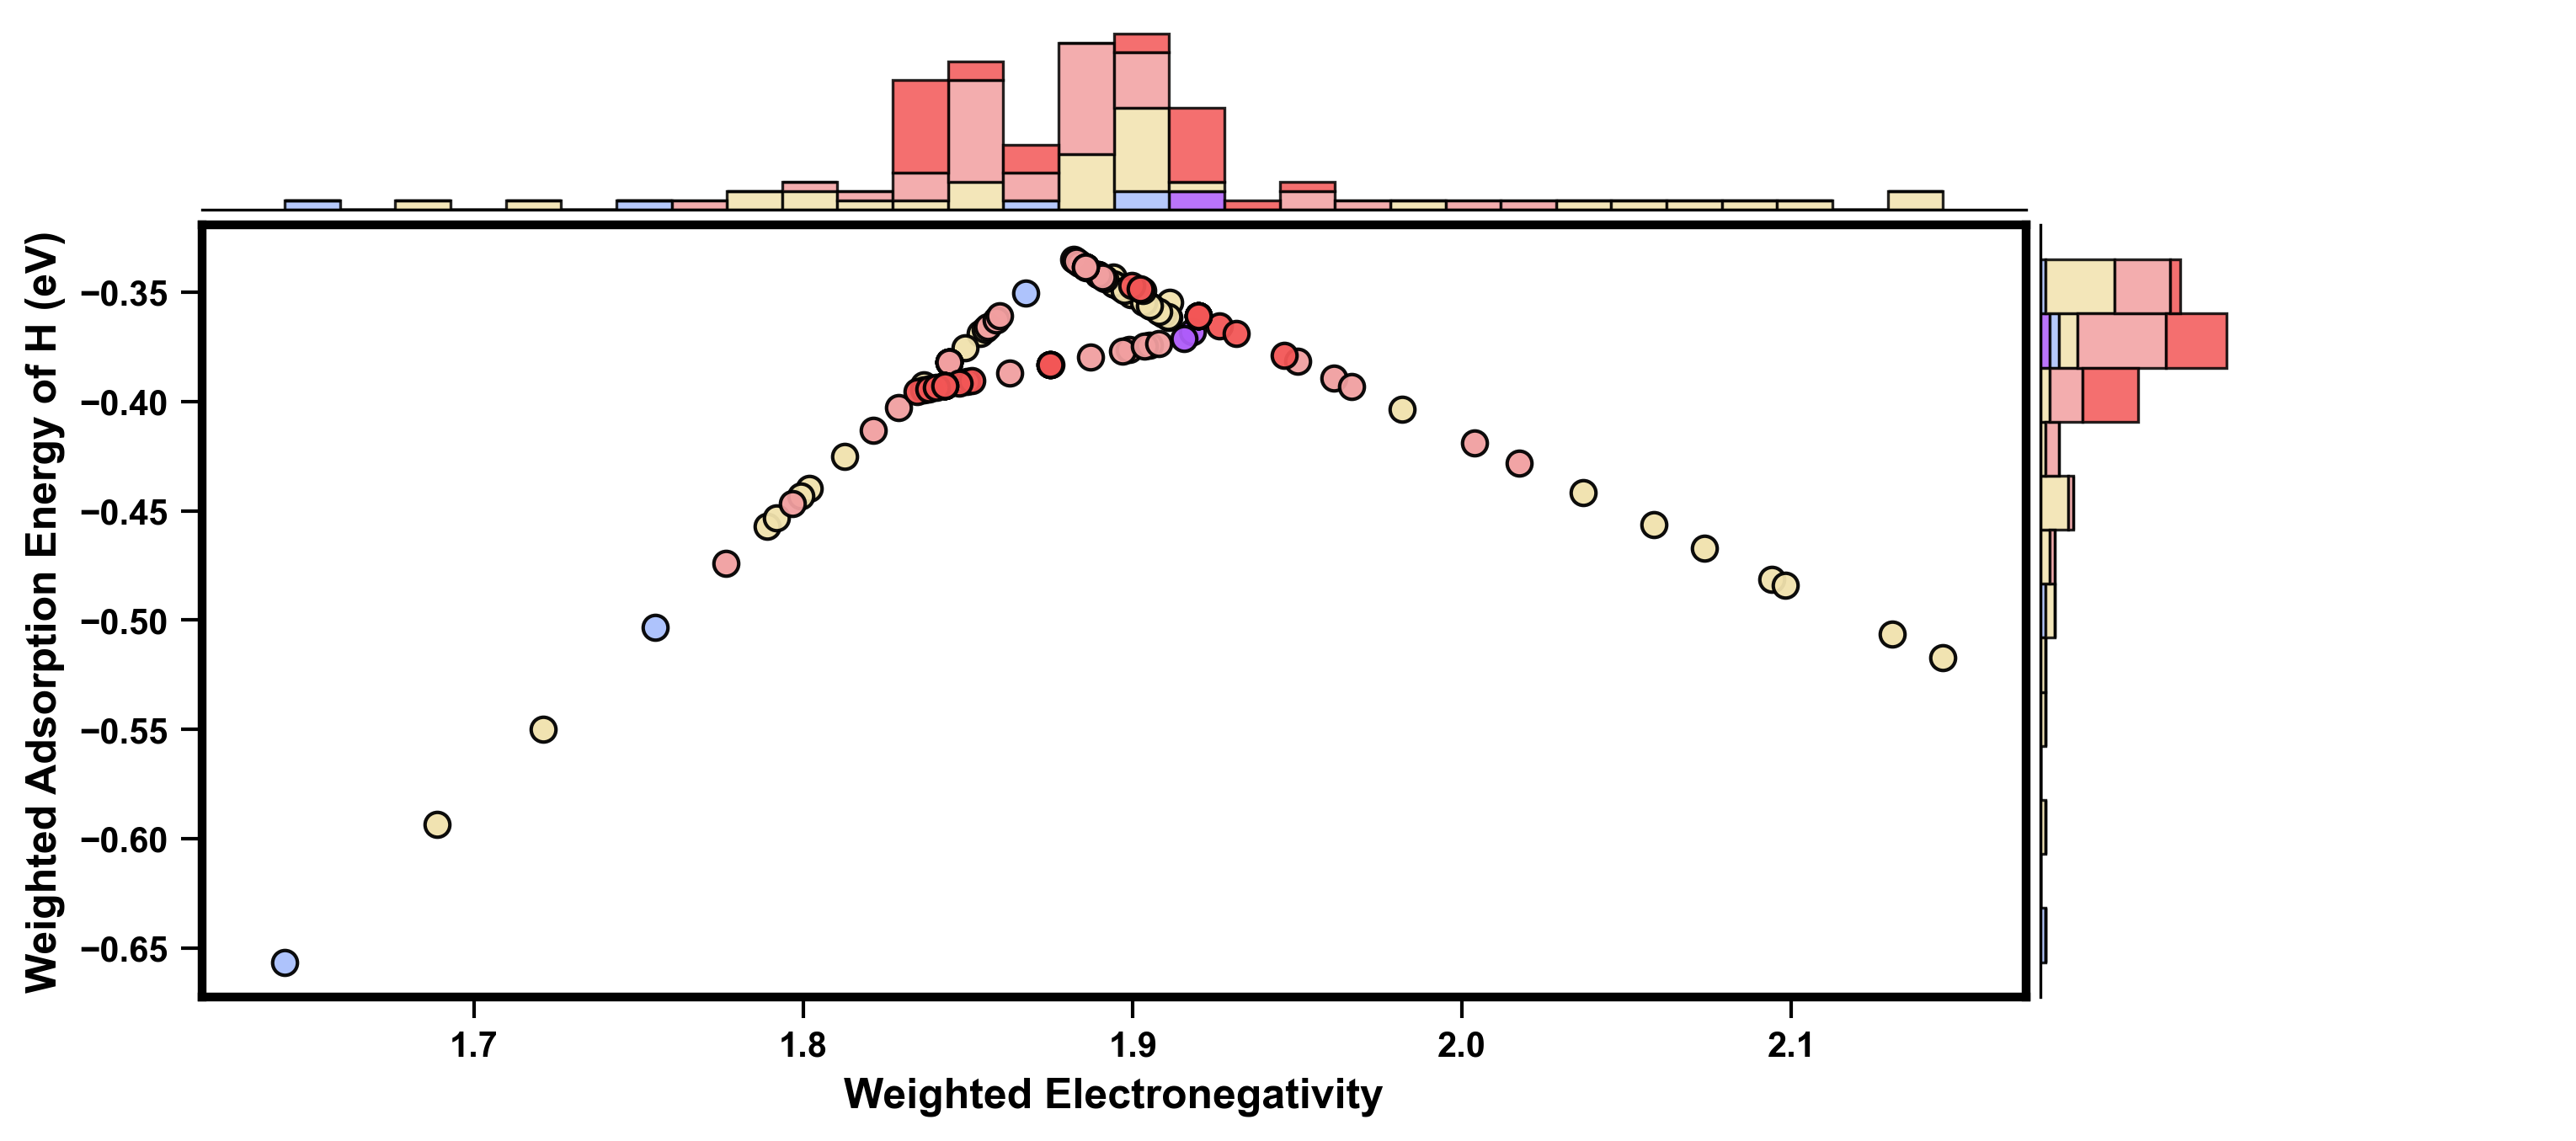

Saved: joint_scatter_no_grid_rightbar_wider_shorter.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_FE_ads_avg","weighted_electronegativity","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 10
mpl.rcParams["ytick.labelsize"] = 10
mpl.rcParams["axes.labelsize"]  = 12
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_FE_ads_avg"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"
SCATTER_SIZE = 50
SCATTER_LW = 1.0
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85
BAR_LW = 0.8

# 上/右直方图 bins 数量
N_HIST_BINS_X = 30
N_HIST_BINS_Y = 13
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# ✅ 右侧柱子“更短”的比例（越小越短）
RIGHT_BAR_SCALE = 0.4

# ✅ 右侧子图面板“更宽”的比例（越大越宽）
RIGHT_PANEL_RATIO = 2.6   # 你现在是 1.4，建议 2.0~2.6 之间试

# ✅ 右侧 x 轴留白（越大柱子看起来越短）
RIGHT_XLIM_PAD = 1.1    # 1.05~1.30 自己试

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(12,5), dpi=300)

# ✅ 关键：横向间距按宽高比缩小，保证视觉上更接近“等距”
fig_w, fig_h = fig.get_size_inches()
GAP = 0.03
wspace = GAP * (fig_h / fig_w)   # 12x4 -> 0.03*(4/12)=0.01
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, 1.4],
    hspace=hspace, wspace=wspace
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.grid(False)

# =========================
# 上方直方图：x 分布（堆叠）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]
ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA
)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(0.8)

# =========================
# 右侧直方图：y 分布（堆叠）
#   关键：weights 缩短 + 固定 xlim（避免自动缩放导致“仍然很长”）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

# ① 算“未缩放”的原始堆叠最大计数，用来固定 x 轴范围
raw_stacked = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked += cnt
raw_max = raw_stacked.max() if raw_stacked.size else 1.0

# ② 用 weights 让柱子整体更短
y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA,
    weights=y_weights
)

# ③ 固定右侧 x 轴范围（柱子就不会再“撑满”）
ax_histy.set_xlim(0, raw_max * RIGHT_XLIM_PAD)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(0.8)

# =========================
# 输出
# =========================
out = "joint_scatter_no_grid_rightbar_wider_shorter.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)


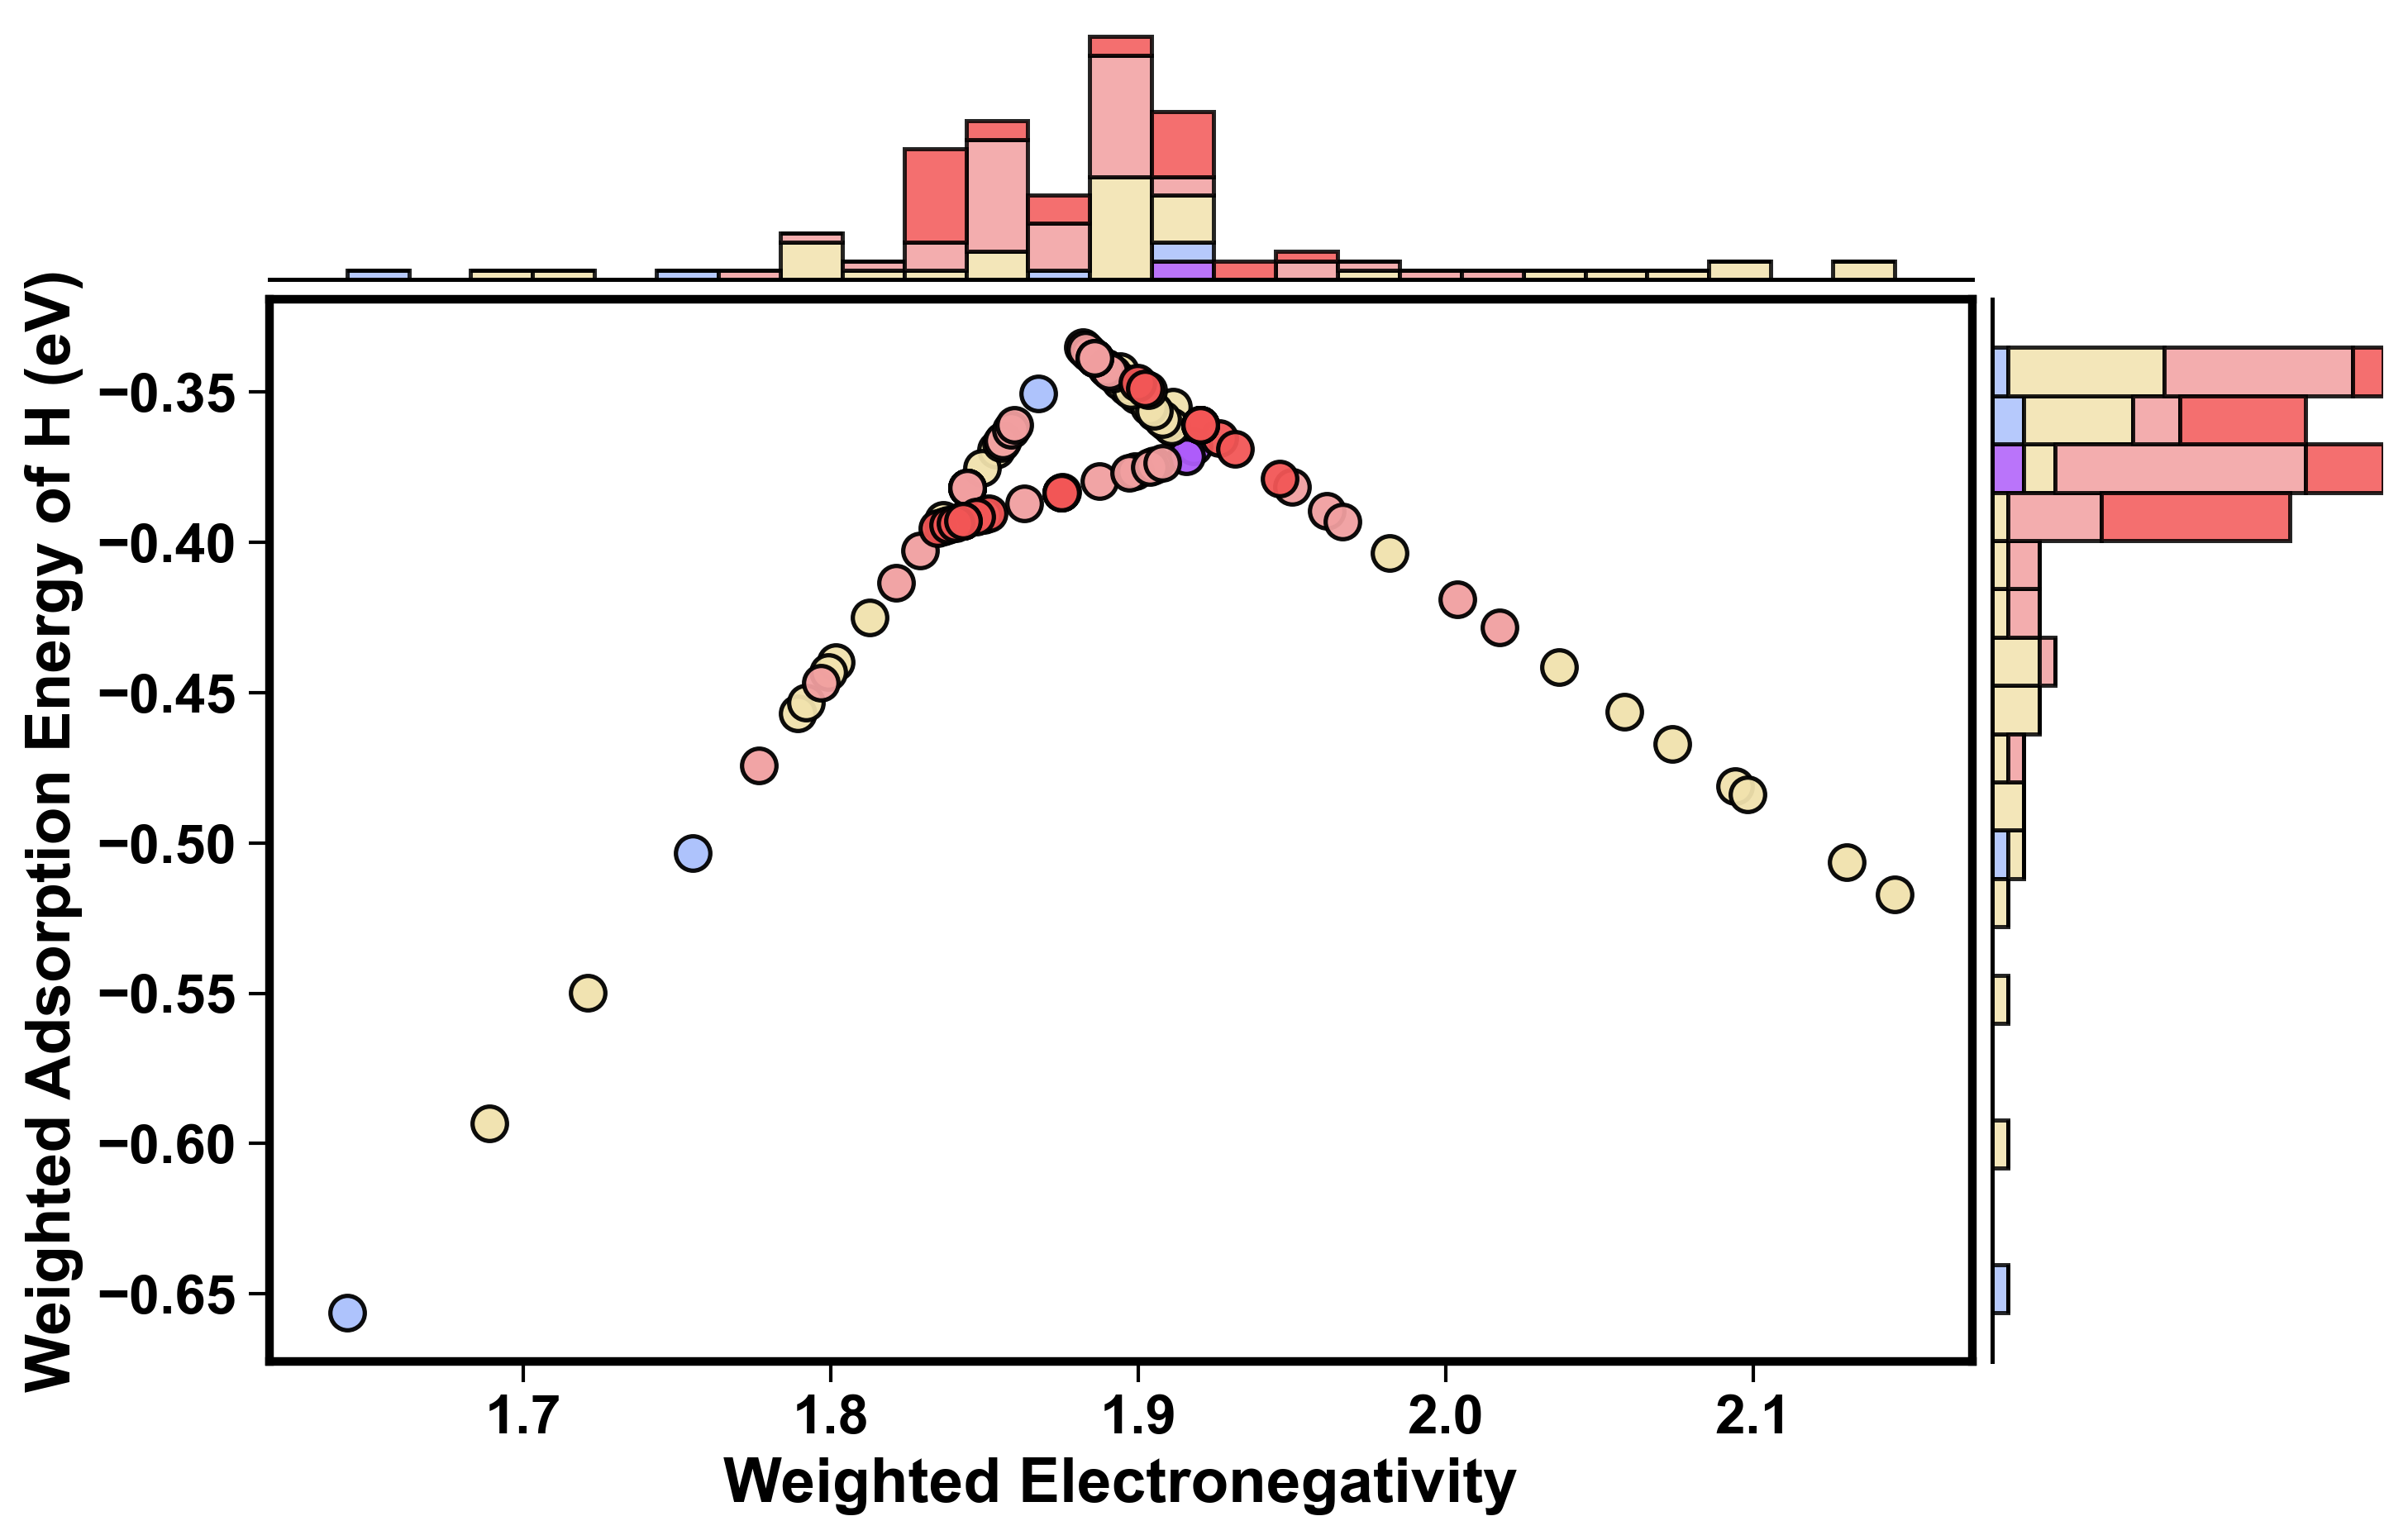

Saved: joint_scatter_compact_10x8.png


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_FE_ads_avg"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"

SCATTER_SIZE  = 100
SCATTER_LW    = 1.25
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85
BAR_LW     = 1.2
HIST_SPINE_LW = 1.2

# 直方图 bins 数量（上/右可不同）
N_HIST_BINS_X = 25
N_HIST_BINS_Y = 20
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# ✅ 右侧柱子整体缩短（weights），越小越短
RIGHT_BAR_SCALE = 0.35
# ✅ 用“缩放后的最大值”去设 xlim 的留白（越大越空）
RIGHT_XLIM_PAD  = 1
# ✅ 右侧面板宽度（调小可去掉右边空白）
RIGHT_PANEL_RATIO = 1.15   # 关键：原来 2.2 会很空，建议 1.0~1.3

# ✅ 上方柱子缩短（weights）
TOP_BAR_SCALE = 0.75
TOP_YLIM_PAD  = 1.05

# ✅ 控制散点-边缘直方图间距
GAP = 0.03

# =========================
# 建图：比例 10:8
# =========================
fig = plt.figure(figsize=(11, 7), dpi=300)  # ✅ 10:8

fig_w, fig_h = fig.get_size_inches()
wspace = GAP * (fig_h / fig_w)
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, RIGHT_PANEL_RATIO],  # ✅ 右侧更窄
    hspace=hspace, wspace=wspace
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.grid(False)

# =========================
# 上方直方图（缩短 + 用缩短后的 max 来定 ylim）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]

raw_stacked_x = np.zeros(len(bins_x) - 1, dtype=float)
for arr in x_groups:
    cnt, _ = np.histogram(arr, bins=bins_x)
    raw_stacked_x += cnt
raw_max_x = raw_stacked_x.max() if raw_stacked_x.size else 1.0

x_weights = [np.ones_like(arr, dtype=float) * TOP_BAR_SCALE for arr in x_groups]

ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA,
    weights=x_weights
)

# ✅ 用缩放后的最大值定 ylim，避免上方空太多
scaled_max_x = raw_max_x * TOP_BAR_SCALE
ax_histx.set_ylim(0, scaled_max_x * TOP_YLIM_PAD)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(HIST_SPINE_LW)

# =========================
# 右侧直方图（缩短 + 用缩短后的 max 来定 xlim）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

raw_stacked_y = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked_y += cnt
raw_max_y = raw_stacked_y.max() if raw_stacked_y.size else 1.0

y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,
    alpha=HIST_ALPHA,
    weights=y_weights
)

# ✅ 用缩放后的最大值定 xlim，右侧轴内空白会明显减少
scaled_max_y = raw_max_y * RIGHT_BAR_SCALE
ax_histy.set_xlim(0, scaled_max_y * RIGHT_XLIM_PAD)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(HIST_SPINE_LW)

# =========================
# 输出（tight + 更小 pad，进一步吃掉外边距）
# =========================
out = "joint_scatter_compact_10x8.png"
plt.savefig(out, dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()
print("Saved:", out)






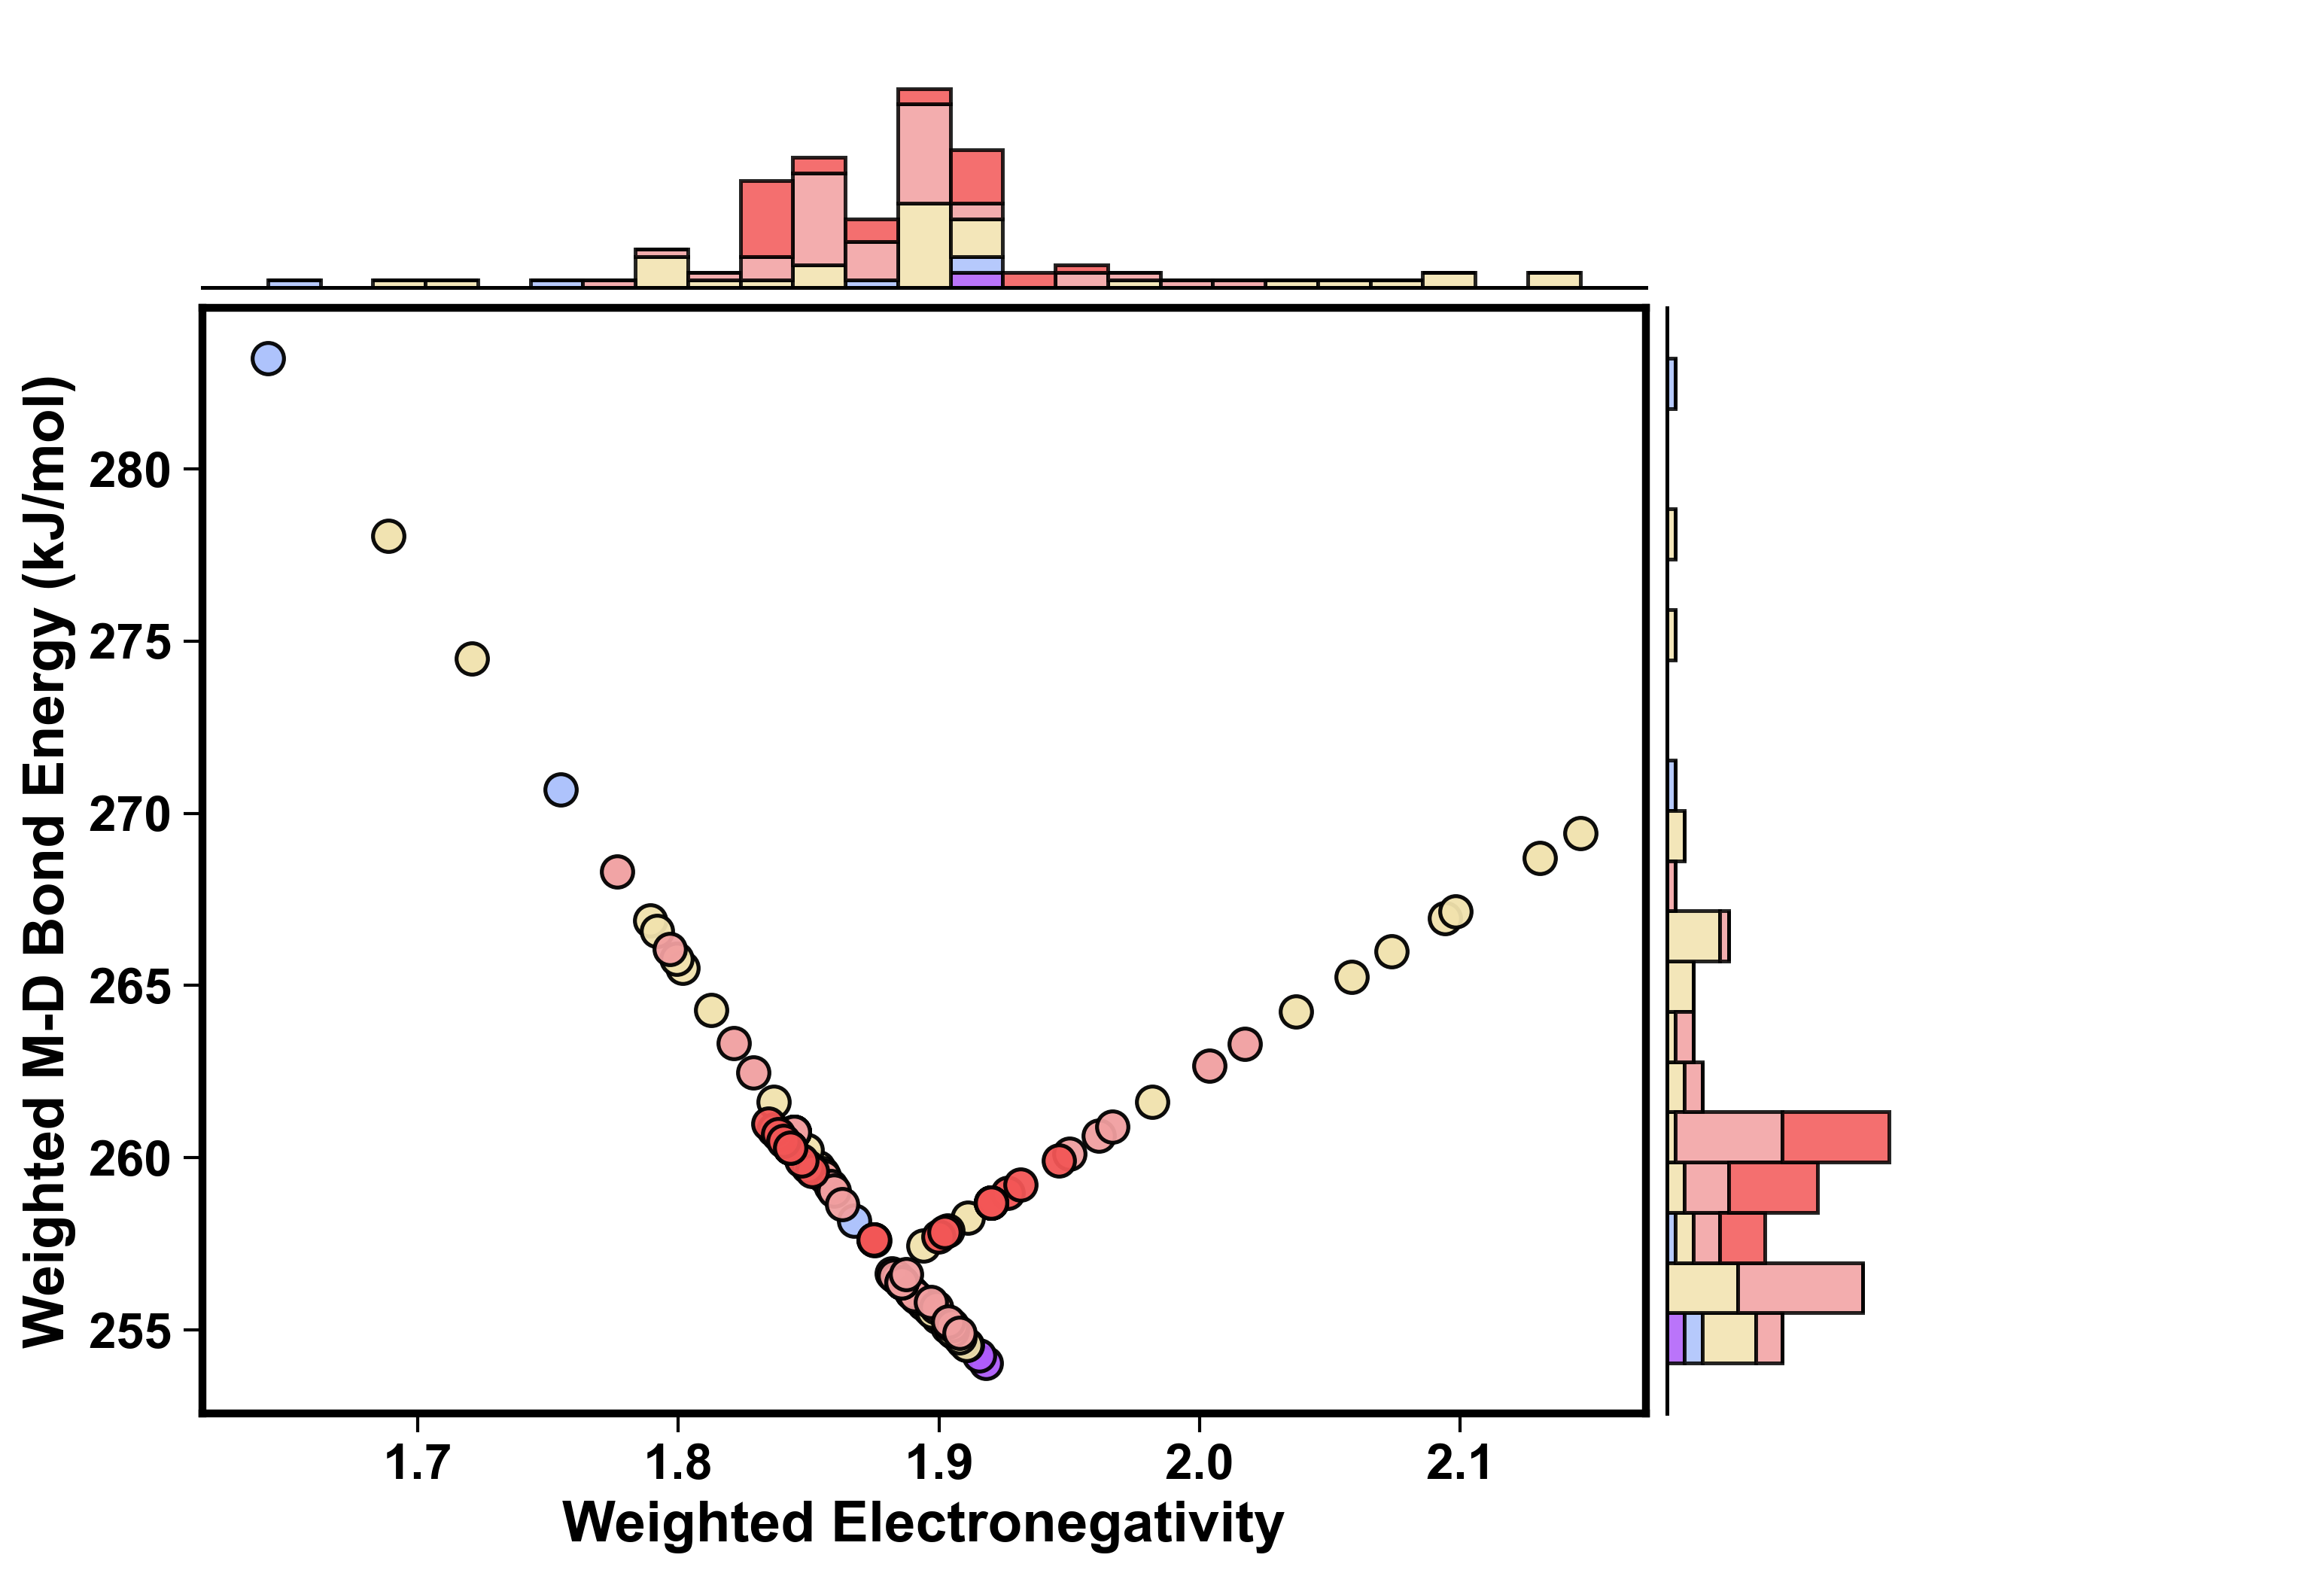

Saved: joint_scatter_no_grid_top_right_shorter_thick_hist_edges_MD.png


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_M-D_bond_energy"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"

SCATTER_SIZE  = 100
SCATTER_LW    = 1.25
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85

# ✅ 直方图柱子描边加粗（原来 0.8）
BAR_LW     = 1.2

# ✅ 直方图面板保留的那条轴线加粗（原来 0.8）
HIST_SPINE_LW = 1.2

# 直方图 bins 数量（上/右可不同）
N_HIST_BINS_X = 25
N_HIST_BINS_Y = 20
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# 右侧柱子整体缩短（越小越短）
RIGHT_BAR_SCALE = 0.35
RIGHT_XLIM_PAD  = 1
RIGHT_PANEL_RATIO = 2.2

# 上方柱子整体缩短
TOP_BAR_SCALE = 0.75
TOP_YLIM_PAD  = 1

# 控制“视觉等距”的 gap
GAP = 0.03

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(12, 8), dpi=300)

fig_w, fig_h = fig.get_size_inches()
wspace = GAP * (fig_h / fig_w)
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, RIGHT_PANEL_RATIO],
    hspace=hspace, wspace=wspace
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Weighted M-D Bond Energy (kJ/mol)")
ax_scatt.grid(False)

# =========================
# 上方直方图：x 分布（堆叠）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]

raw_stacked_x = np.zeros(len(bins_x) - 1, dtype=float)
for arr in x_groups:
    cnt, _ = np.histogram(arr, bins=bins_x)
    raw_stacked_x += cnt
raw_max_x = raw_stacked_x.max() if raw_stacked_x.size else 1.0

x_weights = [np.ones_like(arr, dtype=float) * TOP_BAR_SCALE for arr in x_groups]

ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=x_weights
)

ax_histx.set_ylim(0, raw_max_x * TOP_YLIM_PAD)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 右侧直方图：y 分布（堆叠）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

raw_stacked_y = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked_y += cnt
raw_max_y = raw_stacked_y.max() if raw_stacked_y.size else 1.0

y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=y_weights
)

ax_histy.set_xlim(0, raw_max_y * RIGHT_XLIM_PAD)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 输出
# =========================
out = "joint_scatter_no_grid_top_right_shorter_thick_hist_edges_MD.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)

c:\Users\Admin\anaconda3\Lib\site-packages\matplotlib\tri\_tritools.py:105: RuntimeWarning: invalid value encountered in sqrt
  4.0*np.sqrt(prod[~bool_flat]))


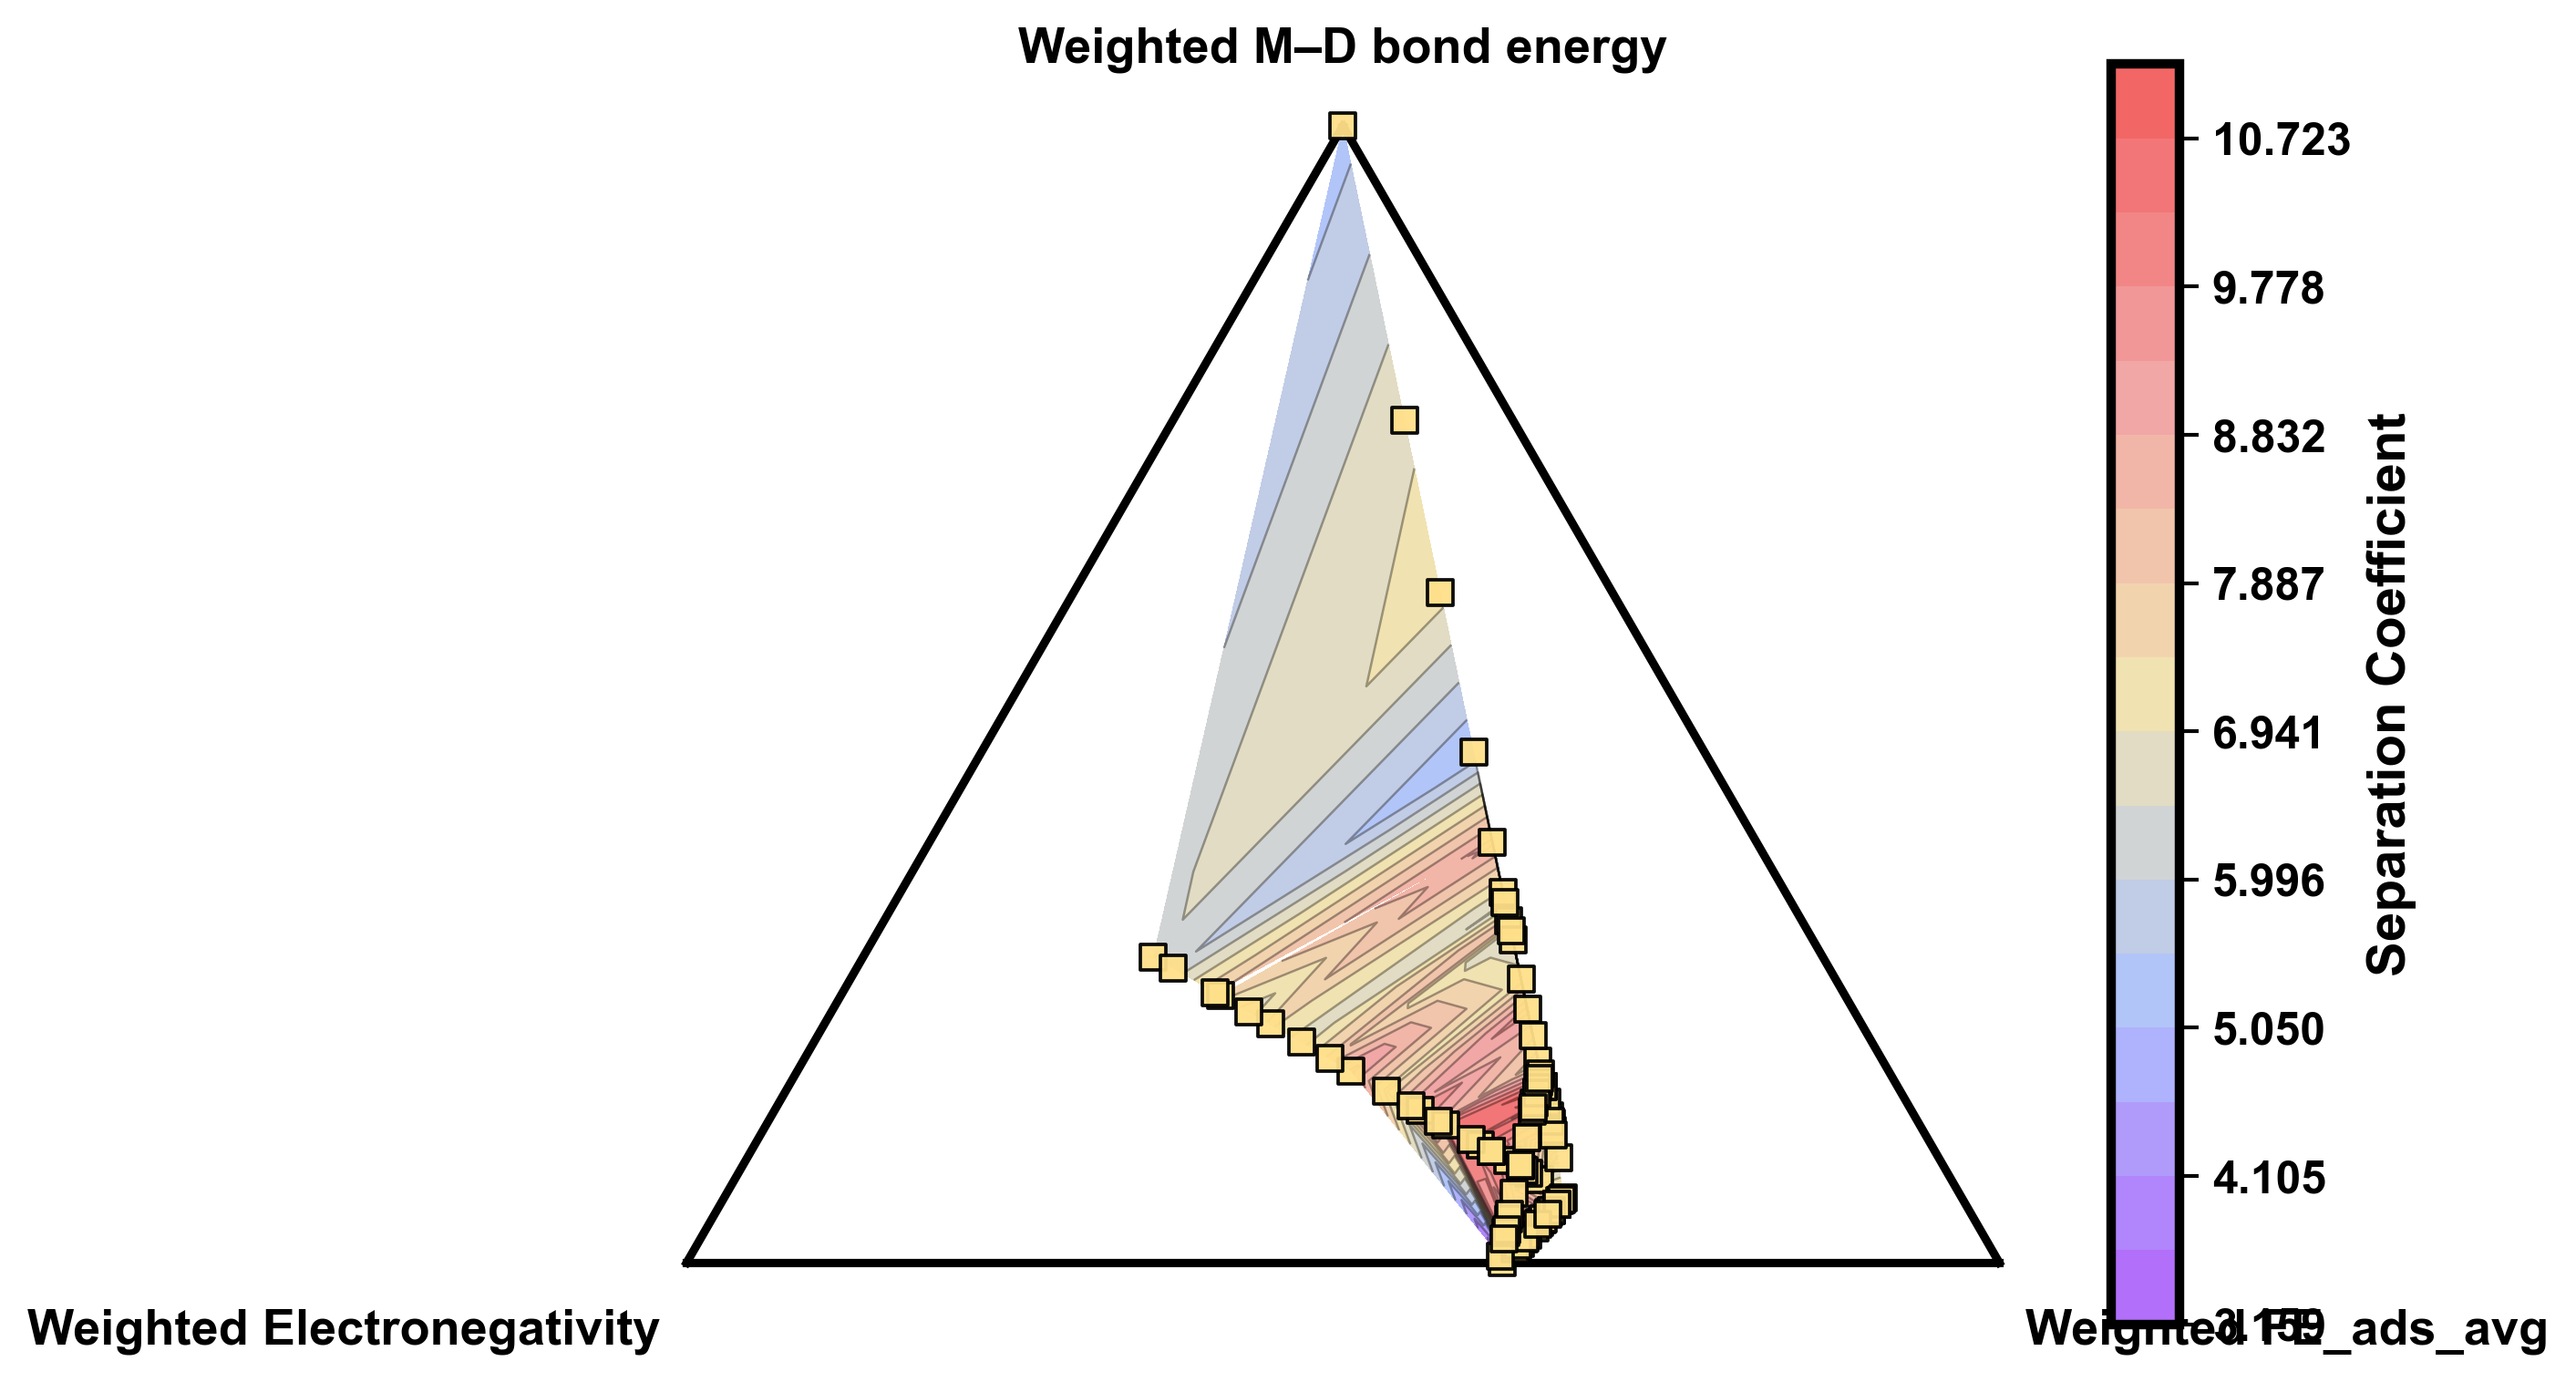

Saved: ternary_contour_sepcoef.png


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.tri as mtri
from matplotlib.colors import LinearSegmentedColormap

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[[
#   "weighted_electronegativity",
#   "weighted_FE_ads_avg",
#   "weighted_MD_bond_energy",
#   "separation_coefficient"
# ]].dropna()
# ============================================================

# -------------------------
# 全局风格（按你之前的画风）
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5
mpl.rcParams["xtick.labelsize"] = 14
mpl.rcParams["ytick.labelsize"] = 14
mpl.rcParams["axes.labelsize"]  = 16
mpl.rcParams["axes.labelweight"] = "bold"

# =========================
# 列名（按你的实际列名改这里）
# =========================
COL_A = "weighted_electronegativity"
COL_B = "weighted_FE_ads_avg"
COL_C = "weighted_M-D_bond_energy"      # ←如果你列名不同，改这行
COL_Z = "separation_coefficient"

dfp = plot_df[[COL_A, COL_B, COL_C, COL_Z]].dropna()

A = dfp[COL_A].to_numpy(float)
B = dfp[COL_B].to_numpy(float)
C = dfp[COL_C].to_numpy(float)
Z = dfp[COL_Z].to_numpy(float)

# =========================
# 1) 把三个指标变成“非负权重”，并行归一化到 a+b+c=1
#    默认：min-max 到 [0,1]，再归一化
# =========================
def minmax01(v):
    vmin, vmax = np.nanmin(v), np.nanmax(v)
    if np.isclose(vmax, vmin):
        return np.zeros_like(v)
    out = (v - vmin) / (vmax - vmin)
    return np.clip(out, 0.0, 1.0)

a0 = minmax01(A)
b0 = minmax01(B)
c0 = minmax01(C)

eps = 1e-12
s = a0 + b0 + c0 + eps
a = a0 / s
b = b0 / s
c = c0 / s   # 现在 a+b+c=1

# =========================
# 2) 重心坐标 -> 等边三角形二维坐标
#    设三角形顶点：
#    A(左下)=(0,0), B(右下)=(1,0), C(顶点)=(0.5, sqrt(3)/2)
# =========================
h = np.sqrt(3) / 2.0
x = b * 1.0 + c * 0.5
y = c * h

# =========================
# 3) 三角剖分 + 等高线
# =========================
tri = mtri.Triangulation(x, y)

# 可选：mask 掉过“瘦”的三角形，避免边缘怪条纹（建议开着）
try:
    mask = mtri.TriAnalyzer(tri).get_flat_tri_mask(min_circle_ratio=0.01)
    tri.set_mask(mask)
except Exception:
    pass

# 你这套低饱和配色（紫->蓝->黄->橙->红），做连续 colormap
PURPLE = "#AE5CFA"
BLUE   = "#AAC0FC"
YELLOW = "#F1E2AD"
ORANGE = "#F19FA0"
RED    = "#F35656"
cmap = LinearSegmentedColormap.from_list("soft5", [PURPLE, BLUE, YELLOW, ORANGE, RED], N=256)

# levels：越多越“平滑”（像你给的三元等高线图）
n_levels = 18
levels = np.linspace(np.nanmin(Z), np.nanmax(Z), n_levels)

fig = plt.figure(figsize=(7.2, 6.4), dpi=300)
ax = fig.add_axes([0.08, 0.08, 0.72, 0.84])  # 给右侧 colorbar 留空间

cf = ax.tricontourf(tri, Z, levels=levels, cmap=cmap, alpha=0.95)
# 等高线黑边（可选：想更干净就注释掉）
ax.tricontour(tri, Z, levels=levels, colors="black", linewidths=0.6, alpha=0.35)

# =========================
# 4) 叠加数据点（像示例那样用方块）
# =========================
ax.scatter(
    x, y,
    s=42,
    marker="s",
    facecolors="#FFE08A",   # 柔和黄色
    edgecolors="black",
    linewidths=0.9,
    alpha=0.95,
    zorder=5
)

# =========================
# 5) 画三角形边框 + 美化
# =========================
# 三角形三点
V_A = np.array([0.0, 0.0])
V_B = np.array([1.0, 0.0])
V_C = np.array([0.5, h])

# 边框
ax.plot([V_A[0], V_B[0]], [V_A[1], V_B[1]], color="black", lw=2.2)
ax.plot([V_B[0], V_C[0]], [V_B[1], V_C[1]], color="black", lw=2.2)
ax.plot([V_C[0], V_A[0]], [V_C[1], V_A[1]], color="black", lw=2.2)

ax.set_aspect("equal", adjustable="box")
pad = 0.04
ax.set_xlim(-pad, 1 + pad)
ax.set_ylim(-pad, h + pad)
ax.axis("off")

# 顶点标签（你想怎么摆就改这里）
ax.text(V_A[0]-0.02, V_A[1]-0.035, "Weighted Electronegativity", ha="right", va="top", fontsize=13, fontweight="bold")
ax.text(V_B[0]+0.02, V_B[1]-0.035, "Weighted FE_ads_avg",       ha="left",  va="top", fontsize=13, fontweight="bold")
ax.text(V_C[0],      V_C[1]+0.04,  "Weighted M–D bond energy",   ha="center",va="bottom", fontsize=13, fontweight="bold")

# =========================
# 6) 色条
# =========================
cax = fig.add_axes([0.83, 0.14, 0.035, 0.72])
cb = fig.colorbar(cf, cax=cax)
cb.set_label("Separation Coefficient", fontsize=14, fontweight="bold")
cb.ax.tick_params(labelsize=12, width=1.0, length=5)

out = "ternary_contour_sepcoef.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_FE_ads_avg"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"

SCATTER_SIZE  = 100
SCATTER_LW    = 1.25
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85

# ✅ 直方图柱子描边加粗（原来 0.8）
BAR_LW     = 1.2

# ✅ 直方图面板保留的那条轴线加粗（原来 0.8）
HIST_SPINE_LW = 1.2

# 直方图 bins 数量（上/右可不同）
N_HIST_BINS_X = 25
N_HIST_BINS_Y = 20
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# 右侧柱子整体缩短（越小越短）
RIGHT_BAR_SCALE = 0.25
RIGHT_XLIM_PAD  = 1
RIGHT_PANEL_RATIO = 2.2

# 上方柱子整体缩短
TOP_BAR_SCALE = 0.55
TOP_YLIM_PAD  = 1

# 控制“视觉等距”的 gap
GAP = 0.03

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(8, 6), dpi=300)

fig_w, fig_h = fig.get_size_inches()
wspace = GAP * (fig_h / fig_w)
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, RIGHT_PANEL_RATIO],
    hspace=hspace, wspace=wspace
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.grid(False)

# =========================
# 上方直方图：x 分布（堆叠）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]

raw_stacked_x = np.zeros(len(bins_x) - 1, dtype=float)
for arr in x_groups:
    cnt, _ = np.histogram(arr, bins=bins_x)
    raw_stacked_x += cnt
raw_max_x = raw_stacked_x.max() if raw_stacked_x.size else 1.0

x_weights = [np.ones_like(arr, dtype=float) * TOP_BAR_SCALE for arr in x_groups]

ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=x_weights
)

ax_histx.set_ylim(0, raw_max_x * TOP_YLIM_PAD)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 右侧直方图：y 分布（堆叠）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

raw_stacked_y = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked_y += cnt
raw_max_y = raw_stacked_y.max() if raw_stacked_y.size else 1.0

y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=y_weights
)

ax_histy.set_xlim(0, raw_max_y * RIGHT_XLIM_PAD)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 输出
# =========================
out = "outputs/joint_scatter_no_grid_top_right_shorter_thick_hist_edges.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_M-D_bond_energy"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"

SCATTER_SIZE  = 100
SCATTER_LW    = 1.25
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85

# ✅ 直方图柱子描边加粗（原来 0.8）
BAR_LW     = 1.2

# ✅ 直方图面板保留的那条轴线加粗（原来 0.8）
HIST_SPINE_LW = 1.2

# 直方图 bins 数量（上/右可不同）
N_HIST_BINS_X = 25
N_HIST_BINS_Y = 22
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# 右侧柱子整体缩短（越小越短）
RIGHT_BAR_SCALE = 0.25
RIGHT_XLIM_PAD  = 1
RIGHT_PANEL_RATIO = 2.2

# 上方柱子整体缩短
TOP_BAR_SCALE = 0.55
TOP_YLIM_PAD  = 1

# 控制“视觉等距”的 gap
GAP = 0.03

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(8, 6), dpi=300)

fig_w, fig_h = fig.get_size_inches()
wspace = GAP * (fig_h / fig_w)
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, RIGHT_PANEL_RATIO],
    hspace=hspace, wspace=wspace
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Electronegativity")
ax_scatt.set_ylabel("Weighted M-D Bond Energy (kJ/mol)")
ax_scatt.grid(False)

# =========================
# 上方直方图：x 分布（堆叠）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]

raw_stacked_x = np.zeros(len(bins_x) - 1, dtype=float)
for arr in x_groups:
    cnt, _ = np.histogram(arr, bins=bins_x)
    raw_stacked_x += cnt
raw_max_x = raw_stacked_x.max() if raw_stacked_x.size else 1.0

x_weights = [np.ones_like(arr, dtype=float) * TOP_BAR_SCALE for arr in x_groups]

ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=x_weights
)

ax_histx.set_ylim(0, raw_max_x * TOP_YLIM_PAD)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 右侧直方图：y 分布（堆叠）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

raw_stacked_y = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked_y += cnt
raw_max_y = raw_stacked_y.max() if raw_stacked_y.size else 1.0

y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=y_weights
)

ax_histy.set_xlim(0, raw_max_y * RIGHT_XLIM_PAD)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 输出
# =========================
out = "outputs/joint_scatter_no_grid_top_right_shorter_thick_hist_edges_MD.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ============================================================
# 你需要保证 plot_df 已经存在，例如：
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 全局字体/线宽风格
# -------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["axes.labelsize"]  = 18
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["xtick.major.width"] = 1.0
mpl.rcParams["ytick.major.width"] = 1.0
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

# =========================
# 选择 X/Y/Color 列
# =========================
X_COL = "weighted_FE_ads_avg"
Y_COL = "weighted_M-D_bond_energy"
C_COL = "separation_coefficient"

x = plot_df[X_COL].to_numpy(dtype=float)
y = plot_df[Y_COL].to_numpy(dtype=float)
c = plot_df[C_COL].to_numpy(dtype=float)

# =========================
# 分箱：Separation coefficient 每 2 为一档
# =========================
BIN_SIZE = 2.0
AUTO_BINS = True
BIN_START = 2.0
BIN_END   = 12.0

cmin = np.nanmin(c)
cmax = np.nanmax(c)

if AUTO_BINS:
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start = BIN_START
    end   = BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_idx = np.digitize(c, bins_c, right=False) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    return [mpl.colors.to_hex(c1 * (1 - t) + c2 * t) for t in np.linspace(0, 1, n)]

if n_bins <= 5:
    bin_colors = palette5[:n_bins]
else:
    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1
    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    bin_colors = c01 + c12 + c23 + c34

# =========================
# 图形参数
# =========================
EDGE_COLOR = "black"

SCATTER_SIZE  = 100
SCATTER_LW    = 1.25
SCATTER_ALPHA = 0.95

HIST_ALPHA = 0.85

# ✅ 直方图柱子描边加粗（原来 0.8）
BAR_LW     = 1.2

# ✅ 直方图面板保留的那条轴线加粗（原来 0.8）
HIST_SPINE_LW = 1.2

# 直方图 bins 数量（上/右可不同）
N_HIST_BINS_X = 25
N_HIST_BINS_Y = 20
bins_x = np.linspace(np.nanmin(x), np.nanmax(x), N_HIST_BINS_X + 1)
bins_y = np.linspace(np.nanmin(y), np.nanmax(y), N_HIST_BINS_Y + 1)

# 右侧柱子整体缩短（越小越短）
RIGHT_BAR_SCALE = 0.25
RIGHT_XLIM_PAD  = 1
RIGHT_PANEL_RATIO = 2.2

# 上方柱子整体缩短
TOP_BAR_SCALE = 0.55
TOP_YLIM_PAD  = 1

# 控制“视觉等距”的 gap
GAP = 0.03

# =========================
# 建图：主图 + 上/右边缘直方图
# =========================
fig = plt.figure(figsize=(8, 6), dpi=300)

fig_w, fig_h = fig.get_size_inches()
wspace = GAP * (fig_h / fig_w)
hspace = GAP

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.2, 5.0],
    width_ratios=[5.0, RIGHT_PANEL_RATIO],
    hspace=hspace, wspace=wspace
)

ax_histx = fig.add_subplot(gs[0, 0])
ax_scatt = fig.add_subplot(gs[1, 0], sharex=ax_histx)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax_scatt)
ax_empty = fig.add_subplot(gs[0, 1])
ax_empty.axis("off")

# =========================
# 主散点图
# =========================
for i in range(n_bins):
    m = (bin_idx == i)
    ax_scatt.scatter(
        x[m], y[m],
        s=SCATTER_SIZE,
        facecolors=bin_colors[i],
        edgecolors=EDGE_COLOR,
        linewidths=SCATTER_LW,
        alpha=SCATTER_ALPHA,
        marker="o",
        zorder=3
    )

ax_scatt.set_xlabel("Weighted Adsorption Energy of H (eV)")
ax_scatt.set_ylabel("Weighted M-D Bond Energy (kJ/mol)")
ax_scatt.grid(False)

# =========================
# 上方直方图：x 分布（堆叠）
# =========================
x_groups = [x[bin_idx == i] for i in range(n_bins)]

raw_stacked_x = np.zeros(len(bins_x) - 1, dtype=float)
for arr in x_groups:
    cnt, _ = np.histogram(arr, bins=bins_x)
    raw_stacked_x += cnt
raw_max_x = raw_stacked_x.max() if raw_stacked_x.size else 1.0

x_weights = [np.ones_like(arr, dtype=float) * TOP_BAR_SCALE for arr in x_groups]

ax_histx.hist(
    x_groups,
    bins=bins_x,
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=x_weights
)

ax_histx.set_ylim(0, raw_max_x * TOP_YLIM_PAD)

ax_histx.tick_params(axis="x", labelbottom=False, bottom=False)
ax_histx.tick_params(axis="y", left=False, labelleft=False)

for side in ["left", "right", "top"]:
    ax_histx.spines[side].set_visible(False)
ax_histx.spines["bottom"].set_visible(True)
ax_histx.spines["bottom"].set_color("black")
ax_histx.spines["bottom"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 右侧直方图：y 分布（堆叠）
# =========================
y_groups = [y[bin_idx == i] for i in range(n_bins)]

raw_stacked_y = np.zeros(len(bins_y) - 1, dtype=float)
for arr in y_groups:
    cnt, _ = np.histogram(arr, bins=bins_y)
    raw_stacked_y += cnt
raw_max_y = raw_stacked_y.max() if raw_stacked_y.size else 1.0

y_weights = [np.ones_like(arr, dtype=float) * RIGHT_BAR_SCALE for arr in y_groups]

ax_histy.hist(
    y_groups,
    bins=bins_y,
    orientation="horizontal",
    stacked=True,
    color=bin_colors,
    edgecolor=EDGE_COLOR,
    linewidth=BAR_LW,   # ✅ 加粗柱子黑边
    alpha=HIST_ALPHA,
    weights=y_weights
)

ax_histy.set_xlim(0, raw_max_y * RIGHT_XLIM_PAD)

ax_histy.tick_params(axis="x", bottom=False, labelbottom=False)
ax_histy.tick_params(axis="y", left=False, labelleft=False)

for side in ["right", "top", "bottom"]:
    ax_histy.spines[side].set_visible(False)
ax_histy.spines["left"].set_visible(True)
ax_histy.spines["left"].set_color("black")
ax_histy.spines["left"].set_linewidth(HIST_SPINE_LW)  # ✅ 加粗那条黑线

# =========================
# 输出
# =========================
out = "outputs/joint_scatter_no_grid_top_right_shorter_thick_hist_edges_hd.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)

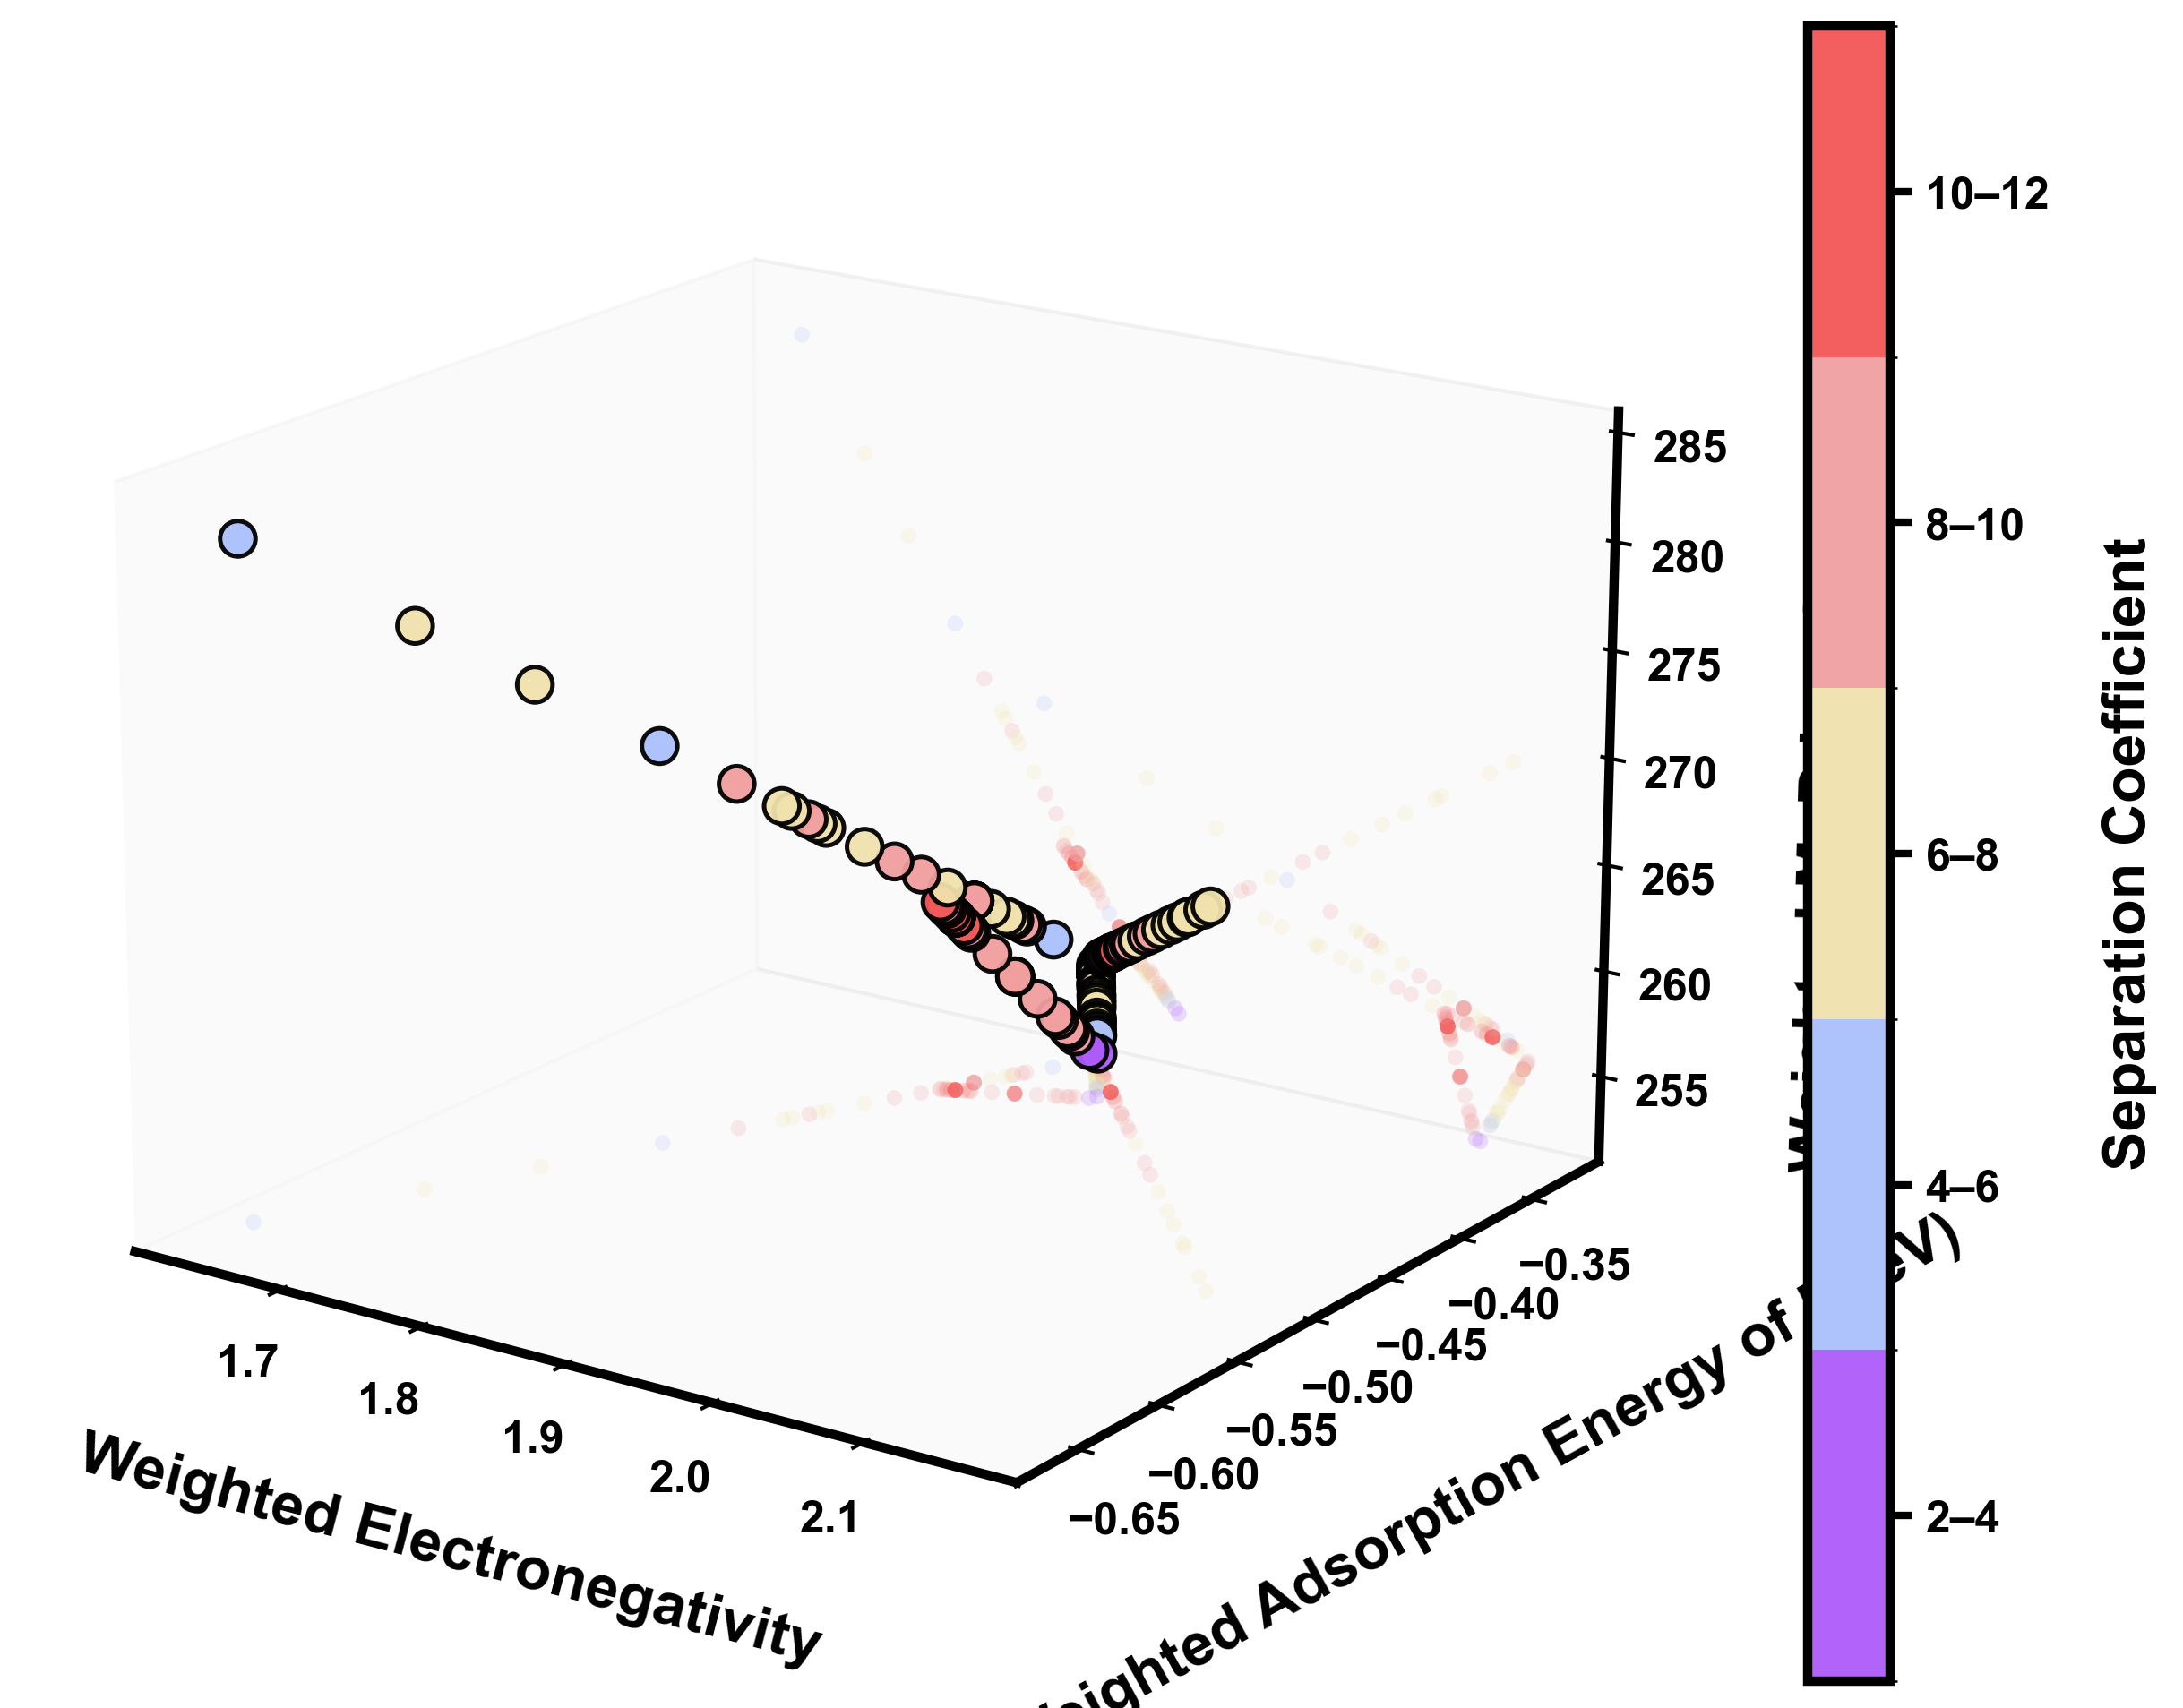

Saved: 3D_scatter_with_visible_plane_projections_bins2_palette5.png


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap, BoundaryNorm

# ============================================================
# 你需要保证 plot_df 已存在，例如：
# plot_df = df[["weighted_electronegativity","weighted_FE_ads_avg","weighted_M-D_bond_energy","separation_coefficient"]].dropna()
# ============================================================

# -------------------------
# 列名（按你的表格改这里）
# -------------------------
X_COL = "weighted_electronegativity"
Y_COL = "weighted_FE_ads_avg"
Z_COL = "weighted_M-D_bond_energy"
C_COL = "separation_coefficient"

df = plot_df[[X_COL, Y_COL, Z_COL, C_COL]].dropna().copy()
x = df[X_COL].to_numpy(float)
y = df[Y_COL].to_numpy(float)
z = df[Z_COL].to_numpy(float)
c = df[C_COL].to_numpy(float)

# =========================
# 颜色：每 2 一个 bin，五色与你之前一致
# =========================
PURPLE = "#AE5CFA"
BLUE   = "#AAC0FC"
YELLOW = "#F1E2AD"
ORANGE = "#F19FA0"
RED    = "#F35656"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]  # 低 -> 高

SC_BIN_START = 2.0
SC_BIN_END   = 12.0
SC_BIN_SIZE  = 2.0
boundaries = np.arange(SC_BIN_START, SC_BIN_END + SC_BIN_SIZE, SC_BIN_SIZE)  # [2,4,6,8,10,12]
cmap = ListedColormap(palette5)
norm = BoundaryNorm(boundaries, ncolors=cmap.N, clip=True)

c_plot = np.clip(c, boundaries[0] + 1e-9, boundaries[-1] - 1e-9)
tick_mids   = (boundaries[:-1] + boundaries[1:]) / 2
tick_labels = [f"{int(boundaries[i])}–{int(boundaries[i+1])}" for i in range(len(boundaries)-1)]

# =========================
# 风格
# =========================
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

SCATTER_SIZE  = 90
SCATTER_LW    = 1.2
SCATTER_ALPHA = 0.95

PROJ_SIZE  = 18
PROJ_ALPHA = 0.20   # 投影淡一些
EDGE_COLOR = "black"

# =========================
# 范围 + 投影面位置
# =========================
def pad_min(v, frac=0.06):
    r = np.nanmax(v) - np.nanmin(v)
    return np.nanmin(v) - frac * (r if r > 0 else 1.0)

def pad_max(v, frac=0.06):
    r = np.nanmax(v) - np.nanmin(v)
    return np.nanmax(v) + frac * (r if r > 0 else 1.0)

xmin, xmax = pad_min(x), pad_max(x)
ymin, ymax = pad_min(y), pad_max(y)
zmin, zmax = pad_min(z), pad_max(z)

# ✅ 关键：把投影放在更“可见”的面
# 你也可以改成 "min" 来放到另一侧
PROJ_FACE_X = "max"  # YZ 面: x = xmax（右面）
PROJ_FACE_Y = "max"  # XZ 面: y = ymax（更可见）
PROJ_FACE_Z = "min"  # XY 面: z = zmin（底面）

x_face = xmax if PROJ_FACE_X == "max" else xmin
y_face = ymax if PROJ_FACE_Y == "max" else ymin
z_face = zmin if PROJ_FACE_Z == "min" else zmax

# 为了让投影“贴在外侧”且不被面板遮住：轻微往外推一点，并把lim包含进去
dx = (xmax - xmin) * 0.01
dy = (ymax - ymin) * 0.01
dz = (zmax - zmin) * 0.01
x_face = x_face + (dx if PROJ_FACE_X == "max" else -dx)
y_face = y_face + (dy if PROJ_FACE_Y == "max" else -dy)
z_face = z_face + (-dz if PROJ_FACE_Z == "min" else dz)

# =========================
# 画图
# =========================
fig = plt.figure(figsize=(10, 8), dpi=300)
ax = fig.add_subplot(111, projection="3d")

# 背景 pane 透明一点，避免挡住投影
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.set_facecolor((0.97, 0.97, 0.97, 0.35))

ax.grid(False)

# 主 3D 散点
sc_main = ax.scatter(
    x, y, z,
    c=c_plot, cmap=cmap, norm=norm,
    s=SCATTER_SIZE,
    edgecolors=EDGE_COLOR,
    linewidths=SCATTER_LW,
    alpha=SCATTER_ALPHA,
    depthshade=False
)

# =========================
# 三个面上的二维投影（每个面就是一张二维图）
# =========================

# 1) XY 面：z = z_face，二维坐标 (x, y)
ax.scatter(
    x, y,
    zs=z_face, zdir="z",
    c=c_plot, cmap=cmap, norm=norm,
    s=PROJ_SIZE, alpha=PROJ_ALPHA,
    edgecolors="none", linewidths=0,
    depthshade=False
)

# 2) XZ 面：y = y_face，二维坐标 (x, z)
ax.scatter(
    x, z,
    zs=y_face, zdir="y",
    c=c_plot, cmap=cmap, norm=norm,
    s=PROJ_SIZE, alpha=PROJ_ALPHA,
    edgecolors="none", linewidths=0,
    depthshade=False
)

# 3) YZ 面：x = x_face，二维坐标 (y, z)
ax.scatter(
    y, z,
    zs=x_face, zdir="x",
    c=c_plot, cmap=cmap, norm=norm,
    s=PROJ_SIZE, alpha=PROJ_ALPHA,
    edgecolors="none", linewidths=0,
    depthshade=False
)

# 轴范围（包含投影面）
ax.set_xlim(min(xmin, x_face) - dx, max(xmax, x_face) + dx)
ax.set_ylim(min(ymin, y_face) - dy, max(ymax, y_face) + dy)
ax.set_zlim(min(zmin, z_face) - dz, max(zmax, z_face) + dz)

# 轴标题
ax.set_xlabel("Weighted Electronegativity", labelpad=18, fontsize=16, fontweight="bold")
ax.set_ylabel("Weighted Adsorption Energy of H (eV)", labelpad=20, fontsize=16, fontweight="bold")
ax.set_zlabel("Weighted M–D bond energy", labelpad=14, fontsize=16, fontweight="bold")

ax.tick_params(axis="both", which="major", labelsize=12, width=2, length=6)
ax.tick_params(axis="z", which="major", labelsize=12, width=2, length=6)

# 视角（你现在这个视角就可以）
ax.view_init(elev=18, azim=-55)

# 离散 colorbar
cb = fig.colorbar(sc_main, ax=ax, fraction=0.046, pad=0.06, ticks=tick_mids, boundaries=boundaries)
cb.ax.set_yticklabels(tick_labels)
cb.set_label("Separation Coefficient", fontsize=16, fontweight="bold", labelpad=14)
cb.ax.tick_params(labelsize=12, width=2, length=6)
cb.outline.set_linewidth(2.5)

out = "3D_scatter_with_visible_plane_projections_bins2_palette5.png"
plt.savefig(out, dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()
print("Saved:", out)





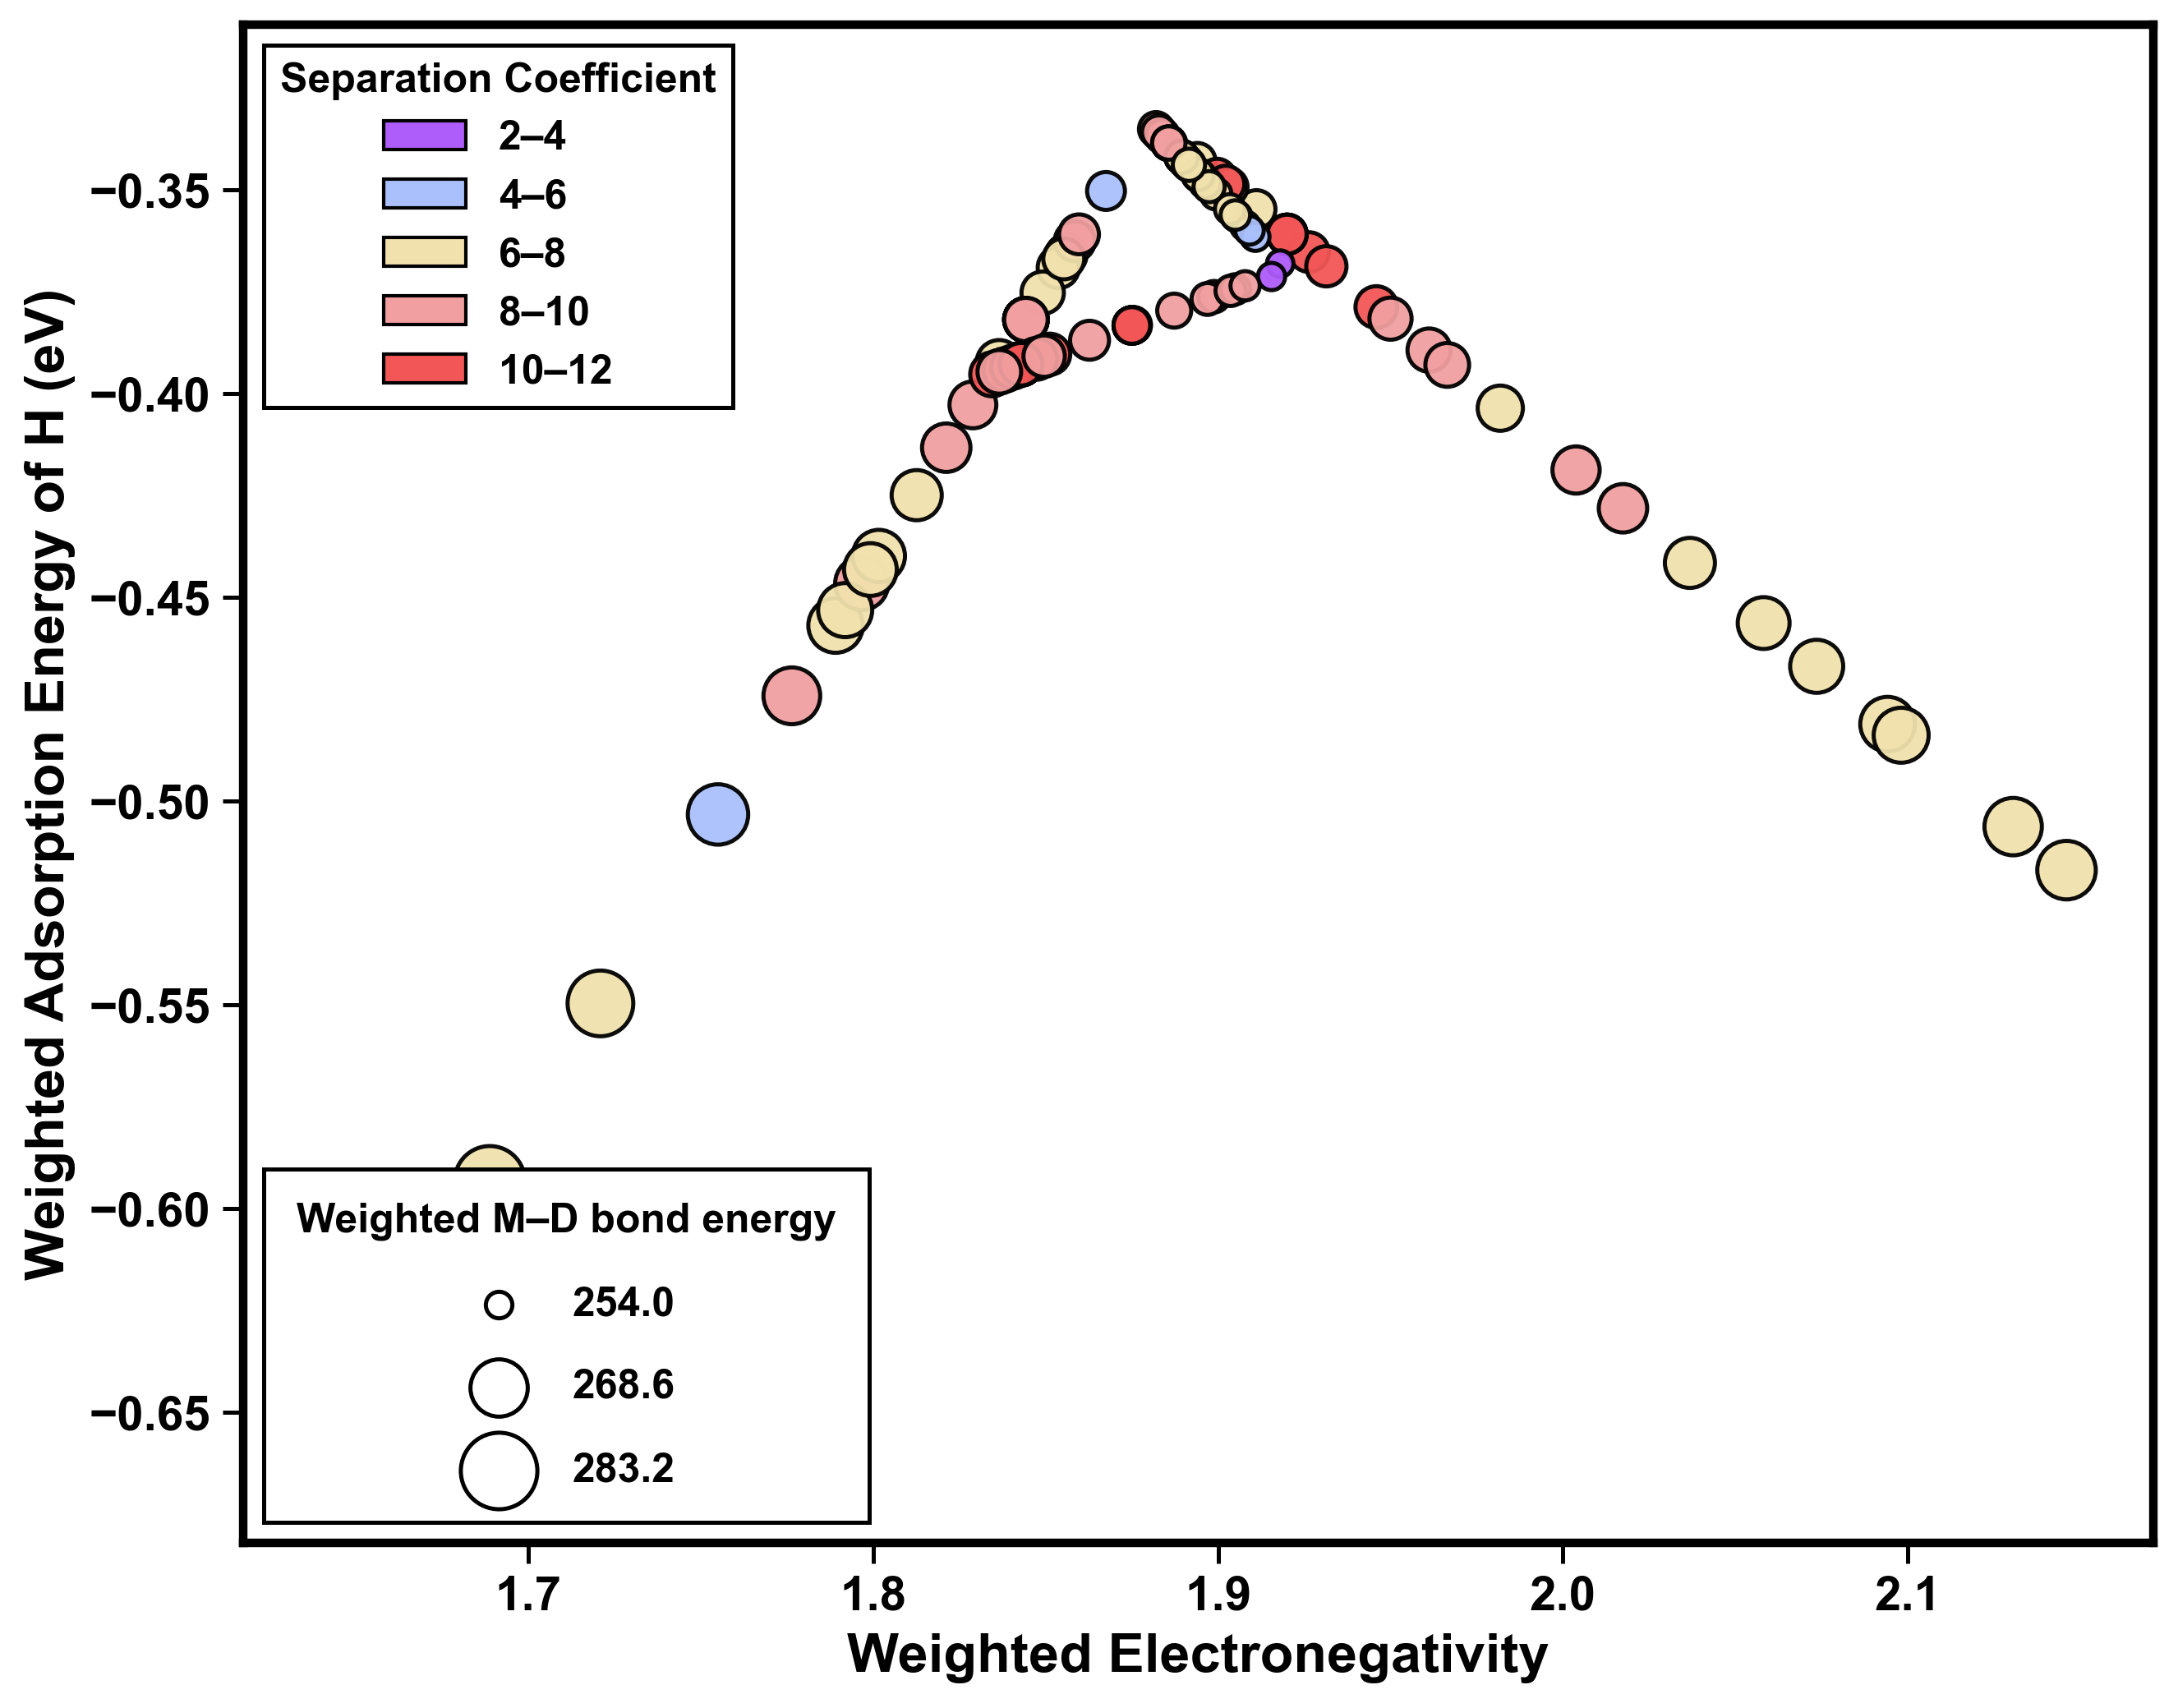

Saved: bubble_EN_vs_EH_size_MD_color_sepcoef.png


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# =========================
# 0) 列名（按你的实际列名改）
# =========================
X_COL = "weighted_electronegativity"
Y_COL = "weighted_FE_ads_avg"
S_COL = "weighted_M-D_bond_energy"   # 气泡大小
C_COL = "separation_coefficient"     # 颜色

df = plot_df[[X_COL, Y_COL, S_COL, C_COL]].dropna().copy()

x = df[X_COL].to_numpy(float)
y = df[Y_COL].to_numpy(float)
s_raw = df[S_COL].to_numpy(float)
c_raw = df[C_COL].to_numpy(float)

# =========================
# 1) 全局风格
# =========================
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.linewidth"] = 2.5

mpl.rcParams["xtick.labelsize"] = 14
mpl.rcParams["ytick.labelsize"] = 14
mpl.rcParams["axes.labelsize"]  = 16
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["xtick.major.width"] = 1.2
mpl.rcParams["ytick.major.width"] = 1.2
mpl.rcParams["xtick.major.size"]  = 6
mpl.rcParams["ytick.major.size"]  = 6

EDGE_COLOR = "black"
ALPHA = 0.95
LW = 1.2

# =========================
# 2) 颜色：Separation coefficient 每 2 一档（五色同之前）
# =========================
PURPLE = "#AE5CFA"
BLUE   = "#AAC0FC"
YELLOW = "#F1E2AD"
ORANGE = "#F19FA0"
RED    = "#F35656"
palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]  # 低 -> 高

BIN_START = 2.0
BIN_END   = 12.0
BIN_SIZE  = 2.0
boundaries = np.arange(BIN_START, BIN_END + BIN_SIZE, BIN_SIZE)  # [2,4,6,8,10,12]

cmap = ListedColormap(palette5)
norm = BoundaryNorm(boundaries, ncolors=cmap.N, clip=True)

# 把超范围值夹到边界内，避免色条异常
c_plot = np.clip(c_raw, boundaries[0] + 1e-9, boundaries[-1] - 1e-9)

# =========================
# 3) 气泡大小：用 MD 键能映射到面积（pt^2）
#    注意：Matplotlib 的 s 是“面积”，不是半径
# =========================
# 你可以调这两个，控制整体大小范围
S_MIN = 60    # 最小气泡面积
S_MAX = 500   # 最大气泡面积

s_min, s_max = np.nanmin(s_raw), np.nanmax(s_raw)
if np.isclose(s_max, s_min):
    s = np.full_like(s_raw, (S_MIN + S_MAX) / 2.0)
else:
    s = S_MIN + (s_raw - s_min) / (s_max - s_min) * (S_MAX - S_MIN)

# =========================
# 4) 作图
# =========================
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

sc = ax.scatter(
    x, y,
    s=s,
    c=c_plot,
    cmap=cmap,
    norm=norm,
    edgecolors=EDGE_COLOR,
    linewidths=LW,
    alpha=ALPHA,
    zorder=3
)

ax.set_xlabel("Weighted Electronegativity")
ax.set_ylabel("Weighted Adsorption Energy of H (eV)")
ax.grid(False)

# 让边距更舒服一点
ax.margins(x=0.05, y=0.08)

# =========================
# 5) 颜色图例（离散分箱）
# =========================
bin_labels = [f"{int(boundaries[i])}–{int(boundaries[i+1])}" for i in range(len(boundaries)-1)]
color_handles = [Patch(facecolor=palette5[i], edgecolor="black", linewidth=1.0, label=bin_labels[i])
                 for i in range(len(bin_labels))]

leg1 = ax.legend(
    handles=color_handles,
    title="Separation Coefficient",
    loc="upper left",
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1.0,
    fontsize=12,
    title_fontsize=12
)
leg1.get_frame().set_linewidth(1.2)
ax.add_artist(leg1)

# =========================
# 6) 气泡大小图例（MD bond energy）
# =========================
# 选 3 个代表值
s_vals = np.linspace(s_min, s_max, 3)
# 映射到面积
if np.isclose(s_max, s_min):
    s_area = [ (S_MIN + S_MAX) / 2.0 ] * 3
else:
    s_area = S_MIN + (s_vals - s_min) / (s_max - s_min) * (S_MAX - S_MIN)

size_handles = [
    plt.scatter([], [], s=s_area[i], facecolors="white", edgecolors="black", linewidths=1.2)
    for i in range(3)
]
size_labels = [f"{v:.1f}" if (abs(s_max - s_min) < 50) else f"{v:.0f}" for v in s_vals]

leg2 = ax.legend(
    size_handles, size_labels,
    title="Weighted M–D bond energy",
    loc="lower left",
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1.0,
    fontsize=12,
    title_fontsize=12,
    labelspacing=1.1,
    borderpad=0.8
)
leg2.get_frame().set_linewidth(1.2)

# =========================
# 7) 保存
# =========================
out = "bubble_EN_vs_EH_size_MD_color_sepcoef.png"
plt.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", out)


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# =========================
# 字体：Arial
# =========================
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"

# =========================
# 选择：用数据自动定 bins，还是固定区间
# =========================
USE_DATA_BINS = True

BIN_SIZE  = 2.0
BIN_START = 2.0
BIN_END   = 12.0

# 如果 USE_DATA_BINS=True，请确保 plot_df 已存在且含 separation_coefficient
# plot_df = df[["weighted_FE_ads_avg","weighted_electronegativity","separation_coefficient"]].dropna()

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    out = []
    for t in np.linspace(0, 1, n):
        out.append(mpl.colors.to_hex(c1 * (1 - t) + c2 * t))
    return out

def make_bin_colors(n_bins):
    palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]
    if n_bins <= 5:
        return palette5[:n_bins]

    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1

    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    return c01 + c12 + c23 + c34

# =========================
# 计算 bins
# =========================
if USE_DATA_BINS:
    c = plot_df["separation_coefficient"].to_numpy(dtype=float)
    cmin = np.nanmin(c)
    cmax = np.nanmax(c)

    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start, end = BIN_START, BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]
bin_colors = make_bin_colors(n_bins)

# =========================
# 生成 legend handles（最前面加 “Separation Coefficient” 文本项）
# =========================
prefix_handle = Line2D([], [], linestyle="None")  # 空 handle，只显示文字
handles = [prefix_handle]
labels  = ["Separation Coefficient"]

# 色块项
for i in range(n_bins):
    handles.append(Patch(facecolor=bin_colors[i], edgecolor="black", linewidth=0.8))
    labels.append(bin_labels[i])

# =========================
# 画布只放 legend：一行
# =========================
# 1个前缀 + n_bins 个色块
ncol = 1 + n_bins

fig_w = max(9.0, 1.05 * ncol + 10.0)  # 自动按列数加宽
fig = plt.figure(figsize=(fig_w, 1.1), dpi=300)
ax = fig.add_axes([0, 0, 1, 1])
ax.axis("off")

leg = ax.legend(
    handles=handles,
    labels=labels,
    loc="center",
    ncol=ncol,                 # ✅ 一行
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1.0,
    borderpad=0.35,
 
    handletextpad=0.45,
    columnspacing=1.4,
    prop={"family": "Arial", "weight": "bold", "size": 12},
)

# 让前缀项不占色块空间：把 handle 长度设为 0（只显示文字）
leg.legendHandles[0].set_visible(False)

# 边框线宽
leg.get_frame().set_linewidth(1.2)

out_png = "legend_sepcoef_bins_single_row_with_prefix.png"
out_svg = "legend_sepcoef_bins_single_row_with_prefix.svg"
fig.savefig(out_png, bbox_inches="tight", pad_inches=0.05)
fig.savefig(out_svg, bbox_inches="tight", pad_inches=0.05)
plt.close(fig)

print("Saved:", out_png, out_svg)



Saved: legend_sepcoef_bins_single_row_with_prefix.png legend_sepcoef_bins_single_row_with_prefix.svg


C:\Users\Admin\AppData\Local\Temp\ipykernel_38696\3030801171.py:121: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  leg.legendHandles[0].set_visible(False)


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle
from matplotlib.offsetbox import TextArea, DrawingArea, HPacker, AnchoredOffsetbox

# =========================
# 字体：Arial
# =========================
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"

# =========================
# 选择：用数据自动定 bins，还是固定区间
# =========================
USE_DATA_BINS = True

BIN_SIZE  = 2.0
BIN_START = 2.0
BIN_END   = 12.0

# 如果 USE_DATA_BINS=True，请确保 plot_df 已存在且含 separation_coefficient
# plot_df = df[["weighted_FE_ads_avg","weighted_electronegativity","separation_coefficient"]].dropna()

# =========================
# 颜色：紫 -> 蓝 -> 黄 -> 橙 -> 红（低饱和）
# =========================
RED    = "#F35656"
ORANGE = "#F19FA0"
YELLOW = "#F1E2AD"
BLUE   = "#AAC0FC"
PURPLE = "#AE5CFA"

def _interp_colors(hex1, hex2, n):
    c1 = np.array(mpl.colors.to_rgb(hex1))
    c2 = np.array(mpl.colors.to_rgb(hex2))
    if n <= 1:
        return [mpl.colors.to_hex(c1)]
    out = []
    for t in np.linspace(0, 1, n):
        out.append(mpl.colors.to_hex(c1 * (1 - t) + c2 * t))
    return out

def make_bin_colors(n_bins):
    palette5 = [PURPLE, BLUE, YELLOW, ORANGE, RED]
    if n_bins <= 5:
        return palette5[:n_bins]

    seg_lengths = [n_bins // 4] * 4
    for i in range(n_bins % 4):
        seg_lengths[i] += 1

    c01 = _interp_colors(PURPLE, BLUE,   seg_lengths[0] + 1)[:-1]
    c12 = _interp_colors(BLUE,   YELLOW, seg_lengths[1] + 1)[:-1]
    c23 = _interp_colors(YELLOW, ORANGE, seg_lengths[2] + 1)[:-1]
    c34 = _interp_colors(ORANGE, RED,    seg_lengths[3] + 1)
    return c01 + c12 + c23 + c34

# =========================
# 计算 bins
# =========================
if USE_DATA_BINS:
    c = plot_df["separation_coefficient"].to_numpy(dtype=float)
    cmin = np.nanmin(c)
    cmax = np.nanmax(c)
    start = BIN_SIZE * np.floor(cmin / BIN_SIZE)
    end   = BIN_SIZE * np.ceil(cmax / BIN_SIZE)
else:
    start, end = BIN_START, BIN_END

if end <= start:
    end = start + BIN_SIZE

bins_c = np.arange(start, end + BIN_SIZE, BIN_SIZE)
n_bins = len(bins_c) - 1

bin_labels = [f"{bins_c[i]:.0f}–{bins_c[i+1]:.0f}" for i in range(n_bins)]
bin_colors = make_bin_colors(n_bins)

# =========================
# 手工拼“一行图例”（无前置空格）
# =========================
FONT_SIZE = 10

# --- 可调间距参数（你想“间距大一些”就调这里） ---
SEP_BETWEEN_GROUPS = 35   # 每个“色块+文字”组之间的距离（越大越松）
SEP_PATCH_TEXT     = 10    # 色块与其文字之间的距离
FRAME_PAD          = 0.2 # 边框到内容的内边距（大一点更松）

# 色块尺寸（单位：像素，越大越显眼）
PATCH_W, PATCH_H = 34, 14
RECT_W,  RECT_H  = 30, 12

# 前缀文字（不会占用任何“handle列”，所以不会空一块）
items = [TextArea(
    "Separation Coefficient",
    textprops=dict(color="black", size=FONT_SIZE, weight="bold", family="Arial")
)]

# 色块 + 标签
for col, lab in zip(bin_colors, bin_labels):
    da = DrawingArea(PATCH_W, PATCH_H, 0, 0)
    rect = Rectangle((0, (PATCH_H-RECT_H)/2), RECT_W, RECT_H,
                     facecolor=col, edgecolor="black", linewidth=0.8)
    da.add_artist(rect)

    ta = TextArea(lab, textprops=dict(color="black", size=FONT_SIZE, weight="bold", family="Arial"))

    group = HPacker(children=[da, ta], align="center", pad=0, sep=SEP_PATCH_TEXT)
    items.append(group)

# 整体一行
row = HPacker(children=items, align="center", pad=0, sep=SEP_BETWEEN_GROUPS)

# =========================
# 画布只放这一行“图例”
# =========================
# 宽度可按项数粗略自适应
fig_w = max(9.0, 0.55 * (1 + n_bins) + 6.0)
fig = plt.figure(figsize=(fig_w, 0.3), dpi=300)
ax = fig.add_axes([0, 0, 1, 1])
ax.axis("off")

anch = AnchoredOffsetbox(
    loc="center",
    child=row,
    frameon=True,
    pad=FRAME_PAD,
    borderpad=0.6,
    bbox_to_anchor=(0.5, 0.5),
    bbox_transform=ax.transAxes
)
anch.patch.set_edgecolor("black")
anch.patch.set_linewidth(1.2)
anch.patch.set_facecolor("white")

ax.add_artist(anch)

out_png = "legend_sepcoef_single_row_no_leading_gap.png"
out_svg = "legend_sepcoef_single_row_no_leading_gap.svg"
fig.savefig(out_png, bbox_inches="tight", pad_inches=0.05)
fig.savefig(out_svg, bbox_inches="tight", pad_inches=0.05)
plt.close(fig)

print("Saved:", out_png, out_svg)


Saved: legend_sepcoef_single_row_no_leading_gap.png legend_sepcoef_single_row_no_leading_gap.svg


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle
from matplotlib.offsetbox import TextArea, DrawingArea, HPacker, VPacker, AnchoredOffsetbox

# =========================
# 字体：Arial
# =========================
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"

# =========================
# 这里直接固定 5 个 bin（2–4, 4–6, 6–8, 8–10, 10–12）
# 如果你想自动 bins，也可以把这里替换成你之前的 bins_c / bin_labels 逻辑
# =========================
bin_labels = ["2–4", "4–6", "6–8", "8–10", "10–12"]

# 低饱和：紫 -> 蓝 -> 黄 -> 橙 -> 红
PURPLE = "#AE5CFA"
BLUE   = "#AAC0FC"
YELLOW = "#F1E2AD"
ORANGE = "#F19FA0"
RED    = "#F35656"
bin_colors = [PURPLE, BLUE, YELLOW, ORANGE, RED]

# =========================
# 可调参数（布局/间距）
# =========================
FONT_SIZE = 12

SEP_BETWEEN_GROUPS = 18   # 同一行中每个“色块+文字”之间的间距
SEP_PATCH_TEXT     = 2   # 色块和文字之间的间距
ROW_GAP            = 8  # 行间距（title行 与 bins行、bins行之间）

FRAME_PAD   = 0.3        # 内容到边框的内边距
BORDER_PAD  = 0.35        # 边框 padding（整体更“扁长”就减小）

# 色块尺寸（像素）
PATCH_W, PATCH_H = 34, 14
RECT_W,  RECT_H  = 30, 12
RECT_LW = 1.0

# =========================
# 构造：第一行标题（单独一行）
# =========================
title = TextArea(
    "Separation Coefficient",
    textprops=dict(color="black", size=FONT_SIZE, weight="bold", family="Arial")
)

# =========================
# 构造：5 个“色块+文字”组
# =========================
groups = []
for col, lab in zip(bin_colors, bin_labels):
    da = DrawingArea(PATCH_W, PATCH_H, 0, 0)
    rect = Rectangle(
        (0, (PATCH_H - RECT_H) / 2),
        RECT_W, RECT_H,
        facecolor=col, edgecolor="black", linewidth=RECT_LW
    )
    da.add_artist(rect)

    ta = TextArea(
        lab,
        textprops=dict(color="black", size=FONT_SIZE, weight="bold", family="Arial")
    )

    groups.append(HPacker(children=[da, ta], align="center", pad=0, sep=SEP_PATCH_TEXT))

# =========================
# 让 5 个图标占 3 行：2 + 2 + 1
# =========================
row1 = HPacker(children=groups[0:2], align="center", pad=0, sep=SEP_BETWEEN_GROUPS)
row2 = HPacker(children=groups[2:4], align="center", pad=0, sep=SEP_BETWEEN_GROUPS)
row3 = HPacker(children=groups[4:5], align="center", pad=0, sep=SEP_BETWEEN_GROUPS)

# 整体：4 行（标题 + 3 行图标）
legend_box = VPacker(
    children=[title, row1, row2, row3],
    align="left",    # 左对齐：标题不会居中跑偏
    pad=0,
    sep=ROW_GAP
)

# =========================
# 画布只放图例
# =========================
fig = plt.figure(figsize=(9, 1.25), dpi=300)  # 想更“扁长”：增大宽、减小高
ax = fig.add_axes([0, 0, 1, 1])
ax.axis("off")

anch = AnchoredOffsetbox(
    loc="center",
    child=legend_box,
    frameon=True,
    pad=FRAME_PAD,
    borderpad=BORDER_PAD,
    bbox_to_anchor=(0.5, 0.5),
    bbox_transform=ax.transAxes
)
anch.patch.set_edgecolor("black")
anch.patch.set_linewidth(1.2)
anch.patch.set_facecolor("white")
ax.add_artist(anch)

out_png = "legend_sepcoef_title_1row_bins_3rows.png"
out_svg = "legend_sepcoef_title_1row_bins_3rows.svg"
fig.savefig(out_png, bbox_inches="tight", pad_inches=0.02)
fig.savefig(out_svg, bbox_inches="tight", pad_inches=0.02)
plt.close(fig)

print("Saved:", out_png, out_svg)



Saved: legend_sepcoef_title_1row_bins_3rows.png legend_sepcoef_title_1row_bins_3rows.svg


In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle

# =========================
# 字体：Arial
# =========================
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.weight"] = "bold"

# =========================
# 你要的文本 + bins + 颜色（按你之前那套：紫/蓝/黄/橙/红，低饱和）
# =========================
prefix = "Separation Coefficient"
labels = ["2–4", "4–6", "6–8", "8–10", "10–12"]
colors = ["#AE5CFA", "#AAC0FC", "#F1E2AD", "#F19FA0", "#F35656"]

# =========================
# 布局参数（想“间距大一些”就调这些）
# =========================
font_size = 12
border_lw = 1.6

gap_after_prefix = 0.030   # prefix 后到第一个色块的间距（不留空块，但留一点呼吸感）
gap_patch_text   = 0.014   # 色块与其文字之间
gap_item         = 0.030   # 每个 bin 之间的间距

patch_w = 0.050            # 色块宽度（轴坐标）
patch_h = 0.220            # 色块高度（轴坐标）
inner_left_pad  = 0.020    # 框内左边距
inner_right_pad = 0.020    # 框内右边距

# =========================
# 画布（可按需要改宽一点/窄一点）
# =========================
fig = plt.figure(figsize=(14, 1.15), dpi=300)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

# 外框
box_x0, box_y0 = 0.02, 0.18
box_w,  box_h  = 0.96, 0.64
ax.add_patch(Rectangle((box_x0, box_y0), box_w, box_h,
                       fill=False, edgecolor="black", linewidth=border_lw,
                       transform=ax.transAxes))

y = box_y0 + box_h / 2.0
x = box_x0 + inner_left_pad

# 先放 prefix
t_prefix = ax.text(x, y, prefix, va="center", ha="left",
                   fontsize=font_size, fontweight="bold",
                   transform=ax.transAxes)

# 用 renderer 精确测 prefix 文本宽度（保证不会“空一块”）
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transAxes.inverted()

bbox = t_prefix.get_window_extent(renderer=renderer)
x_right, _ = inv.transform((bbox.x1, bbox.y0))
x = x_right + gap_after_prefix  # ✅ prefix 之后直接开始放第一个色块

# 依次放：色块 + label
for lab, col in zip(labels, colors):
    # 色块
    ax.add_patch(Rectangle((x, y - patch_h/2), patch_w, patch_h,
                           facecolor=col, edgecolor="black", linewidth=1.0,
                           transform=ax.transAxes))
    # 文本
    x_text = x + patch_w + gap_patch_text
    t = ax.text(x_text, y, lab, va="center", ha="left",
                fontsize=font_size, fontweight="bold",
                transform=ax.transAxes)

    fig.canvas.draw()
    bbox2 = t.get_window_extent(renderer=renderer)
    x_right2, _ = inv.transform((bbox2.x1, bbox2.y0))

    x = x_right2 + gap_item

# 防止最后越界（如果你 bins 更多，可以把 figsize 加宽一点）
# 或者适当减小 gap_item / patch_w / font_size

out_png = "outputs/legend_sepcoef_single_row_no_blank.png"
out_svg = "outputs/legend_sepcoef_single_row_no_blank.svg"
fig.savefig(out_png, bbox_inches="tight", pad_inches=0.05)
fig.savefig(out_svg, bbox_inches="tight", pad_inches=0.05)
plt.close(fig)

print("Saved:", out_png, out_svg)
